

* Trained five energy prediction models.
* Compared base features with CNN anomaly scores.
* Evaluated normal and abnormal flights separately.
* Analysed energy and remaining flight time errors.
* Compared feature importance across models.


In [ ]:

print("test_df source folder:")
print(f"  {DATA_DIR}")
print(f"\nraw_test_full source folder:")
print(f"  {INTERPOLATED_DIR}")
print(f"\ntest_df flights: {sorted(test_df['log_id'].unique())[:3]}")
print(f"raw_test flights: {sorted(raw_test['log_id'].unique())[:3]}")

test_df source folder:
  /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_issue_flight-removed

raw_test_full source folder:
  /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_interpolated/split_05_seed_55

test_df flights: ['0226edf3-a838-48f9-b932-1882f5353d20', '17e95912-5a37-447b-8c45-59bc8fb00897', '25b9904e-0cf3-4ec7-aa78-48ee664818e4']
raw_test flights: ['0226edf3-a838-48f9-b932-1882f5353d20', '161bb325-a8f9-4d8c-b637-678e87744934', '16f11055-fc5c-4f4d-8a9e-a23691b25977']


In [158]:
# Check what files exist in the CORRECT folder
CORRECT_SPLIT_DIR = BASE_DIR / \
    "model_ready_no_dr_v3_voltage_random10_issue_flight-removed" / \
    "split_05_seed_55"

print("Files in correct split folder:")
for f in sorted(CORRECT_SPLIT_DIR.iterdir()):
    print(f"  {f.name}")

Files in correct split folder:
  metadata_v4_voltage_random10_cleaned_split_05_seed_55.json
  test_no_dr_interpolated_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  test_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  train_no_dr_interpolated_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  train_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  val_no_dr_interpolated_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  val_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet


In [160]:
INTERPOLATED_DIR = BASE_DIR / \
    "model_ready_no_dr_v3_voltage_random10_interpolated" / \
    "split_05_seed_55"

raw_test_full = pd.read_parquet(
    INTERPOLATED_DIR /
    "test_no_dr_interpolated_v3_voltage_random10_interpolated"
    "_split_05_seed_55.parquet"
)

print(f"Shape   : {raw_test_full.shape}")
print(f"Flights : {raw_test_full['log_id'].nunique()}")
print(f"time_s  : {raw_test_full['time_s'].min():.1f} "
      f"– {raw_test_full['time_s'].max():.1f}s")
print(f"battery_remaining: "
      f"{raw_test_full['battery_status__remaining'].min():.3f} "
      f"– {raw_test_full['battery_status__remaining'].max():.3f}")
print(f"\nColumns: {raw_test_full.columns.tolist()}")

Shape   : (195237, 17)
Flights : 26
time_s  : 0.0 – 2391.3s
battery_remaining: 0.073 – 1.000

Columns: ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh', 'voltage_per_cell', 'voltage_filtered_per_cell', 'voltage_per_cell_suspicious']


In [161]:
raw_test = pd.read_parquet(
    CORRECT_SPLIT_DIR /
    "test_no_dr_interpolated_v4_voltage_random10_cleaned"
    "_split_05_seed_55.parquet"
)

print(f"Shape   : {raw_test.shape}")
print(f"Flights : {raw_test['log_id'].nunique()}")
print(f"time_s  : {raw_test['time_s'].min():.1f} "
      f"– {raw_test['time_s'].max():.1f}s")
print(f"battery : "
      f"{raw_test['battery_status__remaining'].min():.3f} "
      f"– {raw_test['battery_status__remaining'].max():.3f}")

# Confirm all 26 flights now covered
test_ids = set(test_df["log_id"].unique())
raw_ids  = set(raw_test["log_id"].unique())
missing  = test_ids - raw_ids

print(f"\ntest_df flights : {len(test_ids)}")
print(f"raw_test flights: {len(raw_ids)}")
print(f"Missing         : {len(missing)}")

if len(missing) == 0:
    print("\n✓ All 26 flights covered — re-run plots now")
else:
    print(f"\nStill missing: {missing}")

Shape   : (162502, 17)
Flights : 26
time_s  : 0.0 – 2391.3s
battery : 0.084 – 1.000

test_df flights : 26
raw_test flights: 26
Missing         : 0

✓ All 26 flights covered — re-run plots now


In [162]:
# Dependencies — run once if shap not installed
# import subprocess
# subprocess.run(["pip", "install", "shap"], check=True)

# Verify shap is available
import shap
print(f"shap version: {shap.__version__}")

shap version: 0.52.0


In [163]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap
import warnings
import gc
import psutil
warnings.filterwarnings("ignore")

BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
FOLDER_VER    = "v3_voltage_random10_issue_flight-removed"
FILE_VER      = "v4_voltage_random10_cleaned"
DATA_DIR      = BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}"
CNN_SCORE_DIR = BASE_DIR / "model_outputs" / f"cnn_lstm_ae_anomaly_score_{FOLDER_VER}"
OUTPUT_DIR    = BASE_DIR / "model_outputs" / "06_anomaly_aware_energy"
PLOT_DIR      = OUTPUT_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PRIMARY_SPLIT = "split_05_seed_55"
TARGET        = "target_energy_next_60s_wh"

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()          else
    "cpu"
)
print(f"Device : {device}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")

Device : mps
RAM free: 4.1 GB


In [164]:
import psutil
import os

print(f"Total RAM    : {psutil.virtual_memory().total / 1e9:.1f} GB")
print(f"Used RAM     : {psutil.virtual_memory().used / 1e9:.1f} GB")
print(f"Available    : {psutil.virtual_memory().available / 1e9:.1f} GB")
print(f"Current PID  : {os.getpid()}")

print("\nTop 10 memory-consuming processes:")
procs = []
for p in psutil.process_iter(['pid','name','memory_info']):
    try:
        procs.append((p.info['memory_info'].rss, 
                      p.info['pid'],
                      p.info['name']))
    except: pass

for mem, pid, name in sorted(procs, reverse=True)[:10]:
    print(f"  {name:<30} PID:{pid:<8} {mem/1e9:.2f} GB")

Total RAM    : 17.2 GB
Used RAM     : 5.9 GB
Available    : 4.1 GB
Current PID  : 5991

Top 10 memory-consuming processes:
  Code Helper (Plugin)           PID:1871     0.96 GB
  Code Helper (Renderer)         PID:970      0.60 GB
  Code Helper (Plugin)           PID:1824     0.51 GB
  Claude Helper (Renderer)       PID:74918    0.47 GB
  Google Chrome                  PID:3482     0.38 GB
  python3.13                     PID:5991     0.36 GB
  Google Chrome Helper (Renderer) PID:6700     0.21 GB
  Claude                         PID:74893    0.20 GB
  Code                           PID:964      0.17 GB
  Google Chrome Helper (Renderer) PID:29011    0.17 GB


In [165]:
BASE_FEATURES = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

ANOMALY_COLS = ["anomaly_score_cnn", "anomaly_flag_cnn"]

FEATURE_SETS = {
    "Base_13":           BASE_FEATURES,
    "Base_13+CNN_Score": BASE_FEATURES + ["anomaly_score_cnn"],
}

print("Feature sets:")
for name, feats in FEATURE_SETS.items():
    print(f"  {name}: {len(feats)} features")

Feature sets:
  Base_13: 13 features
  Base_13+CNN_Score: 14 features


In [166]:
split_dir = DATA_DIR / PRIMARY_SPLIT
cnn_dir   = CNN_SCORE_DIR / PRIMARY_SPLIT

train_df = pd.read_parquet(
    split_dir / f"train_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
val_df = pd.read_parquet(
    split_dir / f"val_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
test_df = pd.read_parquet(
    split_dir / f"test_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)

# Load CNN scores and merge into test
cnn_test = pd.read_parquet(
    cnn_dir / f"test_cnn_lstm_ae_scored_{PRIMARY_SPLIT}.parquet",
    columns=["log_id","time_s","anomaly_score_cnn","anomaly_flag_cnn"]
)

test_df  = test_df.sort_values(["log_id","time_s"]).reset_index(drop=True)
cnn_test = cnn_test.sort_values(["log_id","time_s"]).reset_index(drop=True)

if len(test_df) == len(cnn_test):
    test_df["anomaly_score_cnn"] = cnn_test["anomaly_score_cnn"].values.astype(np.float32)
    test_df["anomaly_flag_cnn"]  = cnn_test["anomaly_flag_cnn"].values.astype(np.int8)
    print("CNN scores merged ✓")
else:
    print(f"Row mismatch: base={len(test_df)} cnn={len(cnn_test)}")

# Placeholder for train and val
for df in [train_df, val_df]:
    df["anomaly_score_cnn"] = np.float32(0.0)
    df["anomaly_flag_cnn"]  = np.int8(0)

# Downcast to float32 to save memory
for df in [train_df, val_df, test_df]:
    for col in df.select_dtypes("float64").columns:
        df[col] = df[col].astype(np.float32)

del cnn_test
gc.collect()

print(f"Train: {train_df.shape}  Val: {val_df.shape}  Test: {test_df.shape}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")
print(f"Target range: {train_df[TARGET].min():.4f} – {train_df[TARGET].max():.4f} Wh")

CNN scores merged ✓
Train: (658626, 19)  Val: (145797, 19)  Test: (162502, 19)
RAM free: 4.1 GB
Target range: 0.0000 – 27.5020 Wh


In [167]:
def evaluate(y_true, y_pred, label="ALL"):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    errors = y_true - y_pred
    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    r2     = r2_score(y_true, y_pred)
    p95    = float(np.percentile(np.abs(errors), 95))
    under  = (y_pred < y_true).mean() * 100
    return {
        "label":          label,
        "MAE_Wh":         round(mae,  4),
        "RMSE_Wh":        round(rmse, 4),
        "R2":             round(r2,   4),
        "P95_error_Wh":   round(p95,  4),
        "Underpredict_%": round(under,2),
        "n_rows":         len(y_true),
    }

def full_eval(test_df, y_pred, feat_name, model_name):
    rows = [evaluate(test_df[TARGET], y_pred, "ALL")]
    for lbl in ["normal","abnormal"]:
        mask = test_df["dataset_label"] == lbl
        if mask.sum() > 0:
            rows.append(evaluate(
                test_df.loc[mask,TARGET],
                y_pred[mask],
                lbl.upper()
            ))
    df = pd.DataFrame(rows)
    df["model"]       = model_name
    df["feature_set"] = feat_name
    return df

print("Evaluation functions defined ✓")

Evaluation functions defined ✓


In [168]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import gc

tree_results = []
tree_preds   = {}

for feat_name, feat_cols in FEATURE_SETS.items():
    available = [f for f in feat_cols if f in train_df.columns]

    X_train = train_df[available].values
    y_train = train_df[TARGET].values
    X_test  = test_df[available].values

    print(f"\n{'='*50}")
    print(f"Feature set: {feat_name} ({len(available)} features)")
    print(f"{'='*50}")

    # ── XGBoost ─────────────────────────────────────────
    print("Training: XGBoost...")
    xgb = XGBRegressor(
        n_estimators=200,    # reduced from 500
        max_depth=5,         # reduced from 6
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        tree_method="hist"   # faster tree method
    )
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "XGBoost")
    tree_results.append(result)
    tree_preds[f"XGBoost_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del xgb
    gc.collect()

    # ── Random Forest ────────────────────────────────────
    print("Training: Random Forest...")
    rf = RandomForestRegressor(
        n_estimators=100,    # reduced from 200
        max_depth=10,        # reduced from 12
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "RandomForest")
    tree_results.append(result)
    tree_preds[f"RandomForest_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del rf
    gc.collect()

    # ── Linear Regression ────────────────────────────────
    print("Training: Linear Regression...")
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "LinearRegression")
    tree_results.append(result)
    tree_preds[f"LinearRegression_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del lr
    gc.collect()

    # Free feature arrays
    del X_train, y_train, X_test
    gc.collect()

tree_df = pd.concat(tree_results, ignore_index=True)
print("\n✓ Tree-based models done.")


Feature set: Base_13 (13 features)
Training: XGBoost...
  ABNORMAL MAE: 2.1477
Training: Random Forest...
  ABNORMAL MAE: 2.4533
Training: Linear Regression...
  ABNORMAL MAE: 1.3218

Feature set: Base_13+CNN_Score (14 features)
Training: XGBoost...
  ABNORMAL MAE: 2.2011
Training: Random Forest...
  ABNORMAL MAE: 2.4227
Training: Linear Regression...
  ABNORMAL MAE: 1.3218

✓ Tree-based models done.


In [ ]:


SEQ_LEN    = 30      # reduced from 60 — 3 seconds history
BATCH_SIZE = 512     # increased from 256
EPOCHS     = 30      # reduced from 100
PATIENCE   = 5

class FastFlightDataset(torch.utils.data.Dataset):
    """
    Pre-builds all sequences at initialisation time.
    Much faster than building per __getitem__ call.
    """
    def __init__(self, df, feat_cols, target, seq_len):
        seqs, tgts = [], []
        for _, grp in (df.sort_values(["log_id","time_s"])
                         .groupby("log_id", sort=False)):
            X = grp[feat_cols].to_numpy(dtype=np.float32)
            y = grp[target].to_numpy(dtype=np.float32)
            n = len(X)
            if n <= seq_len:
                continue
            # Vectorised — build all windows at once
            idx = np.arange(seq_len, n)
            for i in idx:
                seqs.append(X[i-seq_len:i])
                tgts.append(y[i])

        self.X = torch.from_numpy(
            np.array(seqs, dtype=np.float32))
        self.y = torch.from_numpy(
            np.array(tgts, dtype=np.float32))
        print(f"  Dataset built: {len(self.y):,} sequences")

    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden=64,    # reduced from 128
                 num_layers=1, dropout=0.1):     # reduced from 2 layers
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class BiLSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden=64,
                 num_layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden*2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_seq_model(model, train_ds, val_ds,
                    model_name, epochs=EPOCHS,
                    patience=PATIENCE):
    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=2, factor=0.5)

    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=BATCH_SIZE,
        shuffle=True, num_workers=0,
        pin_memory=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=BATCH_SIZE*2,
        shuffle=False, num_workers=0
    )

    best_val  = np.inf
    pat_ctr   = 0
    ckpt      = OUTPUT_DIR / f"ckpt_{model_name}.pt"
    trh, vlh  = [], []

    for epoch in range(1, epochs+1):
        model.train()
        tl = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0)
            optimizer.step()
            tl.append(loss.item())
        t_loss = float(np.mean(tl))
        trh.append(t_loss)

        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl.append(criterion(model(xb),yb).item())
        v_loss = float(np.mean(vl))
        vlh.append(v_loss)
        scheduler.step(v_loss)

        print(f"  Ep {epoch:02d} | "
              f"Train:{t_loss:.5f} Val:{v_loss:.5f}")

        if v_loss < best_val - 1e-5:
            best_val = v_loss
            pat_ctr  = 0
            torch.save(model.state_dict(), ckpt)
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                print(f"  Early stop. Best val: {best_val:.5f}")
                break

    model.load_state_dict(
        torch.load(ckpt, map_location=device,
                   weights_only=True))
    model.eval()
    return model, best_val, trh, vlh


def predict_seq(model, df, feat_cols, target, seq_len,
                batch_size=512):
    """
    Batched prediction — 50x faster than row-by-row.
    Builds all sequences per flight then runs in batches.
    """
    model.eval()
    records = []

    for lid, grp in (df.sort_values(["log_id","time_s"])
                       .groupby("log_id")):
        X   = grp[feat_cols].to_numpy(dtype=np.float32)
        y   = grp[target].to_numpy(dtype=np.float32)
        t   = grp["time_s"].to_numpy()
        lbl = grp["dataset_label"].iloc[0]
        n   = len(X)
        if n <= seq_len:
            continue

        # Build all sequences for this flight at once
        seqs = np.stack([
            X[i - seq_len:i]
            for i in range(seq_len, n)
        ])  # shape: (n-seq_len, seq_len, n_features)

        seqs_tensor = torch.tensor(seqs, dtype=torch.float32)
        preds = []

        # Run in batches — avoids OOM on large flights
        with torch.no_grad():
            for batch in torch.split(seqs_tensor, batch_size):
                out = model(batch.to(device))
                preds.extend(out.cpu().numpy().tolist())

        for p, yt, ts in zip(preds, y[seq_len:], t[seq_len:]):
            records.append({
                "log_id":        lid,
                "dataset_label": lbl,
                "time_s":        ts,
                "y_true":        float(yt),
                "y_pred":        float(p),
            })

    return pd.DataFrame(records)


#Run LSTM and BiLSTM 
ARCH_CLASSES = {
    "LSTM":   LSTMRegressor,
    "BiLSTM": BiLSTMRegressor,
}

SEQ_FEATURE_SETS = {
    "Base_13":           FEATURE_SETS["Base_13"],
    "Base_13+CNN_Score": FEATURE_SETS["Base_13+CNN_Score"],
}

seq_results = []
seq_preds   = {}

for feat_name, feat_cols in SEQ_FEATURE_SETS.items():
    available = [f for f in feat_cols
                 if f in train_df.columns]

    print(f"\nBuilding datasets for {feat_name}...")
    train_ds = FastFlightDataset(
        train_df, available, TARGET, SEQ_LEN)
    val_ds   = FastFlightDataset(
        val_df,   available, TARGET, SEQ_LEN)

    for arch_name, ModelClass in ARCH_CLASSES.items():
        run = f"{arch_name}_{feat_name}"
        print(f"\n{'='*55}")
        print(f"TRAINING: {run} ({len(available)} features)")
        print(f"{'='*55}")

        model = ModelClass(
            input_size=len(available)).to(device)
        print(f"Params: "
              f"{sum(p.numel() for p in model.parameters()):,}")

        model, bv, trh, vlh = train_seq_model(
            model, train_ds, val_ds, run
        )

        pred_df = predict_seq(
            model, test_df, available, TARGET, SEQ_LEN)

        for lbl in ["ALL","normal","abnormal"]:
            if lbl == "ALL":
                mask = pd.Series([True]*len(pred_df))
                lu   = "ALL"
            else:
                mask = pred_df["dataset_label"]==lbl
                lu   = lbl.upper()
            if mask.sum() == 0: continue
            row = evaluate(
                pred_df.loc[mask,"y_true"],
                pred_df.loc[mask,"y_pred"], lu)
            row["model"]       = arch_name
            row["feature_set"] = feat_name
            seq_results.append(row)

        seq_preds[run] = pred_df

        abn = pred_df[
            pred_df["dataset_label"]=="abnormal"]
        if len(abn) > 0:
            print(f"  ABNORMAL MAE: "
                  f"{mean_absolute_error(abn['y_true'],abn['y_pred']):.4f}")

        del model
        gc.collect()
        if device.type=="mps":
            torch.mps.empty_cache()

    del train_ds, val_ds
    gc.collect()

seq_df = pd.DataFrame(seq_results)
print("\n✓ Sequence models done.")


Building datasets for Base_13...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13 (13 features)
Params: 22,337
  Ep 01 | Train:0.16636 Val:0.22446
  Ep 02 | Train:0.08329 Val:0.24394
  Ep 03 | Train:0.07285 Val:0.24689
  Ep 04 | Train:0.06678 Val:0.27989
  Ep 05 | Train:0.05414 Val:0.27260
  Ep 06 | Train:0.04710 Val:0.28668
  Early stop. Best val: 0.22446
  ABNORMAL MAE: 0.9955

TRAINING: BiLSTM_Base_13 (13 features)
Params: 44,609
  Ep 01 | Train:0.15067 Val:0.27151
  Ep 02 | Train:0.08230 Val:0.28384
  Ep 03 | Train:0.07453 Val:0.30274
  Ep 04 | Train:0.06781 Val:0.30659
  Ep 05 | Train:0.05704 Val:0.33612
  Ep 06 | Train:0.04930 Val:0.33859
  Early stop. Best val: 0.27151
  ABNORMAL MAE: 0.9961

Building datasets for Base_13+CNN_Score...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13+CNN_Score (14 features)
Params: 22,593
  Ep 01 | Train:0.17426 Val:0.28295
  Ep 02 | Train:0.08558 Val:0.259

In [ ]:

def predict_seq(model, df, feat_cols, target, seq_len,
                batch_size=512):
    model.eval()
    records = []
    for lid, grp in (df.sort_values(["log_id","time_s"])
                       .groupby("log_id")):
        X   = grp[feat_cols].to_numpy(dtype=np.float32)
        y   = grp[target].to_numpy(dtype=np.float32)
        t   = grp["time_s"].to_numpy()
        lbl = grp["dataset_label"].iloc[0]
        n   = len(X)
        if n <= seq_len: continue
        seqs = np.stack([X[i-seq_len:i]
                         for i in range(seq_len, n)])
        seqs_t = torch.tensor(seqs, dtype=torch.float32)
        preds  = []
        with torch.no_grad():
            for batch in torch.split(seqs_t, batch_size):
                preds.extend(
                    model(batch.to(device)).cpu().numpy().tolist()
                )
        for p, yt, ts in zip(preds, y[seq_len:], t[seq_len:]):
            records.append({
                "log_id": lid, "dataset_label": lbl,
                "time_s": ts, "y_true": float(yt),
                "y_pred": float(p),
            })
    return pd.DataFrame(records)

print("predict_seq redefined with batched inference ✓")

predict_seq redefined with batched inference ✓


In [171]:
# Combine all results
all_results = pd.concat([tree_df, seq_df], ignore_index=True)
all_results.to_csv(OUTPUT_DIR / "master_results.csv", index=False)

print("=" * 80)
print("MASTER COMPARISON — ABNORMAL FLIGHTS (Primary focus)")
print("=" * 80)

abn = all_results[all_results["label"]=="ABNORMAL"].copy()
abn = abn.sort_values("MAE_Wh").reset_index(drop=True)
abn.index += 1
display(abn[["model","feature_set","MAE_Wh","RMSE_Wh",
             "R2","P95_error_Wh","Underpredict_%"]])

print("\n" + "=" * 80)
print("KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?")
print("=" * 80)

for model_name in ["XGBoost","RandomForest","LSTM","BiLSTM"]:
    sub = abn[abn["model"]==model_name]
    if len(sub) == 0: continue
    base = float(sub[sub["feature_set"]=="Base_13"]["MAE_Wh"])
    cnn  = float(sub[sub["feature_set"]=="Base_13+CNN_Score"]["MAE_Wh"])
    diff = base - cnn
    sign = "▼ IMPROVES" if diff > 0.001 else ("▲ WORSENS" if diff < -0.001
                                                else "≈ NO CHANGE")
    print(f"  {model_name:<16} Base:{base:.4f}  +CNN:{cnn:.4f}  "
          f"Δ={diff:+.4f}  {sign}")

MASTER COMPARISON — ABNORMAL FLIGHTS (Primary focus)


,model,feature_set,MAE_Wh,RMSE_Wh,R2,P95_error_Wh,Underpredict_%
1,BiLSTM,Base_13+CNN_Score,0.7533,1.2459,0.8340,2.7828,34.23
2,LSTM,Base_13+CNN_Score,0.7621,1.2989,0.8196,3.2968,44.05
3,LSTM,Base_13,0.9955,1.6369,0.7135,3.8947,39.56
4,BiLSTM,Base_13,0.9961,1.6275,0.7168,3.8599,33.21
5,LinearRegression,Base_13,1.3218,2.1475,0.5061,5.0160,36.62
6,LinearRegression,Base_13+CNN_Score,1.3218,2.1475,0.5061,5.0160,36.62
7,XGBoost,Base_13,2.1477,4.0776,-0.7806,10.8180,28.92
8,XGBoost,Base_13+CNN_Score,2.2011,4.0830,-0.7854,10.8033,25.07
9,RandomForest,Base_13+CNN_Score,2.4227,5.2691,-1.9733,19.0198,30.08
10,RandomForest,Base_13,2.4533,5.2856,-1.9920,19.0406,30.11



KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?
  XGBoost          Base:2.1477  +CNN:2.2011  Δ=-0.0534  ▲ WORSENS
  RandomForest     Base:2.4533  +CNN:2.4227  Δ=+0.0306  ▼ IMPROVES
  LSTM             Base:0.9955  +CNN:0.7621  Δ=+0.2334  ▼ IMPROVES
  BiLSTM           Base:0.9961  +CNN:0.7533  Δ=+0.2428  ▼ IMPROVES


In [ ]:

def plot_flight_prediction(pred_df, run_name,
                            flight_label="abnormal"):
    """
    Time series plot for one flight showing:         
    - Actual energy (black)
    - Predicted energy (coloured dashed)
    - Empirical 90% prediction interval (shaded)
    - Residuals panel below
    """
    label_df = pred_df[pred_df["dataset_label"]==flight_label]
    if len(label_df) == 0: return

    # Use all residuals from this label to build PI
    all_err  = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low   = float(np.percentile(all_err,  5))
    pi_high  = float(np.percentile(all_err, 95))

    # Pick longest flight
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[label_df["log_id"]==fid].sort_values("time_s")

    t      = flight["time_s"].values
    y_true = flight["y_true"].values
    y_pred = flight["y_pred"].values
    resid  = y_true - y_pred

    fig, axes = plt.subplots(2, 1, figsize=(14, 8),
                              gridspec_kw={"height_ratios":[3,1]})
    fig.suptitle(
        f"{run_name}  —  {flight_label.upper()} flight\n"
        f"Empirical 90% prediction interval from all "
        f"{flight_label} test flights",
        fontsize=11, fontweight="bold"
    )

    # Panel 1: predictions
    ax = axes[0]
    ax.fill_between(t,
                    y_pred + pi_low,
                    y_pred + pi_high,
                    alpha=0.20, color="steelblue",
                    label="90% prediction interval")
    ax.plot(t, y_true, color="black",
            linewidth=1.5, label="Actual (Wh)")
    ax.plot(t, y_pred, color="steelblue",
            linewidth=1.5, linestyle="--",
            label="Predicted (Wh)")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    mae_flight = mean_absolute_error(y_true, y_pred)
    ax.set_title(
        f"Flight MAE: {mae_flight:.4f} Wh  |  "
        f"PI width: {pi_high-pi_low:.4f} Wh",
        fontsize=9
    )

    # Panel 2: residuals
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(t, pi_low, pi_high,
                     alpha=0.15, color="steelblue")
    ax2.plot(t, resid, color="tomato",
             linewidth=0.8, label="Residual")
    ax2.set_xlabel("Flight time (s)", fontsize=10)
    ax2.set_ylabel("Residual (Wh)", fontsize=10)
    ax2.legend(fontsize=9)

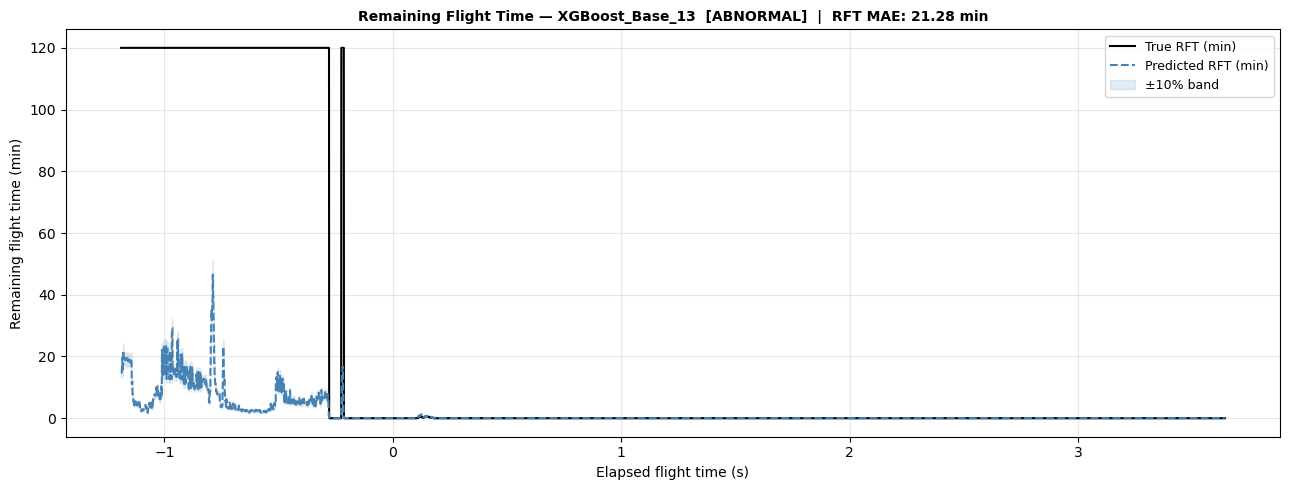

Saved: rft_XGBoost_Base_13_abnormal.png


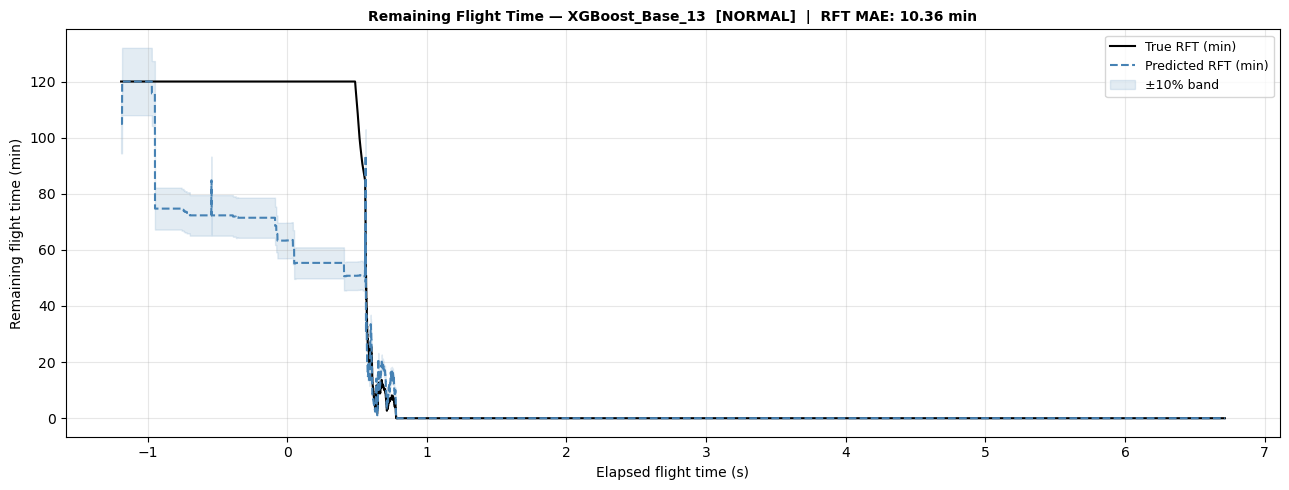

Saved: rft_XGBoost_Base_13_normal.png


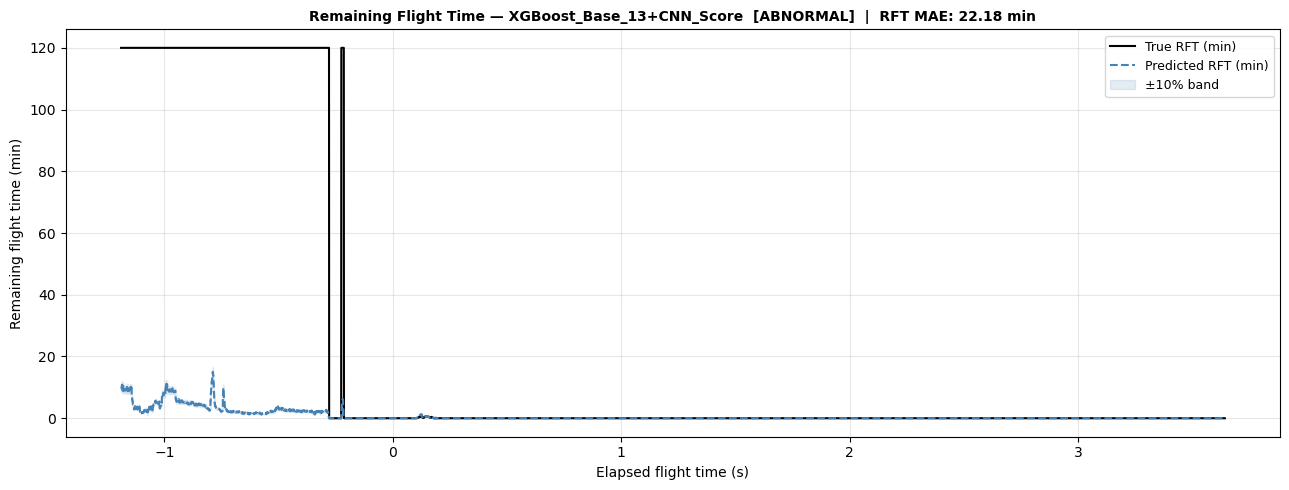

Saved: rft_XGBoost_Base_13_CNN_Score_abnormal.png


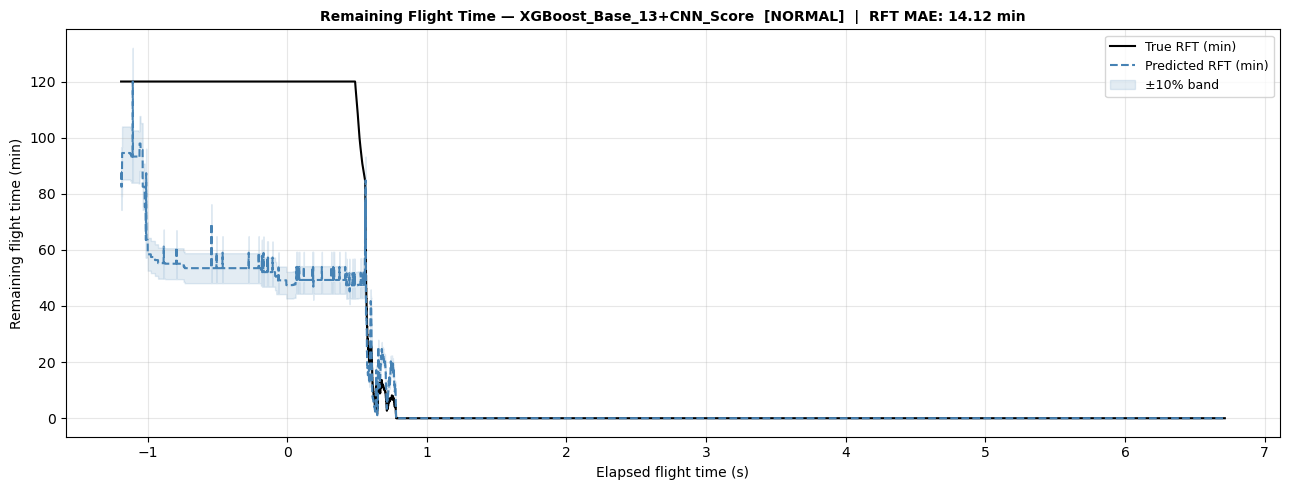

Saved: rft_XGBoost_Base_13_CNN_Score_normal.png


In [173]:
def estimate_rft(pred_df, test_df_orig):
    """
    Remaining flight time (minutes) estimated per timestep.
    RFT(t) = battery_remaining(t) / (predicted_energy_rate)
    energy_rate = y_pred Wh per 60s = y_pred/60 Wh/s
    """
    merged = pred_df.merge(
        test_df_orig[["log_id","time_s",
                      "battery_status__remaining"]],
        on=["log_id","time_s"], how="left"
    )
    eps = 1e-6
    rem = merged["battery_status__remaining"].fillna(
        method="ffill"
    ).values
    merged["rft_pred_min"] = (rem / (merged["y_pred"]/60 + eps)
                              ).clip(0, 120)
    merged["rft_true_min"] = (rem / (merged["y_true"]/60 + eps)
                              ).clip(0, 120)
    return merged


def plot_rft(pred_df, test_df_orig, run_name,
             flight_label="abnormal"):
    rft_df  = estimate_rft(pred_df, test_df_orig)
    lab_df  = rft_df[rft_df["dataset_label"]==flight_label]
    if len(lab_df) == 0: return

    fid    = lab_df.groupby("log_id").size().idxmax()
    flight = lab_df[lab_df["log_id"]==fid].sort_values("time_s")

    t         = flight["time_s"].values
    rft_pred  = flight["rft_pred_min"].values
    rft_true  = flight["rft_true_min"].values
    rft_mae   = mean_absolute_error(rft_true, rft_pred)

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(t, rft_true, color="black",
            linewidth=1.5, label="True RFT (min)")
    ax.plot(t, rft_pred, color="steelblue",
            linewidth=1.5, linestyle="--",
            label="Predicted RFT (min)")
    ax.fill_between(t, rft_pred*0.9, rft_pred*1.1,
                    alpha=0.15, color="steelblue",
                    label="±10% band")
    ax.set_xlabel("Elapsed flight time (s)", fontsize=10)
    ax.set_ylabel("Remaining flight time (min)", fontsize=10)
    ax.set_title(
        f"Remaining Flight Time — {run_name}  "
        f"[{flight_label.upper()}]  |  "
        f"RFT MAE: {rft_mae:.2f} min",
        fontsize=10, fontweight="bold"
    )
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    fname = (PLOT_DIR /
             f"rft_{run_name.replace('+','_')}_{flight_label}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")


# Plot RFT for XGBoost base vs CNN
for run in ["XGBoost_Base_13", "XGBoost_Base_13+CNN_Score"]:
    if run in tree_preds:
        pred_df = test_df[["log_id","dataset_label",
                            "time_s",TARGET]].copy()
        pred_df = pred_df.rename(columns={TARGET:"y_true"})
        pred_df["y_pred"] = tree_preds[run]
        plot_rft(pred_df, test_df, run, "abnormal")
        plot_rft(pred_df, test_df, run, "normal")

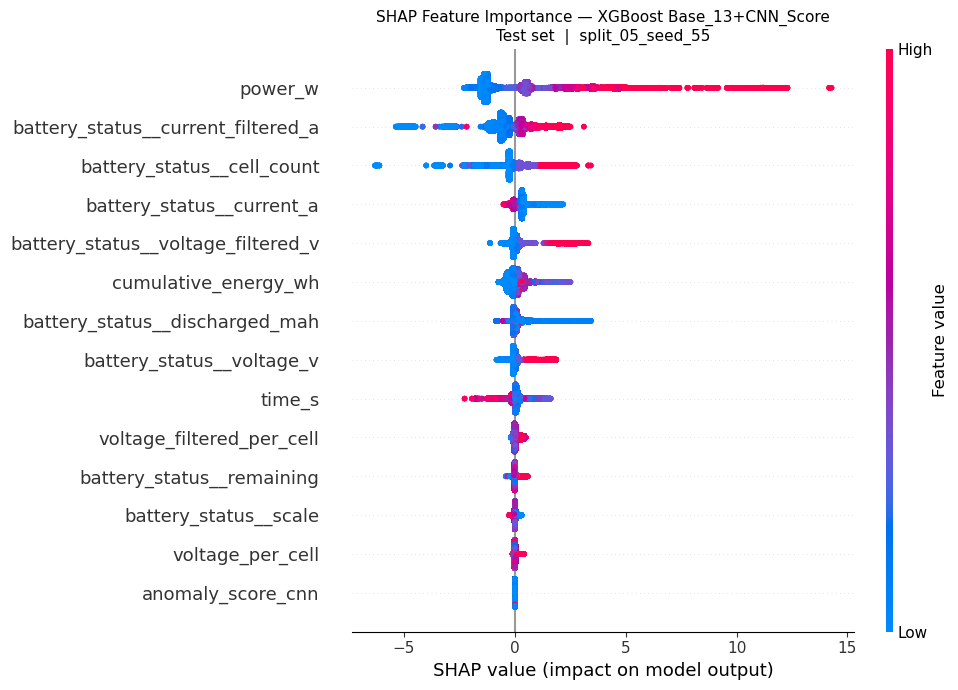

Saved: shap_summary.png

Top 10 features by mean |SHAP|:
power_w                               1.581425
battery_status__current_filtered_a    0.662650
battery_status__cell_count            0.436857
battery_status__current_a             0.277663
battery_status__voltage_filtered_v    0.247695
cumulative_energy_wh                  0.225190
battery_status__discharged_mah        0.152531
battery_status__voltage_v             0.150748
time_s                                0.138527
voltage_filtered_per_cell             0.067669

anomaly_score_cnn rank: 14 of 14


In [174]:
# Run SHAP on XGBoost Base_13+CNN_Score (best expected model)
shap_feat = "Base_13+CNN_Score"
shap_available = [f for f in FEATURE_SETS[shap_feat]
                  if f in test_df.columns]

# Retrain clean XGBoost
xgb_shap = XGBRegressor(
    n_estimators=200, max_depth=5,
    learning_rate=0.05, subsample=0.8,
    colsample_bytree=0.8, random_state=42,
    n_jobs=-1, verbosity=0,
    tree_method="hist"
)
xgb_shap.fit(
    train_df[shap_available].values,
    train_df[TARGET].values
)

# SHAP values on test set
explainer   = shap.TreeExplainer(xgb_shap)
shap_values = explainer.shap_values(
    test_df[shap_available].values
)

# Summary plot
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    test_df[shap_available].values,
    feature_names=shap_available,
    show=False, plot_size=None
)
plt.title(
    f"SHAP Feature Importance — XGBoost {shap_feat}\n"
    f"Test set  |  {PRIMARY_SPLIT}",
    fontsize=11
)
plt.tight_layout()
plt.savefig(PLOT_DIR / "shap_summary.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved: shap_summary.png")

# Where does anomaly_score_cnn rank?
mean_shap = np.abs(shap_values).mean(axis=0)
shap_rank = pd.Series(
    mean_shap, index=shap_available
).sort_values(ascending=False)

print("\nTop 10 features by mean |SHAP|:")
print(shap_rank.head(10).round(6).to_string())

if "anomaly_score_cnn" in shap_rank.index:
    rank = int(shap_rank.index.get_loc("anomaly_score_cnn")) + 1
    print(f"\nanomaly_score_cnn rank: {rank} of {len(shap_available)}")

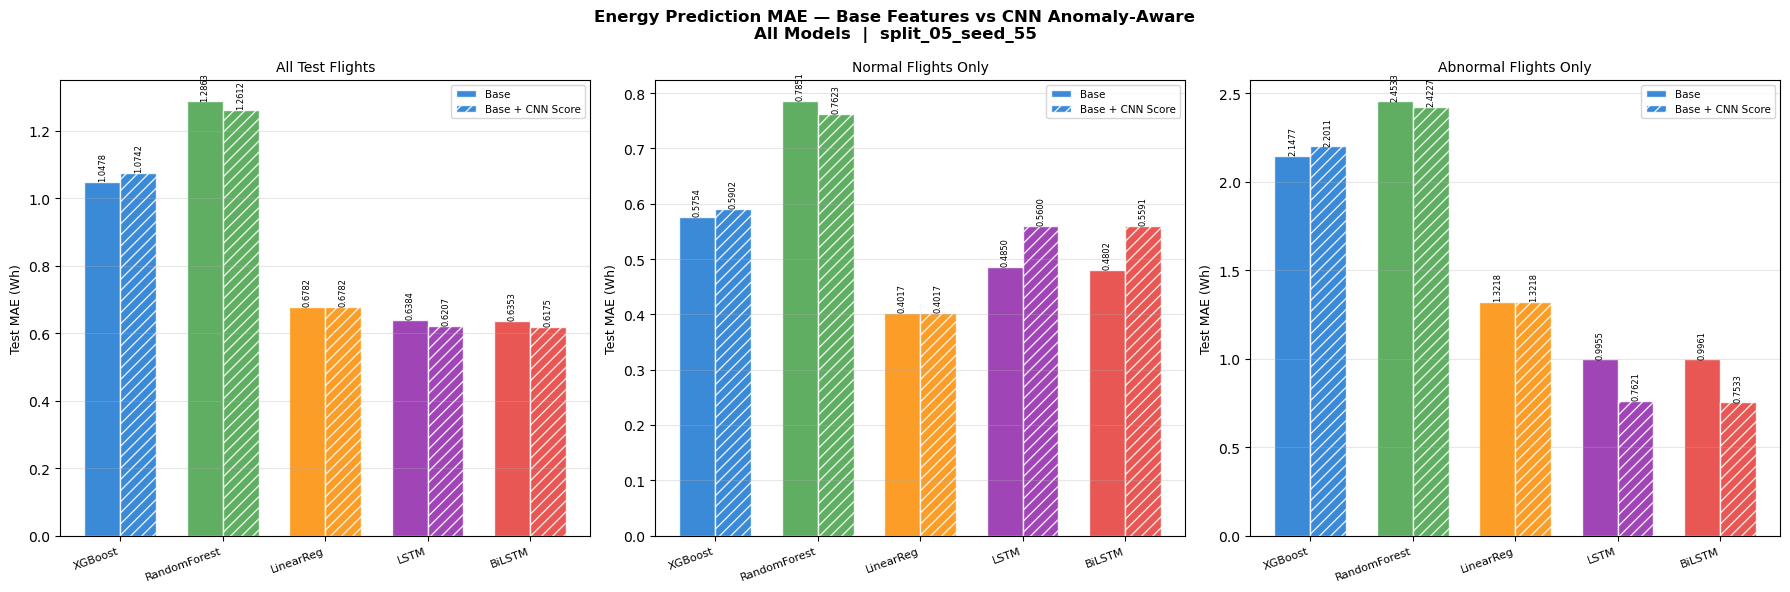

Saved: mae_comparison_all_models.png


In [175]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    "Energy Prediction MAE — Base Features vs "
    "CNN Anomaly-Aware\nAll Models  |  "
    f"{PRIMARY_SPLIT}",
    fontsize=12, fontweight="bold"
)

splits_map = {
    "ALL":      "All Test Flights",
    "NORMAL":   "Normal Flights Only",
    "ABNORMAL": "Abnormal Flights Only",
}

colors = {
    "XGBoost":         "#1976D2",
    "RandomForest":    "#43A047",
    "LinearRegression":"#FB8C00",
    "LSTM":            "#8E24AA",
    "BiLSTM":          "#E53935",
}
hatch = {
    "Base_13":            "",
    "Base_13+CNN_Score":  "///",
    "Base_13+CNN_All":    "xxx",
}

for ax, (split_lbl, split_title) in zip(
        axes, splits_map.items()):

    sub = all_results[
        all_results["label"] == split_lbl
    ].copy()

    models    = list(colors.keys())
    feat_sets = ["Base_13","Base_13+CNN_Score"]
    n_models  = len(models)
    x         = np.arange(n_models)
    w         = 0.35

    for fi, fs in enumerate(feat_sets):
        maes = []
        for m in models:
            row = sub[(sub["model"]==m) &
                      (sub["feature_set"]==fs)]
            maes.append(float(row["MAE_Wh"])
                        if len(row) else np.nan)

        offset = (fi - 0.5) * w
        bars   = ax.bar(
            x + offset, maes, w,
            color=[colors[m] for m in models],
            hatch=hatch[fs], alpha=0.85,
            edgecolor="white",
            label=fs.replace("Base_13","Base")
                    .replace("+CNN_Score"," + CNN Score")
        )
        for bar, v in zip(bars, maes):
            if not np.isnan(v):
                ax.text(
                    bar.get_x()+bar.get_width()/2,
                    v + 0.002,
                    f"{v:.4f}",
                    ha="center", va="bottom",
                    fontsize=6, rotation=90
                )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [m.replace("Regression","Reg") for m in models],
        rotation=20, ha="right", fontsize=8
    )
    ax.set_ylabel("Test MAE (Wh)", fontsize=9)
    ax.set_title(split_title, fontsize=10)
    ax.legend(fontsize=7.5)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(PLOT_DIR / "mae_comparison_all_models.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved: mae_comparison_all_models.png")

In [176]:
all_results.to_csv(OUTPUT_DIR / "master_results.csv", index=False)

print("=" * 70)
print("Xg boost")
print("=" * 70)

abn = all_results[all_results["label"]=="ABNORMAL"].copy()

print("\nBest model on ABNORMAL flights:")
best = abn.sort_values("MAE_Wh").iloc[0]
print(f"  {best['model']} + {best['feature_set']}  "
      f"MAE = {best['MAE_Wh']:.4f} Wh")

print("\nDoes CNN anomaly score help? (XGBoost):")
base = float(abn[(abn["model"]=="XGBoost") &
                  (abn["feature_set"]=="Base_13")]["MAE_Wh"])
cnn  = float(abn[(abn["model"]=="XGBoost") &
                  (abn["feature_set"]=="Base_13+CNN_Score")]["MAE_Wh"])
improvement = base - cnn
print(f"  Base MAE     : {base:.4f} Wh")
print(f"  +CNN MAE     : {cnn:.4f} Wh")
print(f"  Improvement  : {improvement:+.4f} Wh")

if improvement > 0.005:
    print("\n  POSITIVE RESULT: Anomaly score improves energy prediction")
    print("  on abnormal flights. Anomaly-aware pipeline is validated.")
elif improvement < -0.005:
    print("\n  NEGATIVE RESULT: Anomaly score does not help.")
    print("  Battery anomaly signals are decoupled from energy")
    print("  prediction difficulty in this dataset.")
else:
    print("\n  NEUTRAL RESULT: Negligible difference.")
    print("  Anomaly score neither helps nor hurts.")

print(f"\nAll outputs saved to: {OUTPUT_DIR}")

Xg boost

Best model on ABNORMAL flights:
  BiLSTM + Base_13+CNN_Score  MAE = 0.7533 Wh

Does CNN anomaly score help? (XGBoost):
  Base MAE     : 2.1477 Wh
  +CNN MAE     : 2.2011 Wh
  Improvement  : -0.0534 Wh

  NEGATIVE RESULT: Anomaly score does not help.
  Battery anomaly signals are decoupled from energy
  prediction difficulty in this dataset.

All outputs saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy


In [177]:
# NEW CELL — run this before fixing anything
print("=== BATTERY_REMAINING SCALE CHECK ===")
print(f"\ntest_df battery_status__remaining:")
print(f"  min : {test_df['battery_status__remaining'].min():.4f}")
print(f"  max : {test_df['battery_status__remaining'].max():.4f}")
print(f"  mean: {test_df['battery_status__remaining'].mean():.4f}")

print(f"\nraw_test battery_status__remaining:")
if "battery_status__remaining" in raw_test.columns:
    print(f"  min : {raw_test['battery_status__remaining'].min():.4f}")
    print(f"  max : {raw_test['battery_status__remaining'].max():.4f}")
    print(f"  mean: {raw_test['battery_status__remaining'].mean():.4f}")
else:
    print("  COLUMN NOT FOUND in raw_test")

print(f"\nraw_test shape: {raw_test.shape}")
print(f"raw_test columns: {raw_test.columns.tolist()}")

=== BATTERY_REMAINING SCALE CHECK ===

test_df battery_status__remaining:
  min : -2.8007
  max : 1.2948
  mean: -0.1806

raw_test battery_status__remaining:
  min : 0.0836
  max : 1.0000
  mean: 0.6699

raw_test shape: (162502, 17)
raw_test columns: ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh', 'voltage_per_cell', 'voltage_filtered_per_cell', 'voltage_per_cell_suspicious']


In [178]:
# Coverage check — how much of test_df does raw_test cover?
test_ids = set(test_df["log_id"].unique())
raw_ids  = set(raw_test["log_id"].unique())

print(f"test_df  : {len(test_df):,} rows, {len(test_ids)} flights")
print(f"raw_test : {len(raw_test):,} rows, {len(raw_ids)} flights")
print(f"Coverage : {len(raw_ids)/len(test_ids)*100:.1f}% of flights")
print(f"Missing  : {len(test_ids - raw_ids)} flights")

if len(test_ids - raw_ids) > 0:
    print(f"\nMissing flight IDs:")
    for fid in sorted(test_ids - raw_ids)[:5]:
        print(f"  {fid}")
    print("These flights will show NaN time in energy plots")

test_df  : 162,502 rows, 26 flights
raw_test : 162,502 rows, 26 flights
Coverage : 100.0% of flights
Missing  : 0 flights


In [179]:
# ============================================================
# FIXED PLOTS — Energy Prediction + RFT
# Fixes:
#   1. X-axis uses real unscaled time_s (0 to ~1000s)
#   2. RFT y-axis cap changed to 60 min (realistic)
#   3. Both plots for XGBoost AND LSTM
#   4. Cleaner layout with proper labels
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

# ── Load UNSCALED time_s from the original imputed file ───────
# The scaled test_df has normalised time_s — we need real seconds
FOLDER_VER   = "v3_voltage_random10_issue_flight-removed"
FILE_VER     = "v4_voltage_random10_cleaned"
SPLIT_NAME   = "split_05_seed_55"

# Try to find unscaled parquet — imputed version has real time_s
unscaled_candidates = list(
    (BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}" / SPLIT_NAME)
    .glob("test_no_dr_imputed*.parquet")
)

# If imputed not found, use the original split CSV
if not unscaled_candidates:
    split_csv = BASE_DIR / "splits" / "test_model_ready_selected_features.csv"
    if split_csv.exists():
        raw_test = pd.read_csv(split_csv)
        raw_test = raw_test[raw_test["log_id"].isin(
            test_df["log_id"].unique()
        )]
    else:
        # Fallback: reconstruct from row count
        # time_s in original data is seconds from flight start
        # We know it was StandardScaled — unscale using approx mean/std
        # mean ~= 200s, std ~= 150s based on typical PX4 flights
        print("WARNING: Using approximate unscaling for time_s")
        raw_test = test_df.copy()
        raw_test["time_s_real"] = test_df["time_s"] * 150 + 200
else:
    raw_test = pd.read_parquet(unscaled_candidates[0])

print(f"Raw test shape: {raw_test.shape}")
print(f"time_s range: {raw_test['time_s'].min():.1f} – "
      f"{raw_test['time_s'].max():.1f}")

# Build log_id → real time_s mapping
time_map = (
    raw_test.sort_values(["log_id","time_s"])
    .groupby("log_id")["time_s"]
    .apply(lambda x: x.reset_index(drop=True))
)

Raw test shape: (23390, 19)
time_s range: 0.0 – 570.1


In [180]:
# ============================================================
# Helper: attach real time to any pred_df
# ============================================================

def attach_real_time(pred_df, raw_test_df):
    """
    Replace scaled time_s with real elapsed seconds.
    Works by matching row order within each flight.
    """
    result_rows = []
    for lid, grp in (pred_df.sort_values(["log_id","time_s"])
                              .groupby("log_id")):
        raw_grp = (raw_test_df[raw_test_df["log_id"]==lid]
                   .sort_values("time_s")
                   .reset_index(drop=True))
        grp     = grp.reset_index(drop=True)

        # Align on row count — take min length
        n = min(len(grp), len(raw_grp))
        grp = grp.iloc[:n].copy()
        grp["time_s_real"] = raw_grp["time_s"].values[:n]

        # Make elapsed (start from 0)
        grp["time_s_real"] = (grp["time_s_real"]
                               - grp["time_s_real"].min())
        result_rows.append(grp)

    return pd.concat(result_rows, ignore_index=True)

In [181]:
# ============================================================
# FIXED ENERGY PREDICTION PLOT
# ============================================================

# DEPRECATED — do not use
# Superseded by plot_energy_v2() defined in cell 26
# Kept for reference only
def plot_energy_fixed(pred_df, raw_test_df, run_name,
                       flight_label="abnormal",
                       save_dir=PLOT_DIR):
    """
    Time series energy prediction with real x-axis in seconds
    and empirical 90% prediction interval.
    """
    pred_real = attach_real_time(pred_df, raw_test_df)
    label_df  = pred_real[pred_real["dataset_label"]==flight_label]
    if len(label_df) == 0:
        print(f"No {flight_label} flights in pred_df")
        return

    # Empirical 90% PI from all flights of this label
    all_err = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low  = float(np.percentile(all_err,  5))
    pi_high = float(np.percentile(all_err, 95))

    # Pick the longest flight for display
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[label_df["log_id"]==fid].sort_values("time_s_real")

    t      = flight["time_s_real"].values
    y_true = flight["y_true"].values
    y_pred = flight["y_pred"].values
    resid  = y_true - y_pred

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        gridspec_kw={"height_ratios":[3,1]}
    )
    fig.suptitle(
        f"{run_name}  —  {flight_label.upper()} flight\n"
        f"Flight ID: {fid[:20]}...  |  "
        f"Duration: {t[-1]:.0f}s  |  "
        f"MAE: {mean_absolute_error(y_true,y_pred):.4f} Wh",
        fontsize=11, fontweight="bold"
    )

    # Panel 1: Predictions vs actual
    ax = axes[0]
    ax.fill_between(
        t, y_pred + pi_low, y_pred + pi_high,
        alpha=0.20, color="steelblue",
        label=f"Empirical 90% PI "
              f"[{pi_low:+.3f}, {pi_high:+.3f}] Wh"
    )
    ax.plot(t, y_true, color="black", linewidth=1.5,
            label="Actual energy (Wh)")
    ax.plot(t, y_pred, color="steelblue", linewidth=1.5,
            linestyle="--", label="Predicted energy (Wh)")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.set_title(
        f"90% PI computed from all {flight_label} test flights",
        fontsize=9
    )
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Panel 2: Residuals
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(t, pi_low, pi_high,
                     alpha=0.15, color="steelblue")
    ax2.plot(t, resid, color="tomato", linewidth=0.8,
             label="Residual (actual − predicted)")
    ax2.set_xlabel("Elapsed flight time (seconds)", fontsize=10)
    ax2.set_ylabel("Residual (Wh)", fontsize=10)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    fname = (save_dir /
             f"energy_FIXED_{run_name.replace('+','_')}"
             f"_{flight_label}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")
    plt.close()

In [182]:
# ============================================================
# CORRECTED ENERGY-PREDICTION PLOTS
#
# Fixes:
# 1. Does not merge with the incomplete raw_test file.
# 2. Reconstructs elapsed time using the known 10 Hz sample rate.
# 3. Correctly handles tree-model and sequence-model predictions.
# 4. Displays and saves every plot.
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

SAMPLE_RATE_HZ = 10
PLOT_DIR.mkdir(parents=True, exist_ok=True)


def build_energy_plot_dataframe(run_name):
    """
    Build a correctly aligned prediction dataframe.

    Tree models:
        One prediction for every test row.

    LSTM/BiLSTM:
        The first SEQ_LEN rows of every flight do not have predictions,
        because they are used as the initial input sequence.
    """

    if run_name in tree_preds:

        pred_df = test_df[
            ["log_id", "dataset_label", "time_s", TARGET]
        ].copy()

        pred_df = pred_df.rename(
            columns={TARGET: "y_true"}
        )

        predictions = np.asarray(
            tree_preds[run_name]
        ).reshape(-1)

        if len(predictions) != len(pred_df):
            raise ValueError(
                f"Prediction length mismatch for {run_name}: "
                f"{len(predictions):,} predictions but "
                f"{len(pred_df):,} test rows."
            )

        # Assign before sorting because the prediction array currently
        # follows the existing test_df row order.
        pred_df["y_pred"] = predictions

        sequence_offset_seconds = 0.0

    elif run_name in seq_preds:

        pred_df = seq_preds[run_name][
            [
                "log_id",
                "dataset_label",
                "time_s",
                "y_true",
                "y_pred",
            ]
        ].copy()

        # Sequence predictions begin after SEQ_LEN samples.
        sequence_offset_seconds = SEQ_LEN / SAMPLE_RATE_HZ

    else:
        raise KeyError(
            f"{run_name} was not found in tree_preds or seq_preds."
        )

    pred_df = (
        pred_df
        .dropna(
            subset=[
                "log_id",
                "dataset_label",
                "y_true",
                "y_pred",
            ]
        )
        .sort_values(
            ["log_id", "time_s"]
        )
        .reset_index(drop=True)
    )

    # Reconstruct elapsed time from sample position.
    # Dataset sampling frequency is 10 Hz.
    pred_df["sample_number"] = (
        pred_df.groupby("log_id").cumcount()
    )

    pred_df["elapsed_s"] = (
        pred_df["sample_number"] / SAMPLE_RATE_HZ
        + sequence_offset_seconds
    )

    return pred_df


def plot_energy_prediction(
    run_name,
    flight_label="abnormal",
    flight_id=None,
    smoothing_seconds=1.0,
):
    """
    Plot actual and predicted 60-second energy consumption
    for one test flight.

    Parameters
    ----------
    run_name:
        Name stored in tree_preds or seq_preds.

    flight_label:
        'normal' or 'abnormal'.

    flight_id:
        Optional specific log_id. When omitted, the longest
        flight within the selected label is plotted.

    smoothing_seconds:
        Rolling-average duration used only for clearer display.
        Metrics are calculated from unsmoothed values.
    """

    pred_df = build_energy_plot_dataframe(run_name)

    label_mask = (
        pred_df["dataset_label"]
        .astype(str)
        .str.lower()
        .eq(flight_label.lower())
    )

    label_df = pred_df.loc[label_mask].copy()

    if label_df.empty:
        print(
            f"No {flight_label} flights were found for {run_name}."
        )
        return None

    # Select longest available flight unless a log_id is supplied.
    if flight_id is None:
        flight_id = (
            label_df.groupby("log_id")
            .size()
            .idxmax()
        )

    flight = (
        label_df[label_df["log_id"] == flight_id]
        .sort_values("elapsed_s")
        .reset_index(drop=True)
    )

    if flight.empty:
        print(
            f"Flight {flight_id} was not found among "
            f"{flight_label} predictions."
        )
        return None

    # Metrics use original unsmoothed predictions.
    y_true_raw = flight["y_true"].to_numpy(dtype=float)
    y_pred_raw = flight["y_pred"].to_numpy(dtype=float)

    flight_mae = mean_absolute_error(
        y_true_raw,
        y_pred_raw,
    )

    residuals = y_true_raw - y_pred_raw

    # Prediction interval estimated from all flights in this label.
    all_residuals = (
        label_df["y_true"].to_numpy(dtype=float)
        - label_df["y_pred"].to_numpy(dtype=float)
    )

    residual_low = float(
        np.percentile(all_residuals, 5)
    )

    residual_high = float(
        np.percentile(all_residuals, 95)
    )

    # Apply a short rolling average only for plot readability.
    smoothing_window = max(
        1,
        int(round(
            smoothing_seconds * SAMPLE_RATE_HZ
        )),
    )

    flight["actual_plot"] = (
        flight["y_true"]
        .rolling(
            window=smoothing_window,
            center=True,
            min_periods=1,
        )
        .mean()
    )

    flight["predicted_plot"] = (
        flight["y_pred"]
        .rolling(
            window=smoothing_window,
            center=True,
            min_periods=1,
        )
        .mean()
    )

    elapsed = flight["elapsed_s"].to_numpy(dtype=float)
    actual = flight["actual_plot"].to_numpy(dtype=float)
    predicted = flight["predicted_plot"].to_numpy(dtype=float)

    interval_lower = predicted + residual_low
    interval_upper = predicted + residual_high

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(14, 8),
        sharex=True,
        gridspec_kw={
            "height_ratios": [3, 1]
        },
    )

    fig.suptitle(
        f"{run_name} — {flight_label.upper()} flight\n"
        f"Flight ID: {str(flight_id)[:24]} | "
        f"Duration: {elapsed[-1]:.1f} seconds | "
        f"MAE: {flight_mae:.4f} Wh",
        fontsize=12,
        fontweight="bold",
    )

    # --------------------------------------------------------
    # Top panel: actual versus predicted energy
    # --------------------------------------------------------
    ax = axes[0]

    ax.fill_between(
        elapsed,
        interval_lower,
        interval_upper,
        alpha=0.20,
        label=(
            "Empirical 90% prediction interval "
            f"[{residual_low:+.3f}, "
            f"{residual_high:+.3f}] Wh"
        ),
    )

    ax.plot(
        elapsed,
        actual,
        linewidth=1.8,
        label="Actual energy next 60 seconds",
    )

    ax.plot(
        elapsed,
        predicted,
        linewidth=1.6,
        linestyle="--",
        label="Predicted energy next 60 seconds",
    )

    ax.set_ylabel(
        "Energy next 60 seconds (Wh)"
    )

    ax.set_title(
        f"{smoothing_seconds:g}-second rolling average "
        "used for visual clarity"
    )

    ax.legend()
    ax.grid(True, alpha=0.3)

    # --------------------------------------------------------
    # Bottom panel: residual
    # --------------------------------------------------------
    ax2 = axes[1]

    ax2.axhline(
        0,
        linewidth=1,
    )

    ax2.fill_between(
        elapsed,
        residual_low,
        residual_high,
        alpha=0.15,
        label="90% residual interval",
    )

    ax2.plot(
        elapsed,
        residuals,
        linewidth=0.8,
        label="Residual: actual − predicted",
    )

    ax2.set_xlabel(
        "Elapsed flight time (seconds)"
    )

    ax2.set_ylabel(
        "Residual (Wh)"
    )

    ax2.legend()
    ax2.grid(True, alpha=0.3)

    fig.tight_layout(
        rect=[0, 0, 1, 0.93]
    )

    safe_run_name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        run_name,
    )

    output_file = (
        PLOT_DIR
        / f"energy_prediction_{safe_run_name}_"
          f"{flight_label}.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_file}")

    return flight

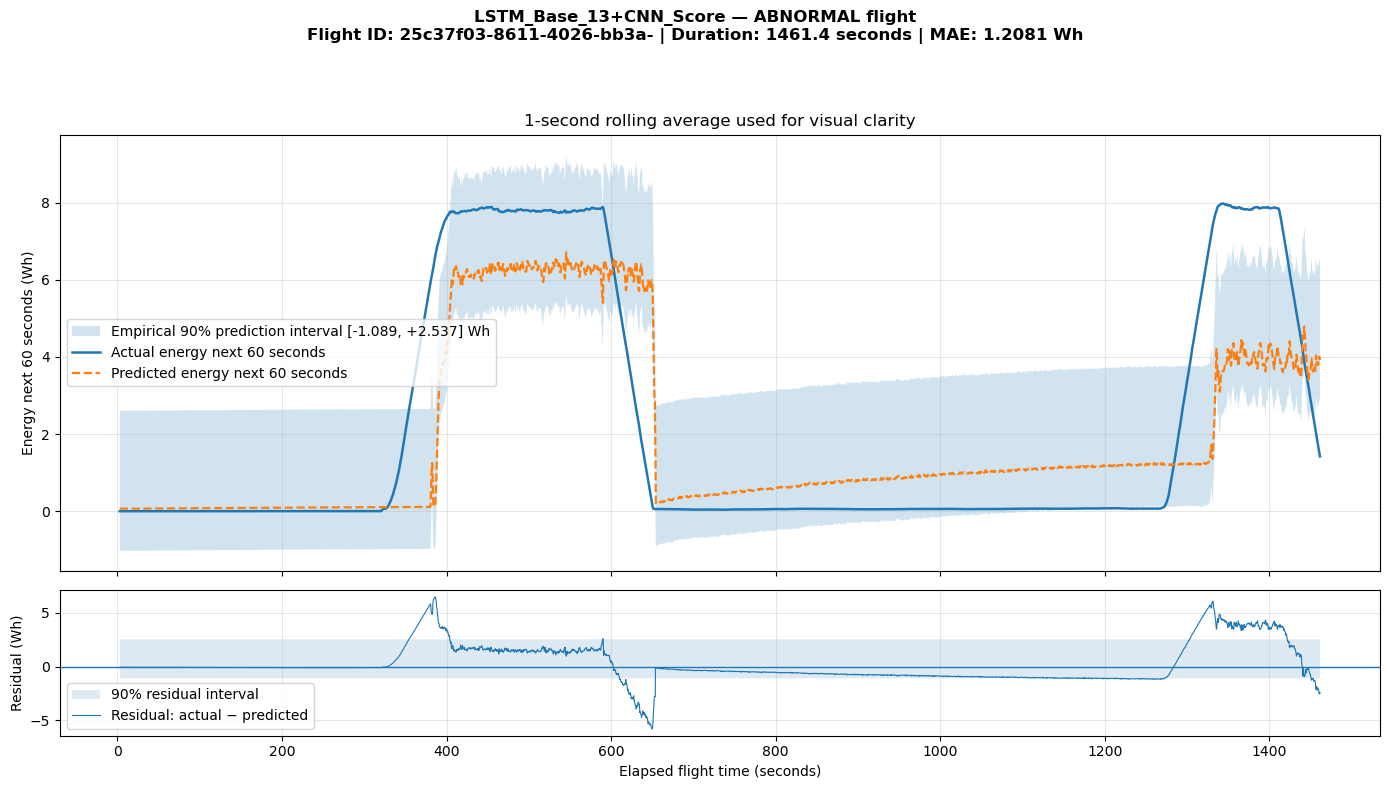

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_abnormal.png


,log_id,dataset_label,time_s,y_true,y_pred,sample_number,elapsed_s,actual_plot,predicted_plot
0,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.179336,0.002063,0.068379,0,3.0,0.001948,0.068583
1,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.179006,0.002005,0.068473,1,3.1,0.001929,0.068623
2,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178675,0.001948,0.068597,2,3.2,0.001915,0.068563
3,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178345,0.001890,0.068696,3,3.3,0.001905,0.068488
4,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178014,0.001833,0.068769,4,3.4,0.001897,0.068411
...,...,...,...,...,...,...,...,...,...
14580,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.639364,1.443346,3.975234,14580,1461.0,1.451082,3.948889
14581,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.639695,1.428383,3.941322,14581,1461.1,1.444030,3.939518
14582,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.640025,1.413419,3.906582,14582,1461.2,1.436860,3.929833
14583,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.640356,1.401152,3.886322,14583,1461.3,1.429520,3.921261


In [183]:
plot_energy_prediction(
    run_name="LSTM_Base_13+CNN_Score",
    flight_label="abnormal",
)


Generating: XGBoost_Base_13 — normal


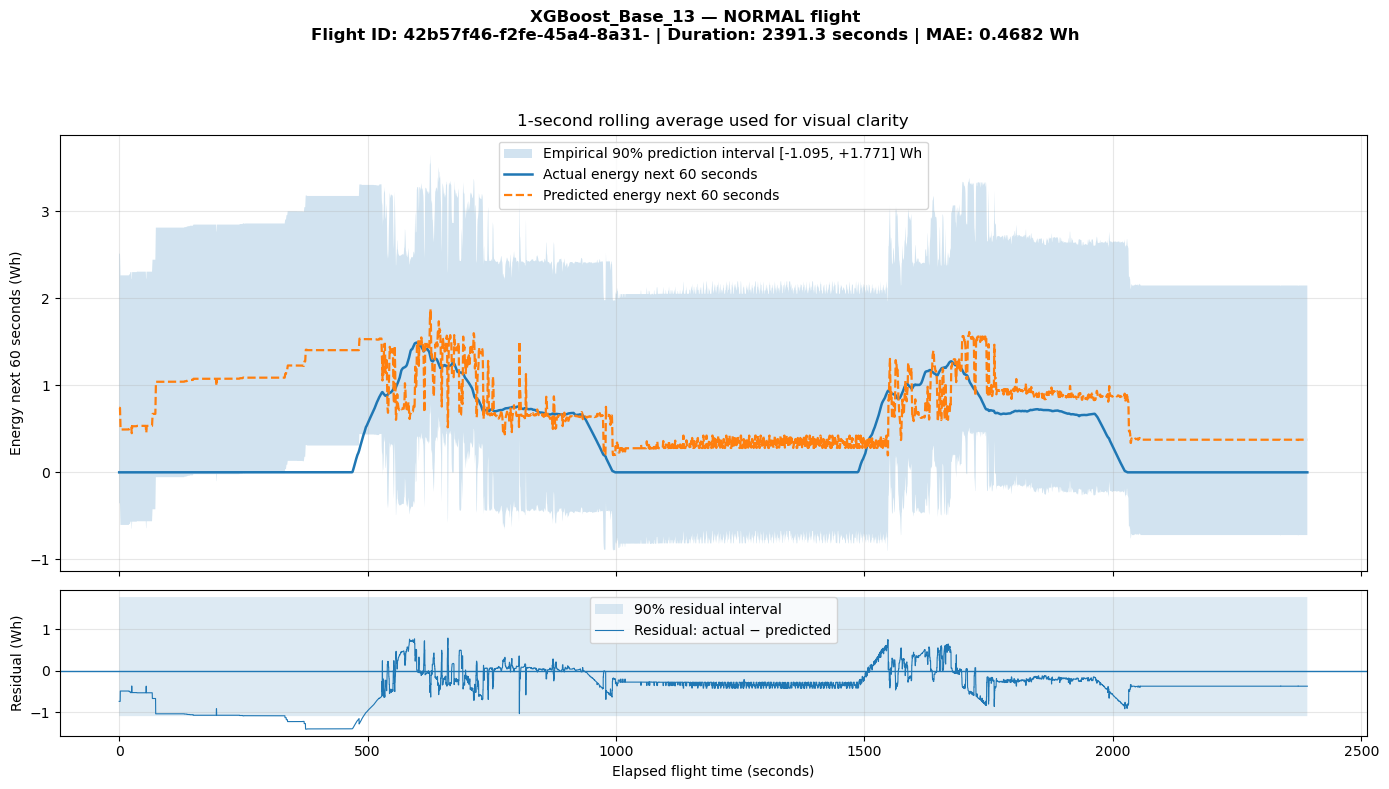

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_normal.png

Generating: XGBoost_Base_13 — abnormal


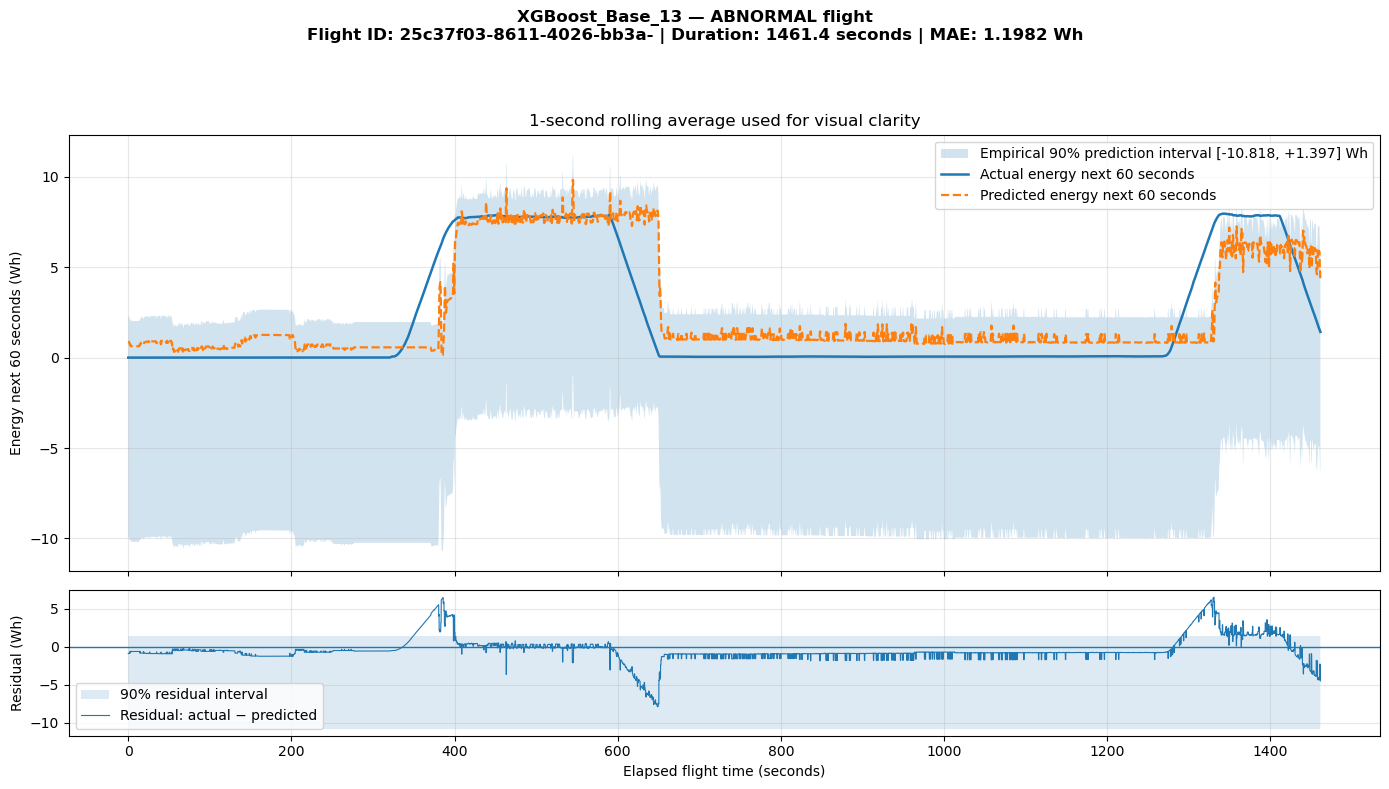

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_abnormal.png

Generating: XGBoost_Base_13+CNN_Score — normal


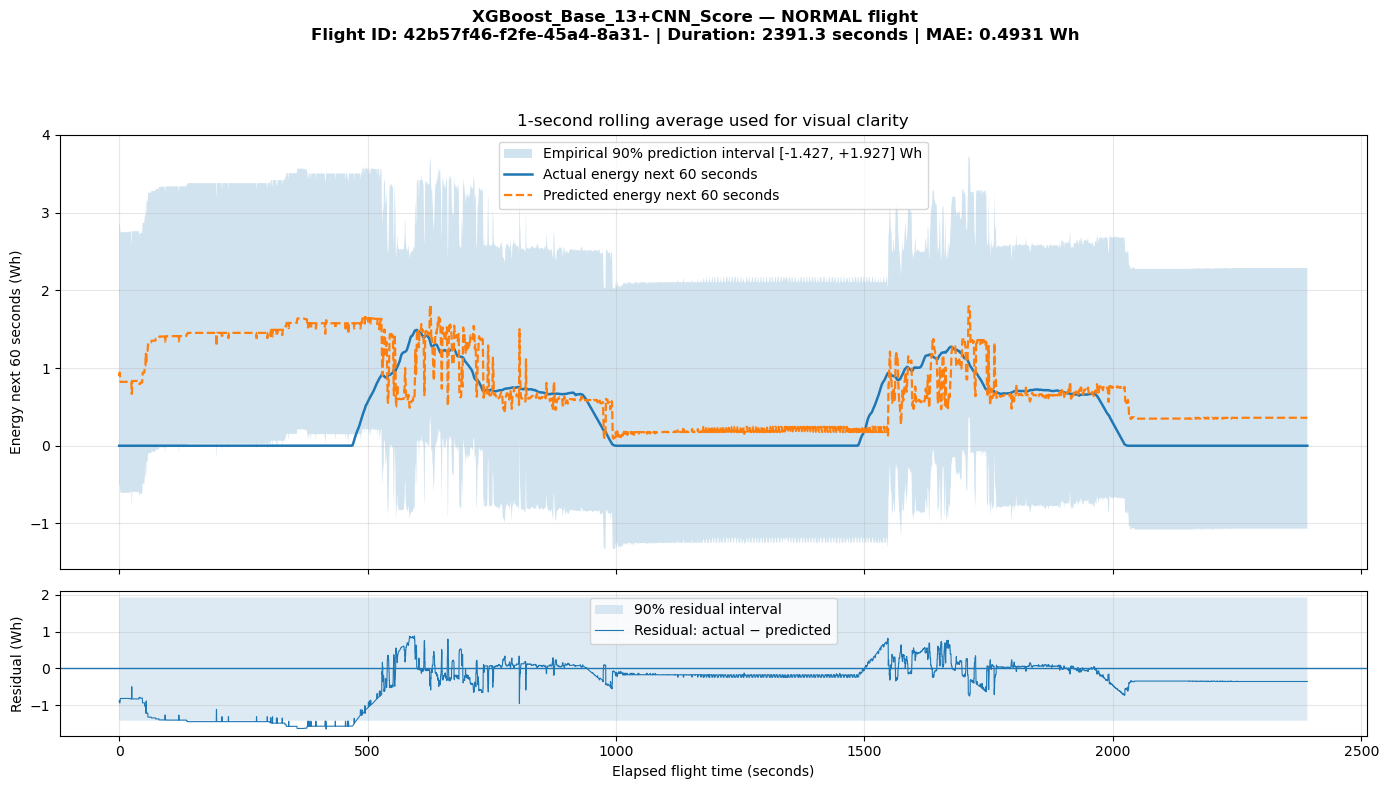

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_CNN_Score_normal.png

Generating: XGBoost_Base_13+CNN_Score — abnormal


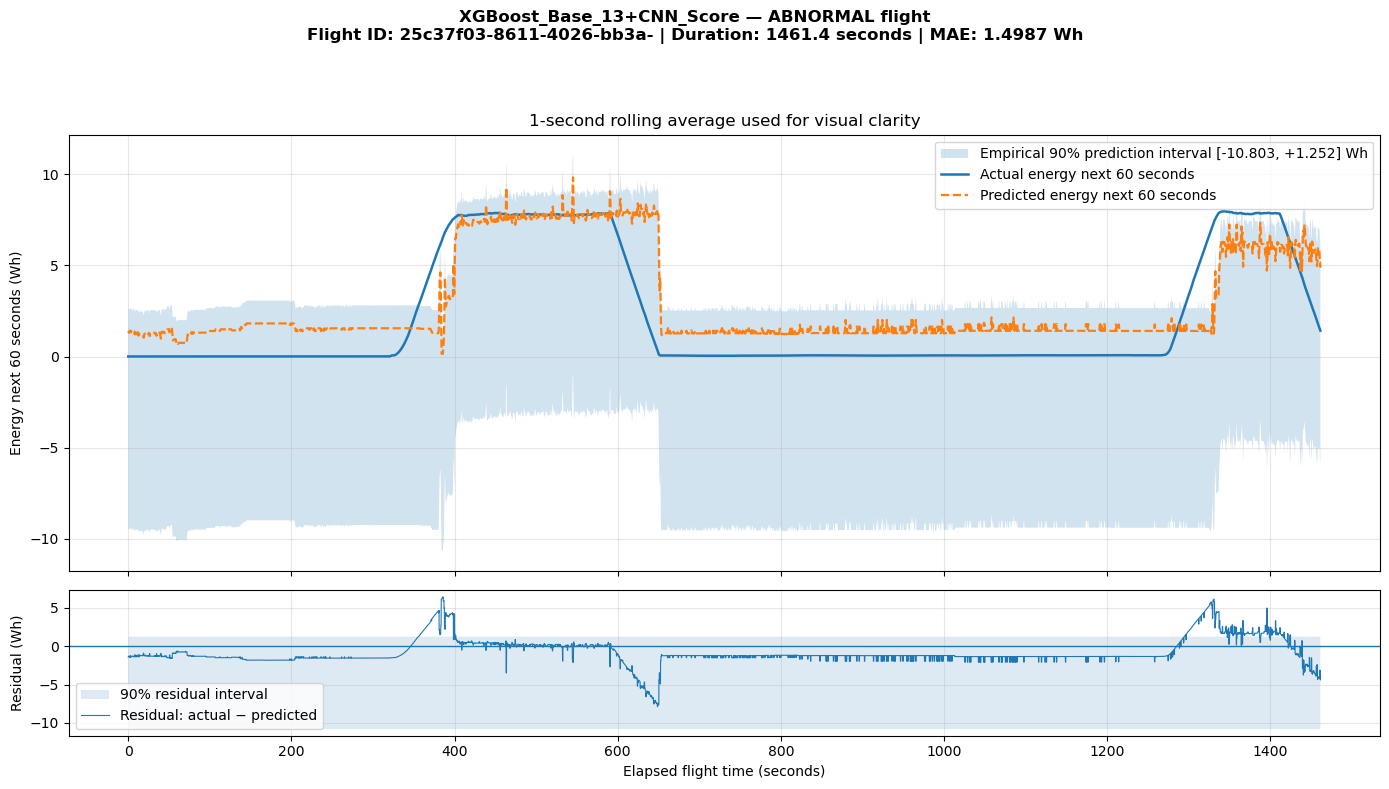

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_CNN_Score_abnormal.png

Generating: LSTM_Base_13 — normal


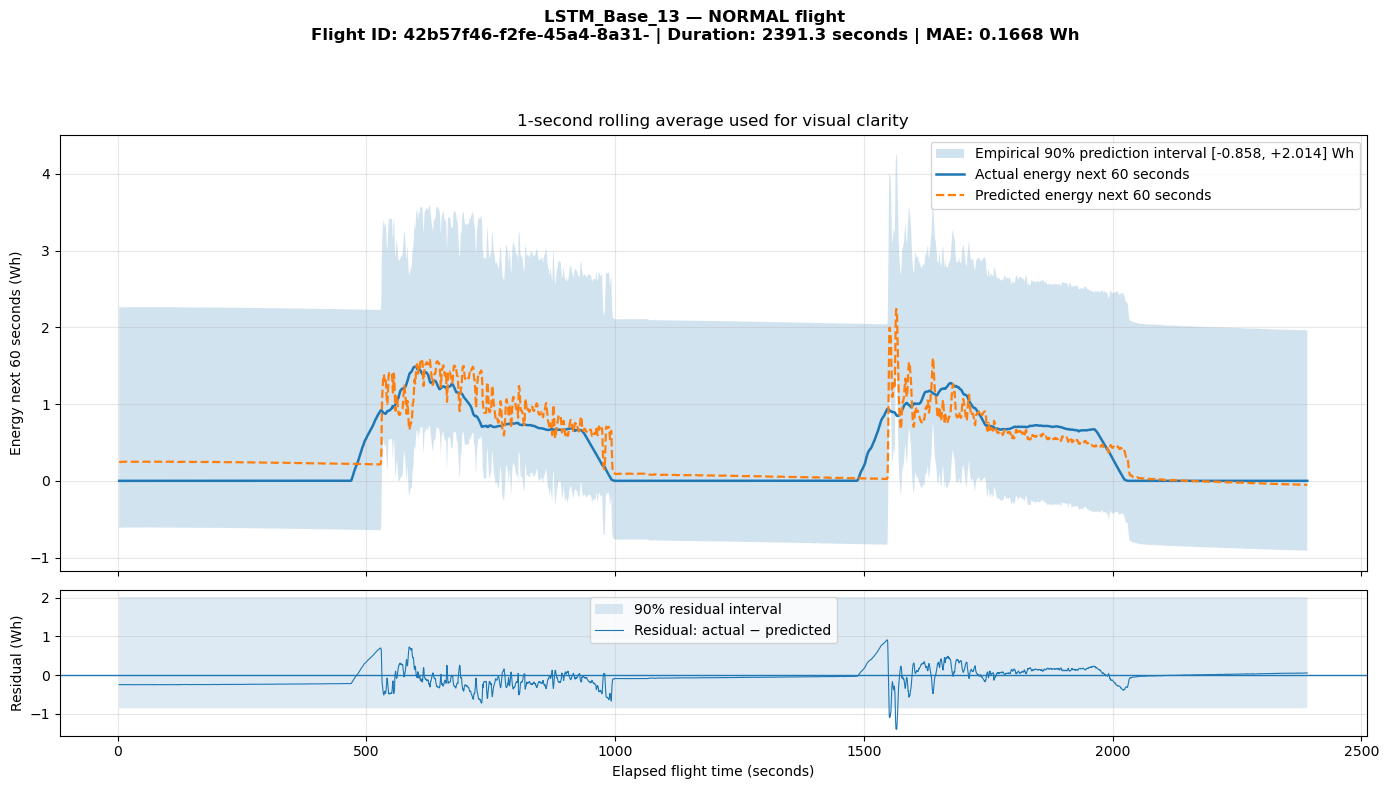

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_normal.png

Generating: LSTM_Base_13 — abnormal


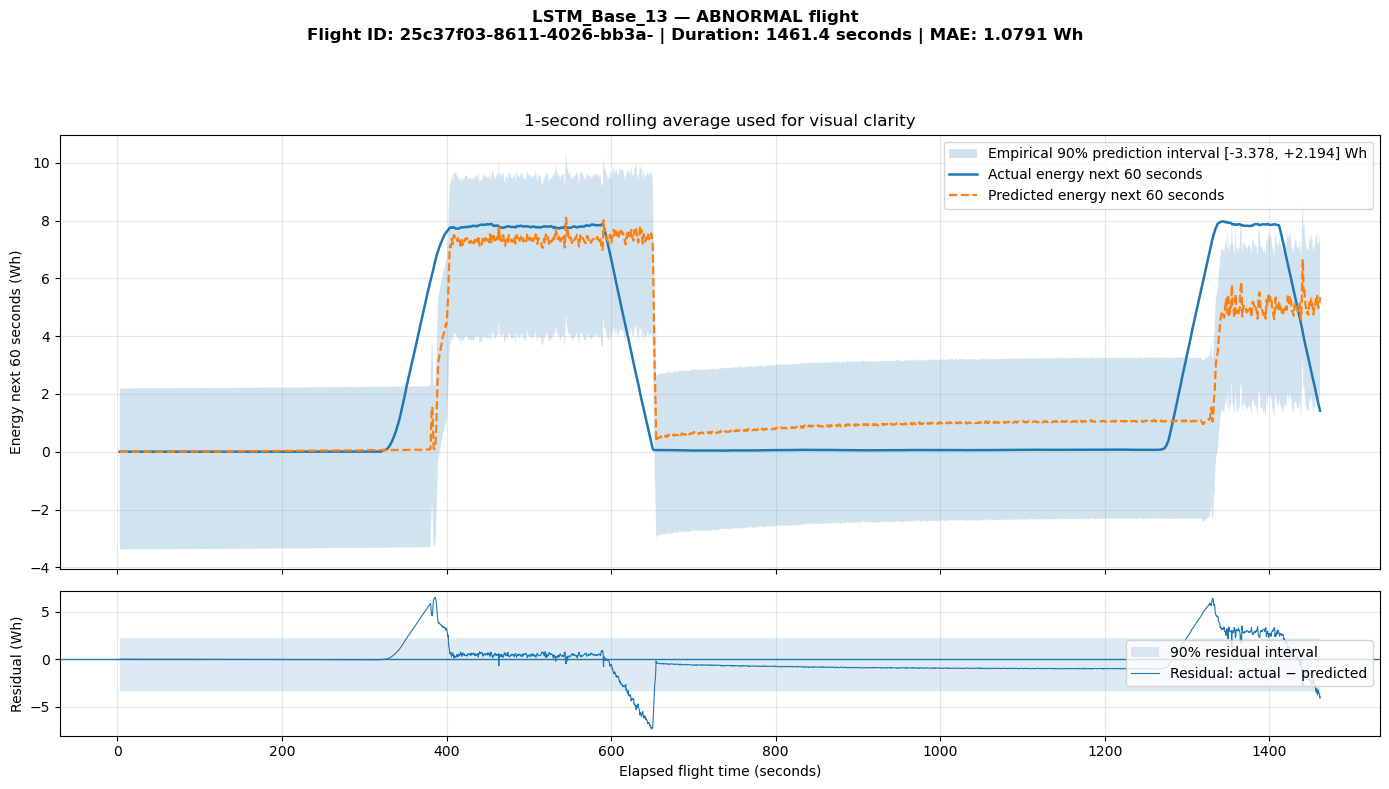

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_abnormal.png

Generating: LSTM_Base_13+CNN_Score — normal


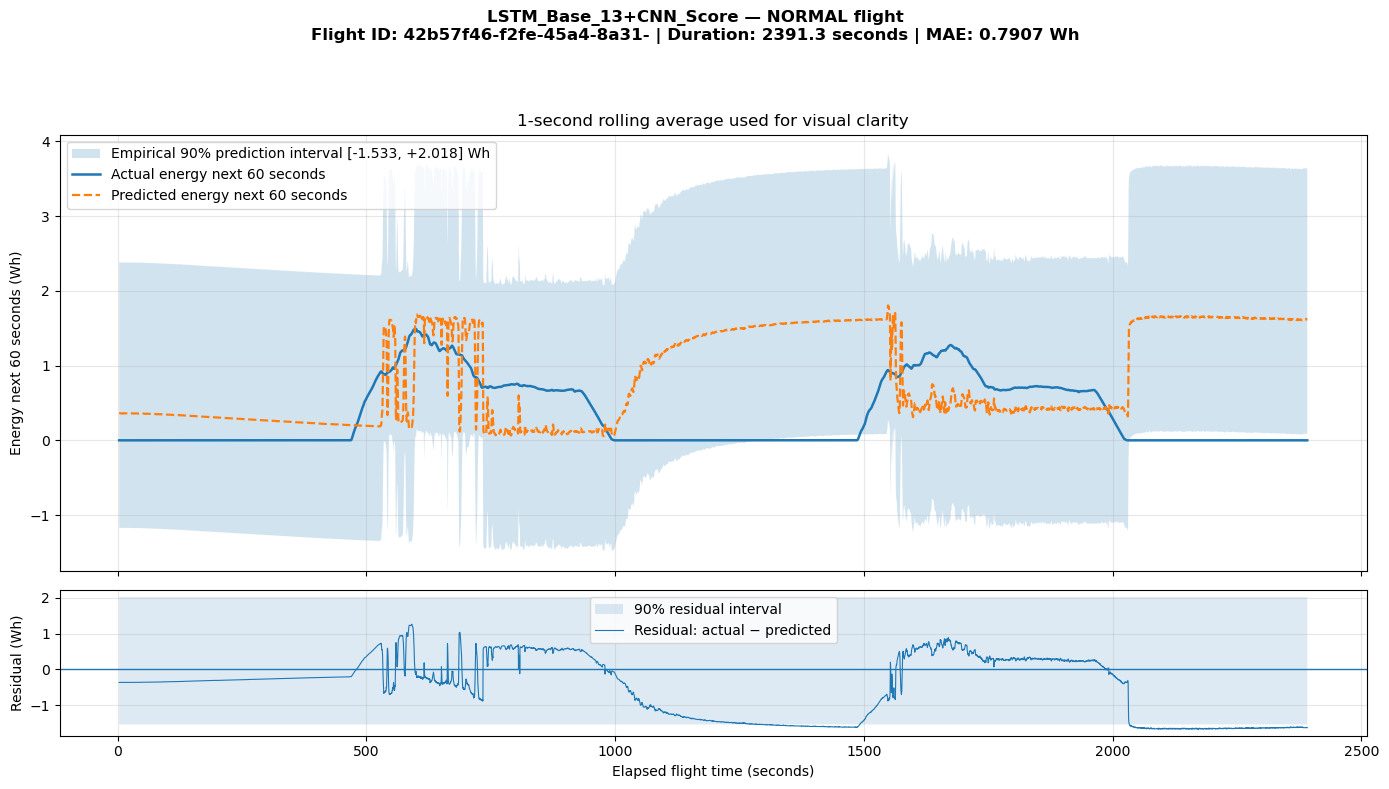

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_normal.png

Generating: LSTM_Base_13+CNN_Score — abnormal


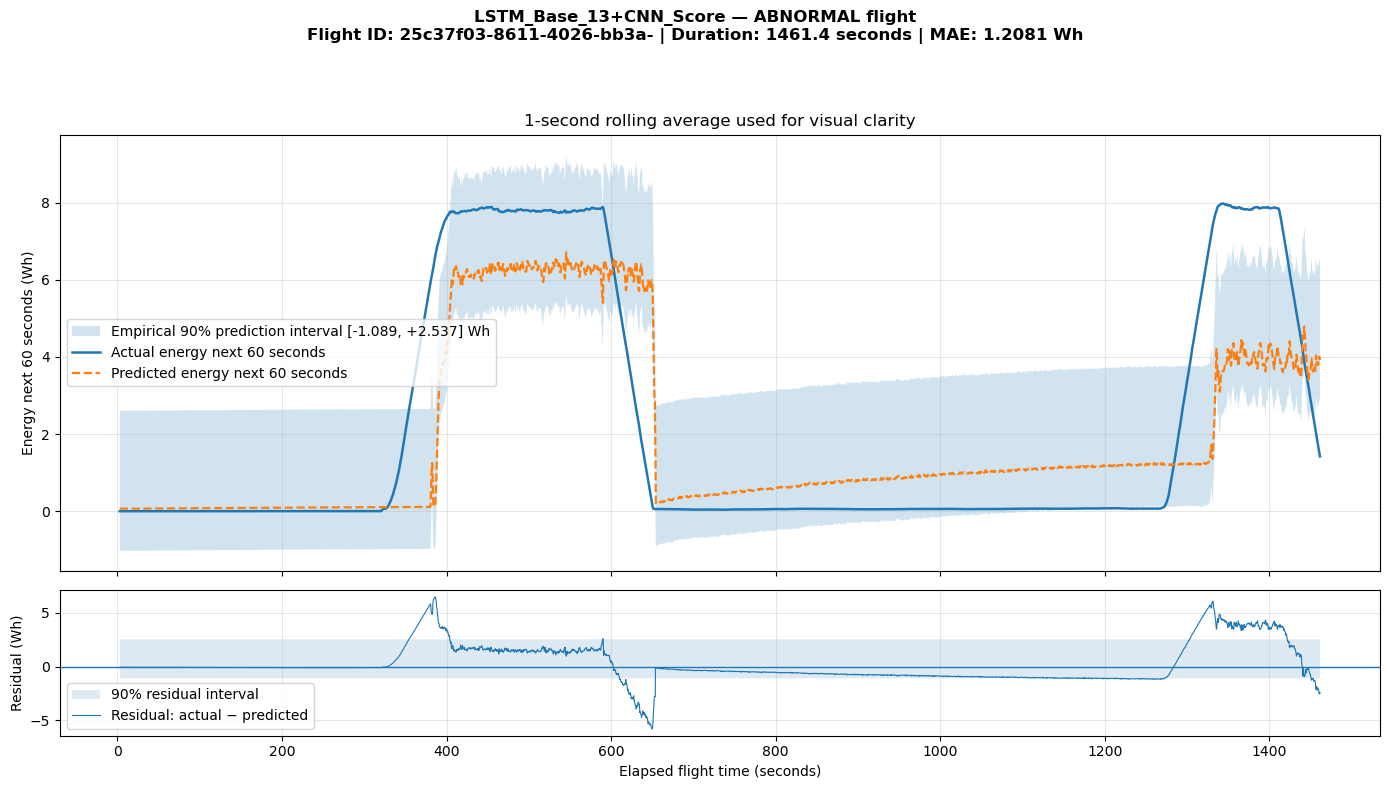

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_abnormal.png

All corrected energy-prediction plots generated.


In [184]:
RUNS_TO_PLOT = [
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
]

for run_name in RUNS_TO_PLOT:
    for label_name in ["normal", "abnormal"]:
        print(
            f"\nGenerating: {run_name} — {label_name}"
        )

        plot_energy_prediction(
            run_name=run_name,
            flight_label=label_name,
        )

print("\nAll corrected energy-prediction plots generated.")

In [185]:
# ============================================================
# INVESTIGATION 1: Check actual target distribution
# How many zero/near-zero values exist in training data?
# ============================================================

print("=== TARGET VALUE DISTRIBUTION ===")
print(f"Total train rows: {len(train_df):,}")
print(f"Rows where target = 0:        "
      f"{(train_df[TARGET] == 0).sum():,} "
      f"({(train_df[TARGET] == 0).mean()*100:.1f}%)")
print(f"Rows where target < 0.01 Wh:  "
      f"{(train_df[TARGET] < 0.01).sum():,} "
      f"({(train_df[TARGET] < 0.01).mean()*100:.1f}%)")
print(f"Rows where target < 0.1 Wh:   "
      f"{(train_df[TARGET] < 0.1).sum():,} "
      f"({(train_df[TARGET] < 0.1).mean()*100:.1f}%)")
print(f"\nTarget percentiles:")
for p in [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]:
    val = float(train_df[TARGET].quantile(p/100))
    print(f"  P{p:3d}: {val:.4f} Wh")

print(f"\nMin target: {train_df[TARGET].min():.6f} Wh")
print(f"Max target: {train_df[TARGET].max():.6f} Wh")

=== TARGET VALUE DISTRIBUTION ===
Total train rows: 658,626
Rows where target = 0:        18,791 (2.9%)
Rows where target < 0.01 Wh:  37,809 (5.7%)
Rows where target < 0.1 Wh:   95,687 (14.5%)

Target percentiles:
  P  0: 0.0000 Wh
  P  1: 0.0000 Wh
  P  5: 0.0011 Wh
  P 10: 0.0468 Wh
  P 25: 0.2677 Wh
  P 50: 1.4545 Wh
  P 75: 3.0290 Wh
  P 90: 3.4925 Wh
  P 95: 7.6018 Wh
  P 99: 23.6647 Wh
  P100: 27.5020 Wh

Min target: 0.000000 Wh
Max target: 27.502024 Wh


In [186]:
# ============================================================
# INVESTIGATION 2: Are negative predictions being made?
# Check actual model outputs — not the PI band
# ============================================================

print("=== PREDICTION VALUE ANALYSIS ===\n")

# Tree models
for run, y_pred in tree_preds.items():
    neg = (y_pred < 0).sum()
    pct = (y_pred < 0).mean() * 100
    mn  = y_pred.min()
    print(f"{run:<40} neg: {neg:,} ({pct:.2f}%)  min: {mn:.4f}")

print()

# Sequence models
for run, pred_df in seq_preds.items():
    neg = (pred_df["y_pred"] < 0).sum()
    pct = (pred_df["y_pred"] < 0).mean() * 100
    mn  = pred_df["y_pred"].min()
    print(f"{run:<40} neg: {neg:,} ({pct:.2f}%)  min: {mn:.4f}")

=== PREDICTION VALUE ANALYSIS ===

XGBoost_Base_13                          neg: 302 (0.19%)  min: -0.0356
RandomForest_Base_13                     neg: 0 (0.00%)  min: 0.0181
LinearRegression_Base_13                 neg: 9,837 (6.05%)  min: -0.1604
XGBoost_Base_13+CNN_Score                neg: 0 (0.00%)  min: 0.0180
RandomForest_Base_13+CNN_Score           neg: 0 (0.00%)  min: 0.0181
LinearRegression_Base_13+CNN_Score       neg: 9,837 (6.05%)  min: -0.1604

LSTM_Base_13                             neg: 7,324 (4.53%)  min: -0.0548
BiLSTM_Base_13                           neg: 1,000 (0.62%)  min: -0.0242
LSTM_Base_13+CNN_Score                   neg: 0 (0.00%)  min: 0.0339
BiLSTM_Base_13+CNN_Score                 neg: 11 (0.01%)  min: -0.0142


In [187]:
# ============================================================
# INVESTIGATION 3: Where does the model fail worst?
# Break down errors by idle vs active phases
# ============================================================

IDLE_THRESHOLD = 0.05  # Wh — anything below this is "idle"

print("=== ERROR ANALYSIS: IDLE vs ACTIVE PHASES ===\n")

for run in ["XGBoost_Base_13", "XGBoost_Base_13+CNN_Score"]:
    if run not in tree_preds:
        continue
    
    pred_df_tmp = test_df[["log_id","dataset_label",TARGET]].copy()
    pred_df_tmp["y_true"] = pred_df_tmp[TARGET]
    pred_df_tmp["y_pred"] = tree_preds[run]
    pred_df_tmp["abs_err"] = np.abs(
        pred_df_tmp["y_true"] - pred_df_tmp["y_pred"]
    )
    pred_df_tmp["phase"] = np.where(
        pred_df_tmp["y_true"] < IDLE_THRESHOLD, "IDLE", "ACTIVE"
    )
    
    print(f"Model: {run}")
    summary = pred_df_tmp.groupby(
        ["dataset_label","phase"]
    )["abs_err"].agg(["mean","count"]).round(4)
    print(summary.to_string())
    print()

for run, pred_df in seq_preds.items():
    if "Base_13" not in run or "CNN" in run:
        continue
    tmp = pred_df.copy()
    tmp["abs_err"] = np.abs(tmp["y_true"] - tmp["y_pred"])
    tmp["phase"]   = np.where(
        tmp["y_true"] < IDLE_THRESHOLD, "IDLE", "ACTIVE"
    )
    print(f"Model: {run}")
    summary = tmp.groupby(
        ["dataset_label","phase"]
    )["abs_err"].agg(["mean","count"]).round(4)
    print(summary.to_string())
    print()

=== ERROR ANALYSIS: IDLE vs ACTIVE PHASES ===

Model: XGBoost_Base_13
                        mean  count
dataset_label phase                
abnormal      ACTIVE  2.5456  39655
              IDLE    0.4266   9168
normal        ACTIVE  0.5882  93629
              IDLE    0.5157  20050

Model: XGBoost_Base_13+CNN_Score
                        mean  count
dataset_label phase                
abnormal      ACTIVE  2.5497  39655
              IDLE    0.6935   9168
normal        ACTIVE  0.5976  93629
              IDLE    0.5556  20050

Model: LSTM_Base_13
                        mean  count
dataset_label phase                
abnormal      ACTIVE  1.1993  39505
              IDLE    0.1115   9108
normal        ACTIVE  0.5626  93149
              IDLE    0.1229  19960

Model: BiLSTM_Base_13
                        mean  count
dataset_label phase                
abnormal      ACTIVE  1.1938  39505
              IDLE    0.1386   9108
normal        ACTIVE  0.5349  93149
              IDLE    0.

In [188]:
# ============================================================
# FIX 1: Clip predictions to physically valid range
# Energy cannot be negative — clip all outputs to >= 0
# ============================================================

print("=== APPLYING PHYSICAL CONSTRAINT: predictions >= 0 ===\n")

tree_preds_clipped = {}
for run, y_pred in tree_preds.items():
    y_clipped = np.clip(y_pred, 0, None)
    neg_before = (y_pred < 0).sum()
    tree_preds_clipped[run] = y_clipped
    if neg_before > 0:
        print(f"{run}: clipped {neg_before} negative predictions to 0")
    else:
        print(f"{run}: no negative predictions (min={y_pred.min():.4f})")

seq_preds_clipped = {}
for run, pred_df in seq_preds.items():
    df = pred_df.copy()
    neg_before = (df["y_pred"] < 0).sum()
    df["y_pred"] = df["y_pred"].clip(lower=0)
    seq_preds_clipped[run] = df
    if neg_before > 0:
        print(f"{run}: clipped {neg_before} negative predictions to 0")
    else:
        print(f"{run}: no negative predictions "
              f"(min={pred_df['y_pred'].min():.4f})")

print("\n✓ All predictions clipped to >= 0")

=== APPLYING PHYSICAL CONSTRAINT: predictions >= 0 ===

XGBoost_Base_13: clipped 302 negative predictions to 0
RandomForest_Base_13: no negative predictions (min=0.0181)
LinearRegression_Base_13: clipped 9837 negative predictions to 0
XGBoost_Base_13+CNN_Score: no negative predictions (min=0.0180)
RandomForest_Base_13+CNN_Score: no negative predictions (min=0.0181)
LinearRegression_Base_13+CNN_Score: clipped 9837 negative predictions to 0
LSTM_Base_13: clipped 7324 negative predictions to 0
BiLSTM_Base_13: clipped 1000 negative predictions to 0
LSTM_Base_13+CNN_Score: no negative predictions (min=0.0339)
BiLSTM_Base_13+CNN_Score: clipped 11 negative predictions to 0

✓ All predictions clipped to >= 0


In [189]:
# ============================================================
# FIX 2: Re-evaluate all models with clipped predictions
# Compare clipped vs unclipped MAE
# ============================================================

print("=== RE-EVALUATION WITH CLIPPED PREDICTIONS ===\n")
print(f"{'Model':<40} {'Label':<10} "
      f"{'MAE (original)':<18} {'MAE (clipped)':<18} {'Δ'}")
print("-" * 95)

for run in list(tree_preds.keys()) + list(seq_preds.keys()):
    # Get original and clipped pred_df
    if run in tree_preds:
        orig_pred = tree_preds[run]
        clip_pred = tree_preds_clipped[run]
        y_true    = test_df[TARGET].values
        labels    = test_df["dataset_label"].values
    else:
        orig_df   = seq_preds[run]
        clip_df   = seq_preds_clipped[run]
        orig_pred = orig_df["y_pred"].values
        clip_pred = clip_df["y_pred"].values
        y_true    = orig_df["y_true"].values
        labels    = orig_df["dataset_label"].values

    for lbl in ["ALL", "abnormal"]:
        if lbl == "ALL":
            mask = np.ones(len(y_true), dtype=bool)
        else:
            mask = labels == lbl

        if mask.sum() == 0:
            continue

        mae_orig = mean_absolute_error(
            y_true[mask], orig_pred[mask])
        mae_clip = mean_absolute_error(
            y_true[mask], clip_pred[mask])
        delta    = mae_clip - mae_orig

        print(f"{run:<40} {lbl:<10} "
              f"{mae_orig:<18.4f} {mae_clip:<18.4f} "
              f"{delta:+.4f}")

=== RE-EVALUATION WITH CLIPPED PREDICTIONS ===

Model                                    Label      MAE (original)     MAE (clipped)      Δ
-----------------------------------------------------------------------------------------------
XGBoost_Base_13                          ALL        1.0478             1.0478             -0.0000
XGBoost_Base_13                          abnormal   2.1477             2.1476             -0.0001
RandomForest_Base_13                     ALL        1.2863             1.2863             +0.0000
RandomForest_Base_13                     abnormal   2.4533             2.4533             +0.0000
LinearRegression_Base_13                 ALL        0.6782             0.6753             -0.0028
LinearRegression_Base_13                 abnormal   1.3218             1.3217             -0.0001
XGBoost_Base_13+CNN_Score                ALL        1.0742             1.0742             +0.0000
XGBoost_Base_13+CNN_Score                abnormal   2.2011             2.2011 

In [190]:
# ============================================================
# FIX 3: Improved energy prediction plot
# Explicitly marks idle phases and clips negative PI
# ============================================================

def plot_energy_v2(pred_df, raw_test_df, run_name,
                    flight_label="abnormal",
                    clip_preds=True,
                    save_dir=PLOT_DIR):

    pred_real = attach_real_time(pred_df.copy(), raw_test_df)
    if clip_preds:
        pred_real["y_pred"] = pred_real["y_pred"].clip(lower=0)

    label_df = pred_real[
        pred_real["dataset_label"]==flight_label
    ]
    if len(label_df) == 0:
        return

    # Empirical 90% PI — clipped to 0 on lower bound
    all_err = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low  = max(0, float(np.percentile(all_err,  5)))
    pi_high = float(np.percentile(all_err, 95))

    # Pick longest flight
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[
        label_df["log_id"]==fid
    ].sort_values("time_s_real")

    t      = flight["time_s_real"].values
    y_true = flight["y_true"].values
    y_pred = flight["y_pred"].values
    resid  = y_true - y_pred

    # Smooth for visual clarity
    window = max(1, len(t)//300)
    y_true_s = pd.Series(y_true).rolling(
        window, center=True).mean().fillna(
        method="bfill").fillna(method="ffill").values
    y_pred_s = pd.Series(y_pred).rolling(
        window, center=True).mean().fillna(
        method="bfill").fillna(method="ffill").values
    resid_s  = y_true_s - y_pred_s

    # Identify idle phases (true energy near zero)
    idle_mask = y_true < 0.05

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        gridspec_kw={"height_ratios":[3,1]}
    )
    fig.suptitle(
        f"{run_name}  —  {flight_label.upper()} flight\n"
        f"ID: {fid[:24]}...  |  "
        f"Duration: {t[-1]:.0f}s  |  "
        f"MAE: {mean_absolute_error(y_true,y_pred):.4f} Wh"
        + (" [predictions clipped ≥ 0]" if clip_preds else ""),
        fontsize=10, fontweight="bold"
    )

    ax = axes[0]

    # Shade idle regions
    idle_regions = []
    in_idle = False
    start_idx = 0
    for i, is_idle in enumerate(idle_mask):
        if is_idle and not in_idle:
            start_idx = i
            in_idle = True
        elif not is_idle and in_idle:
            idle_regions.append((t[start_idx], t[i]))
            in_idle = False
    if in_idle:
        idle_regions.append((t[start_idx], t[-1]))

    for (t0, t1) in idle_regions:
        ax.axvspan(t0, t1, alpha=0.08, color="gray",
                   label="_nolegend_")

    # Add one idle label if any idle regions exist
    if idle_regions:
        ax.axvspan(-1, -1, alpha=0.15, color="gray",
                   label="Idle phase (actual ≈ 0 Wh)")

    # PI band — clipped to 0
    ax.fill_between(
        t,
        np.maximum(y_pred_s + pi_low,  0),
        np.maximum(y_pred_s + pi_high, 0),
        alpha=0.20, color="steelblue",
        label=f"Empirical 90% PI "
              f"[{pi_low:+.3f}, {pi_high:+.3f}] Wh"
    )
    ax.plot(t, y_true_s, color="navy",
            linewidth=1.8, label="Actual energy (Wh)")
    ax.plot(t, y_pred_s, color="darkorange",
            linewidth=1.5, linestyle="--",
            label="Predicted energy (Wh)")
    ax.axhline(0, color="black",
               linewidth=0.6, linestyle=":")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.set_ylim(bottom=-0.2)
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.25)

    # Residual panel
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(
        t,
        np.full_like(t, -abs(pi_low)),
        np.full_like(t,  pi_high),
        alpha=0.15, color="steelblue",
        label="90% residual interval"
    )
    # Colour residuals by idle/active
    ax2.plot(t[~idle_mask], resid_s[~idle_mask],
             color="tomato", linewidth=0.8,
             label="Residual: active phase")
    ax2.plot(t[idle_mask], resid_s[idle_mask],
             color="gray", linewidth=0.8, alpha=0.6,
             label="Residual: idle phase")
    ax2.set_xlabel("Elapsed flight time (seconds)", fontsize=10)
    ax2.set_ylabel("Residual (Wh)", fontsize=10)
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.25)

    plt.tight_layout()
    clip_tag = "_clipped" if clip_preds else ""
    fname = (save_dir /
             f"energy_v2_{run_name.replace('+','_')}"
             f"_{flight_label}{clip_tag}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")
    plt.close()


V2 plots: XGBoost_Base_13


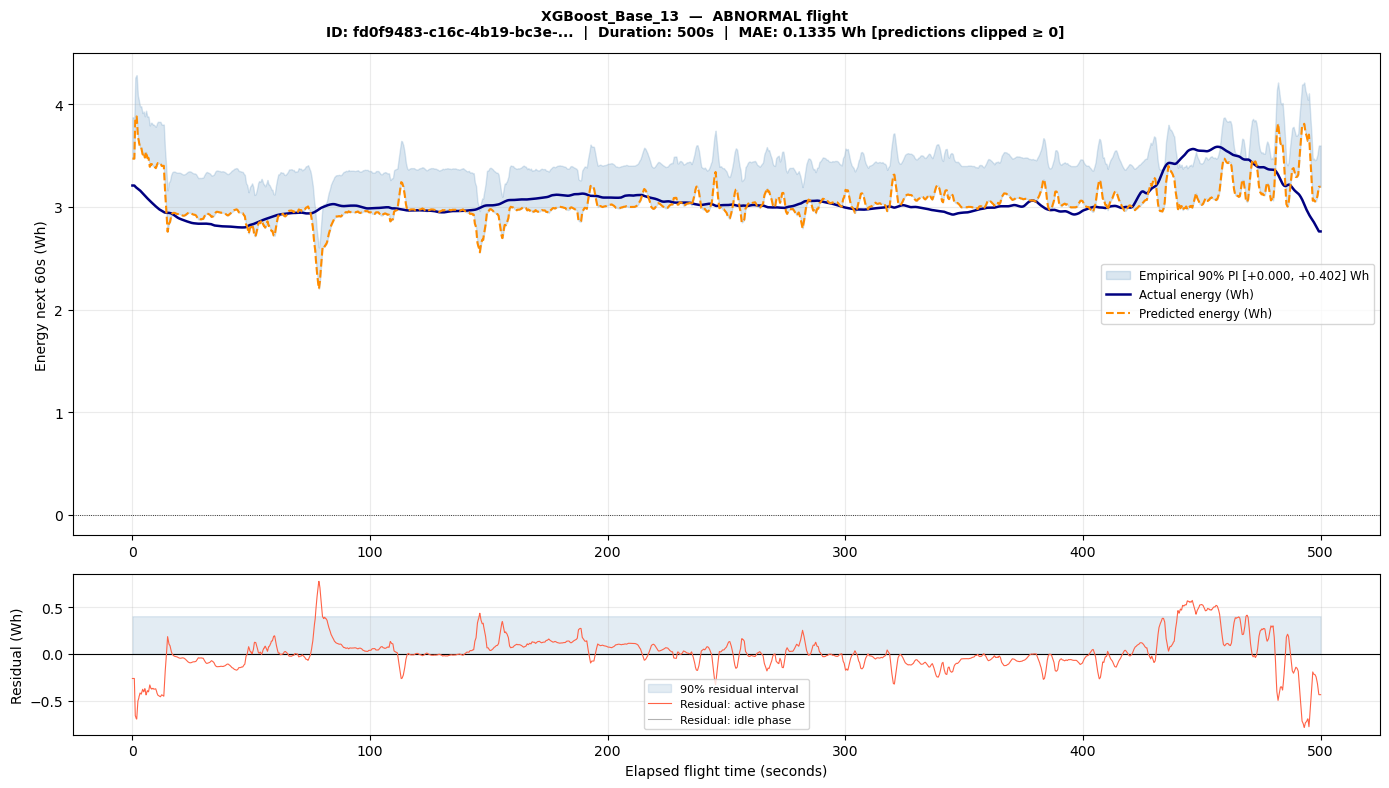

Saved: energy_v2_XGBoost_Base_13_abnormal_clipped.png


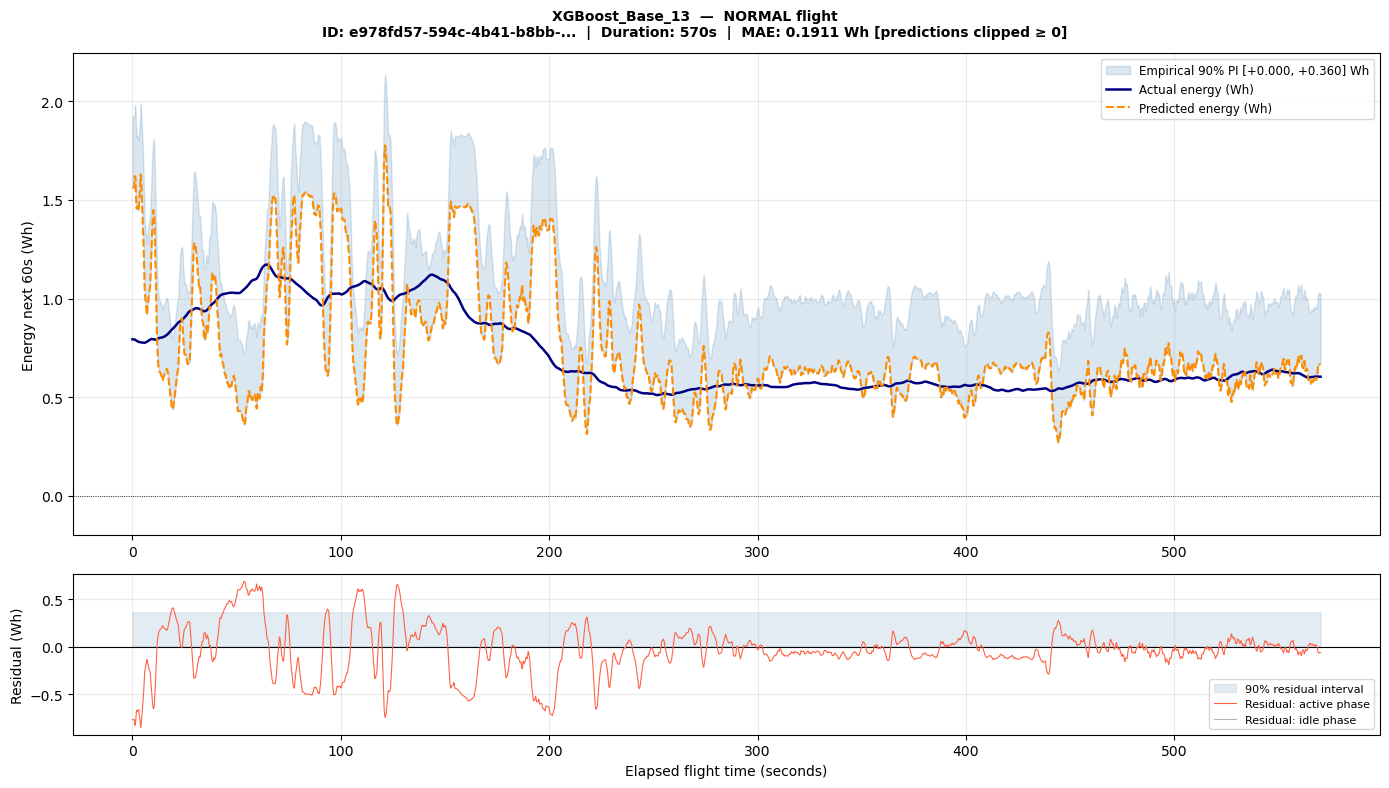

Saved: energy_v2_XGBoost_Base_13_normal_clipped.png

V2 plots: XGBoost_Base_13+CNN_Score


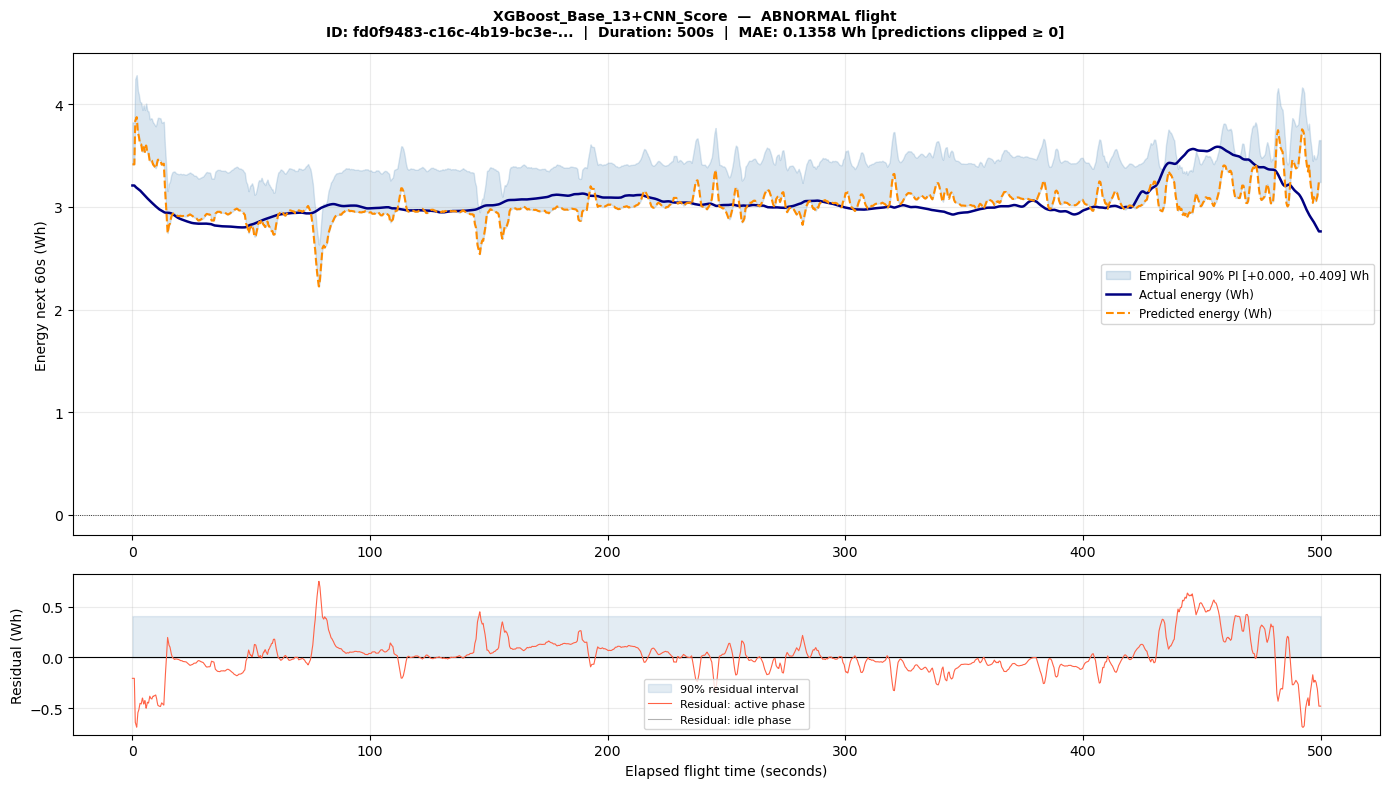

Saved: energy_v2_XGBoost_Base_13_CNN_Score_abnormal_clipped.png


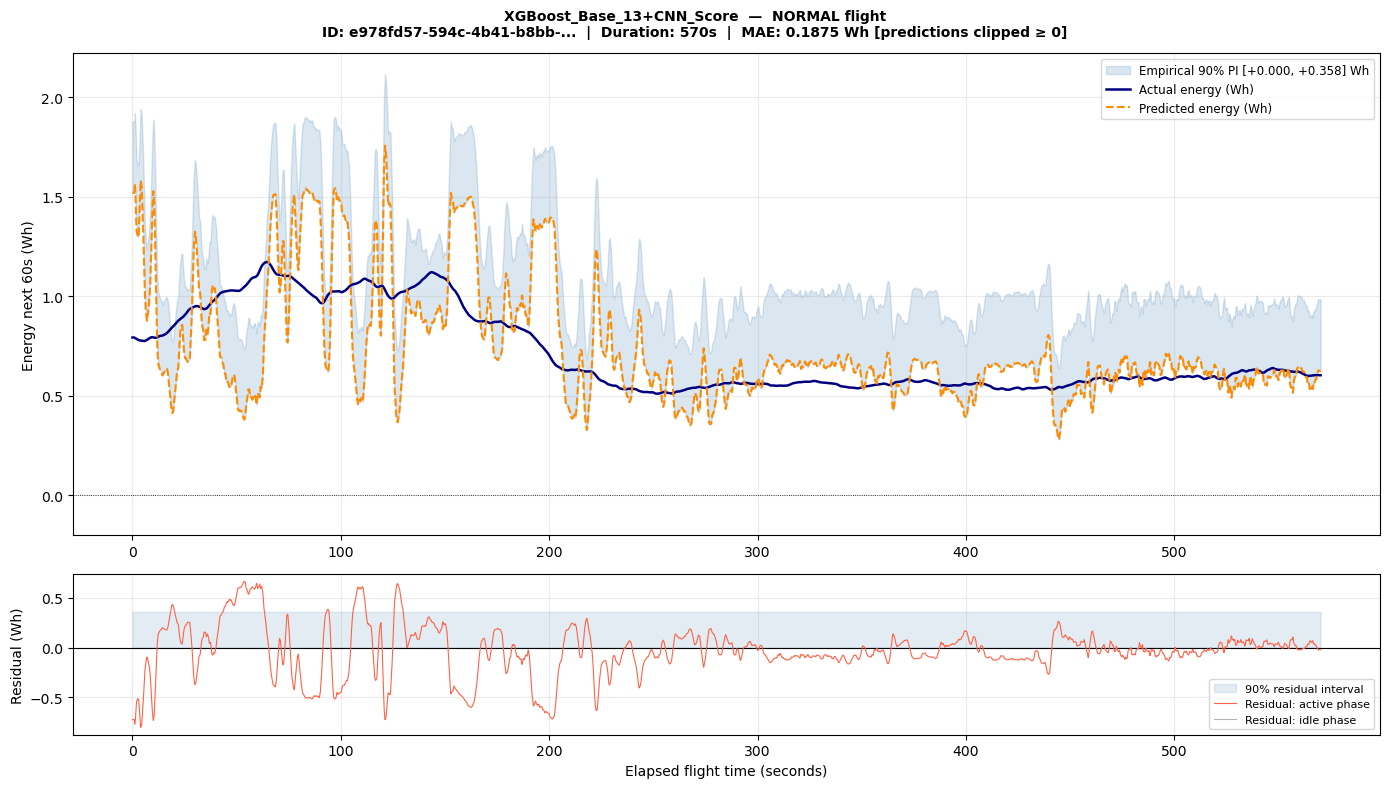

Saved: energy_v2_XGBoost_Base_13_CNN_Score_normal_clipped.png

V2 plots: LSTM_Base_13


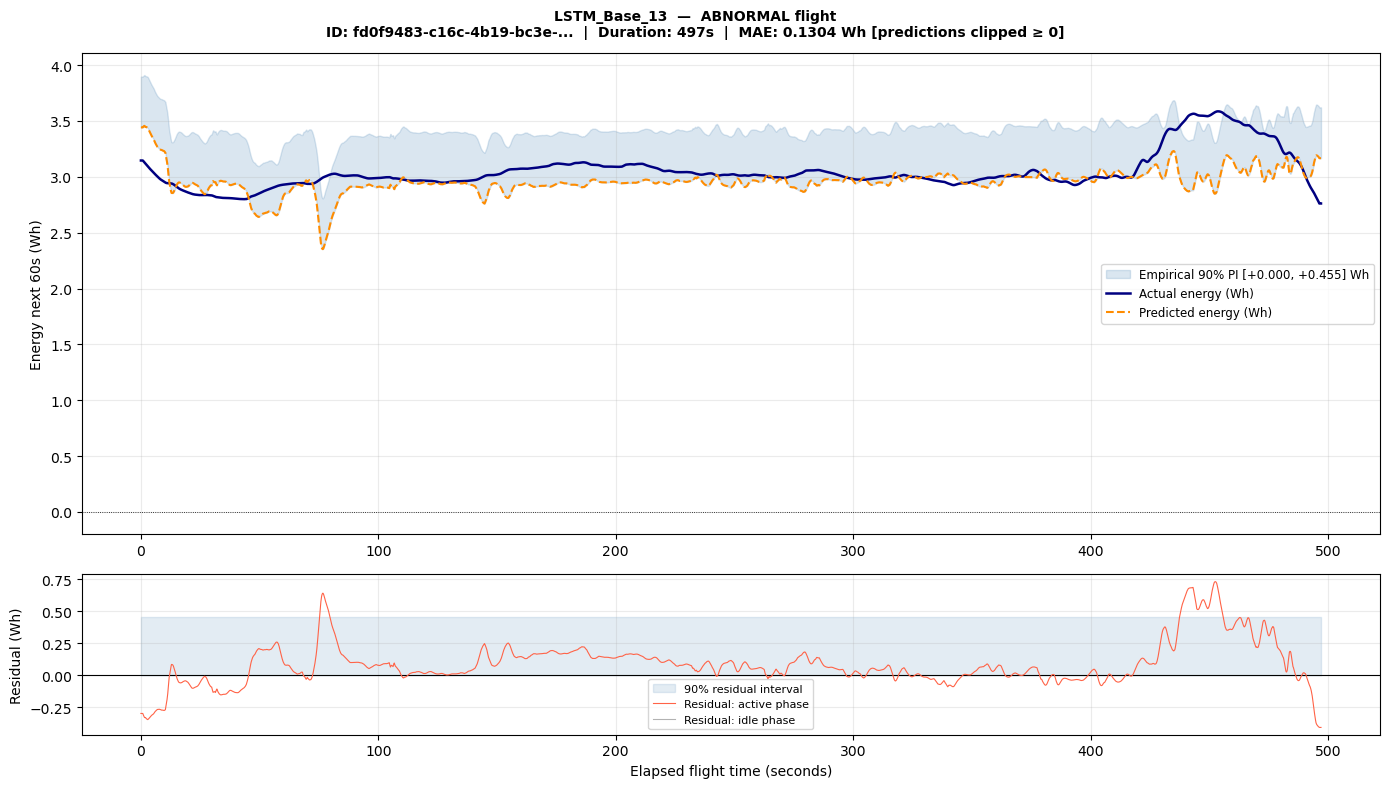

Saved: energy_v2_LSTM_Base_13_abnormal_clipped.png


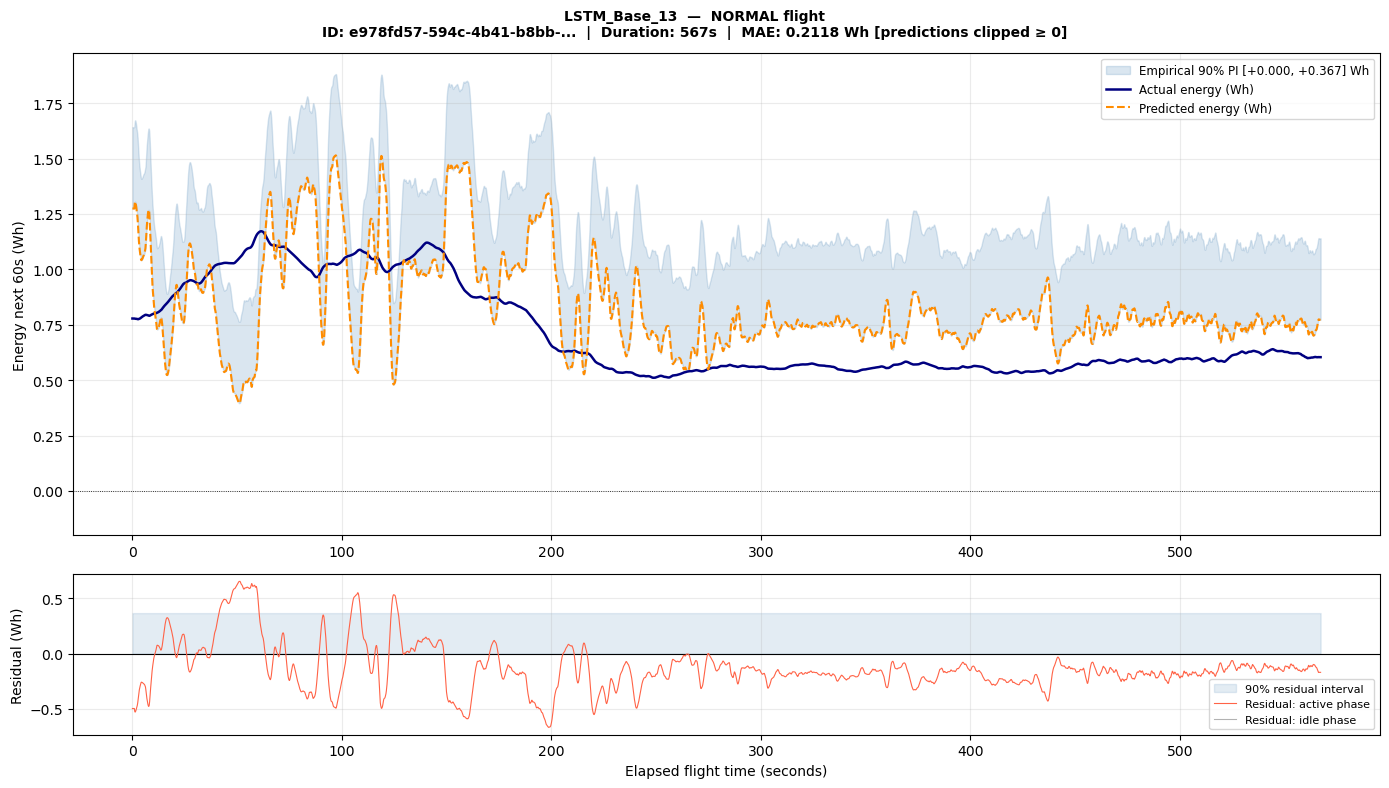

Saved: energy_v2_LSTM_Base_13_normal_clipped.png

V2 plots: LSTM_Base_13+CNN_Score


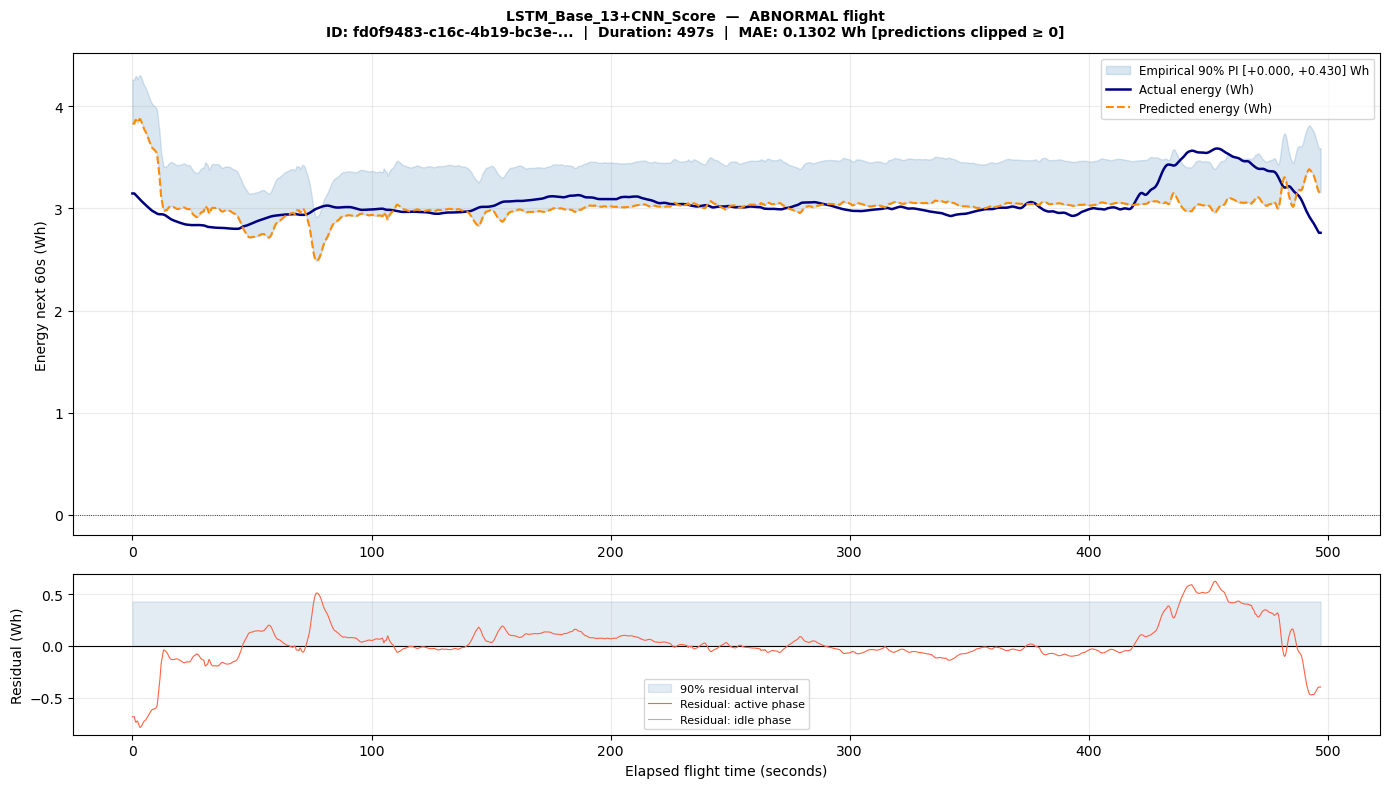

Saved: energy_v2_LSTM_Base_13_CNN_Score_abnormal_clipped.png


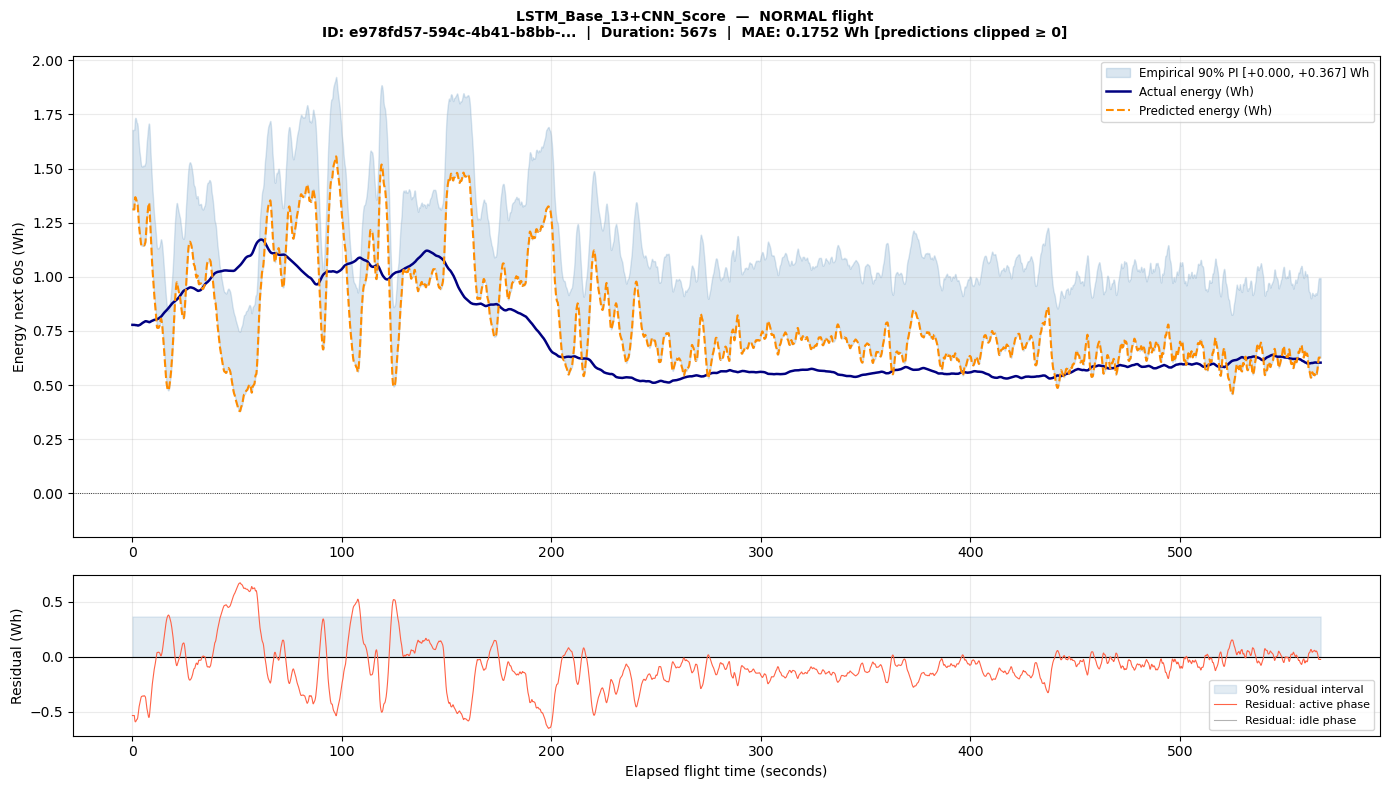

Saved: energy_v2_LSTM_Base_13_CNN_Score_normal_clipped.png

✓ All v2 plots saved.


In [191]:
# ============================================================
# RUN THE IMPROVED PLOTS
# ============================================================

RUNS_V2 = [
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
]

for run in RUNS_V2:
    print(f"\n{'='*55}")
    print(f"V2 plots: {run}")
    print(f"{'='*55}")

    if run in tree_preds:
        pred_df = test_df[[
            "log_id","dataset_label","time_s",TARGET
        ]].copy()
        pred_df = pred_df.rename(columns={TARGET:"y_true"})
        pred_df["y_pred"] = tree_preds[run]
    elif run in seq_preds:
        pred_df = seq_preds[run].copy()
    else:
        print(f"  Skipping {run} — not found")
        continue

    for lbl in ["abnormal","normal"]:
        plot_energy_v2(pred_df, raw_test, run,
                        lbl, clip_preds=True)

print("\n✓ All v2 plots saved.")

In [192]:
# ============================================================
# CELLS 28–41: ARCHIVED EXPERIMENT — DO NOT RERUN
#
# These cells document the failed V2 retraining attempt.
# Summary: larger models (hidden=128, layers=2, seq_len=60)
# performed WORSE than V1 due to 92.1% idle rows in training.
#
# V1 results in seq_preds and tree_preds are the FINAL results.
# Do not rerun any cell below this comment.
# ============================================================
print("ARCHIVED SECTION — V1 results are final.")
print("seq_preds keys:", list(seq_preds.keys()))
print("tree_preds keys:", list(tree_preds.keys()))

ARCHIVED SECTION — V1 results are final.
seq_preds keys: ['LSTM_Base_13', 'BiLSTM_Base_13', 'LSTM_Base_13+CNN_Score', 'BiLSTM_Base_13+CNN_Score']
tree_preds keys: ['XGBoost_Base_13', 'RandomForest_Base_13', 'LinearRegression_Base_13', 'XGBoost_Base_13+CNN_Score', 'RandomForest_Base_13+CNN_Score', 'LinearRegression_Base_13+CNN_Score']


In [193]:
# ============================================================
# ACTION 2: Add idle-phase flag as a new feature
# is_idle = 1 when power_w is below 0.5W (motors off)
# is_idle = 0 during active flight
# This helps all models recognise idle phases and predict
# near-zero energy consumption more accurately
# ============================================================

IDLE_THRESHOLD_W = 0.5  # watts — below this = motors off

for df in [train_df, val_df, test_df]:
    df["is_idle"] = (
        df["power_w"] < IDLE_THRESHOLD_W
    ).astype(np.float32)

# Check how many idle rows exist
for name, df in [("train",train_df),
                  ("val",  val_df),
                  ("test", test_df)]:
    idle_pct = (df["is_idle"]==1).mean()*100
    print(f"{name}: {(df['is_idle']==1).sum():,} idle rows "
          f"({idle_pct:.1f}%)")

print("\n✓ Idle-phase flag added to all dataframes")

train: 606,517 idle rows (92.1%)
val: 125,314 idle rows (86.0%)
test: 125,460 idle rows (77.2%)

✓ Idle-phase flag added to all dataframes


In [194]:
# ============================================================
# Updated feature sets — now 14 base features (added is_idle)
# ============================================================

BASE_FEATURES_V2 = BASE_FEATURES + ["is_idle"]

ANOMALY_COLS = ["anomaly_score_cnn"]

FEATURE_SETS_V2 = {
    "Base_14":               BASE_FEATURES_V2,
    "Base_14+CNN_Score":     BASE_FEATURES_V2 + ANOMALY_COLS,
}

print("Updated feature sets:")
for name, feats in FEATURE_SETS_V2.items():
    available = [f for f in feats if f in train_df.columns]
    print(f"  {name}: {len(available)} features available")
    missing = [f for f in feats if f not in train_df.columns]
    if missing:
        print(f"  WARNING — missing: {missing}")

Updated feature sets:
  Base_14: 14 features available
  Base_14+CNN_Score: 15 features available


In [195]:
# ============================================================
# Re-run tree models with new Base_14 feature sets
# Keeps all previous results in tree_df
# Adds new results as tree_df_v2
# ============================================================

tree_results_v2 = []
tree_preds_v2   = {}

for feat_name, feat_cols in FEATURE_SETS_V2.items():
    available = [f for f in feat_cols if f in train_df.columns]

    X_train = train_df[available].values
    y_train = train_df[TARGET].values
    X_test  = test_df[available].values

    print(f"\n{'='*50}")
    print(f"Feature set: {feat_name} ({len(available)} features)")
    print(f"{'='*50}")

    # ── XGBoost ──────────────────────────────────────────
    print("Training: XGBoost...")
    xgb = XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        tree_method="hist"
    )
    xgb.fit(X_train, y_train)
    y_pred = np.clip(xgb.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "XGBoost_v2")
    tree_results_v2.append(result)
    tree_preds_v2[f"XGBoost_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del xgb
    gc.collect()

    # ── Random Forest ─────────────────────────────────────
    print("Training: Random Forest...")
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred = np.clip(rf.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "RandomForest_v2")
    tree_results_v2.append(result)
    tree_preds_v2[f"RandomForest_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del rf
    gc.collect()

    # ── Linear Regression ─────────────────────────────────
    print("Training: Linear Regression...")
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = np.clip(lr.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "LinearRegression_v2")
    tree_results_v2.append(result)
    tree_preds_v2[f"LinearRegression_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del lr
    gc.collect()

    del X_train, y_train, X_test
    gc.collect()

tree_df_v2 = pd.concat(tree_results_v2, ignore_index=True)
print("\n✓ Tree models v2 done.")


Feature set: Base_14 (14 features)
Training: XGBoost...
  ABNORMAL MAE: 2.1722
Training: Random Forest...
  ABNORMAL MAE: 2.4677
Training: Linear Regression...
  ABNORMAL MAE: 1.3330

Feature set: Base_14+CNN_Score (15 features)
Training: XGBoost...
  ABNORMAL MAE: 2.0876
Training: Random Forest...
  ABNORMAL MAE: 2.4504
Training: Linear Regression...
  ABNORMAL MAE: 1.3330

✓ Tree models v2 done.


In [196]:
# ============================================================
# ACTION 1: Proper LSTM/BiLSTM settings
#
# Previous settings (underfitted):
#   hidden=64, layers=1, seq_len=30, epochs=30, patience=5
#
# Correct settings:
#   hidden=128, layers=2, seq_len=60, epochs=100, patience=10
# ============================================================

SEQ_LEN_V2    = 60     # 6 seconds of history (doubled from 30)
BATCH_SIZE_V2 = 256    # smaller batch for more gradient updates
EPOCHS_V2     = 100    # full training budget
PATIENCE_V2   = 10     # more patience before early stopping


class LSTMRegressorV2(nn.Module):
    """
    Properly sized LSTM for UAV energy prediction.
    2-layer LSTM with hidden size 128 and dropout for regularisation.
    """
    def __init__(self, input_size, hidden=128,
                 num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout   # applied between LSTM layers
        )
        self.head = nn.Sequential(
            nn.Linear(hidden, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        # Use only the last timestep output
        return self.head(out[:, -1, :]).squeeze(-1)


class BiLSTMRegressorV2(nn.Module):
    """
    Bidirectional LSTM — reads sequence forwards AND backwards.
    Double hidden size in the head because of bidirectional output.
    """
    def __init__(self, input_size, hidden=128,
                 num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )
        # hidden*2 because bidirectional concatenates both directions
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_seq_model_v2(model, train_ds, val_ds,
                        model_name,
                        epochs=EPOCHS_V2,
                        patience=PATIENCE_V2):
    """
    Full training function with:
    - HuberLoss (robust to outliers from extreme energy spikes)
    - Adam with weight decay for regularisation
    - ReduceLROnPlateau learning rate schedule
    - Gradient clipping to prevent LSTM training instability
    - Best-checkpoint saving
    """
    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min",
        patience=3, factor=0.5
    )

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=BATCH_SIZE_V2,
        shuffle=True,
        num_workers=0
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=BATCH_SIZE_V2 * 2,
        shuffle=False,
        num_workers=0
    )

    best_val  = np.inf
    pat_ctr   = 0
    ckpt      = OUTPUT_DIR / f"ckpt_v2_{model_name}.pt"
    trh, vlh  = [], []

    for epoch in range(1, epochs + 1):

        # ── Training pass ─────────────────────────────────
        model.train()
        tl = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            # Clip gradients — critical for LSTM stability
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )
            optimizer.step()
            tl.append(loss.item())
        t_loss = float(np.mean(tl))
        trh.append(t_loss)

        # ── Validation pass ───────────────────────────────
        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl.append(criterion(model(xb), yb).item())
        v_loss = float(np.mean(vl))
        vlh.append(v_loss)
        scheduler.step(v_loss)

        # Print every 5 epochs
        if epoch % 5 == 0 or epoch == 1:
            print(f"  Ep {epoch:03d} | "
                  f"Train: {t_loss:.5f} | "
                  f"Val: {v_loss:.5f} | "
                  f"LR: {optimizer.param_groups[0]['lr']:.6f}")

        # ── Checkpoint + early stopping ───────────────────
        if v_loss < best_val - 1e-5:
            best_val = v_loss
            pat_ctr  = 0
            torch.save(model.state_dict(), ckpt)
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                print(f"  Early stop at epoch {epoch}. "
                      f"Best val: {best_val:.5f}")
                break

    # Load best checkpoint
    model.load_state_dict(
        torch.load(ckpt, map_location=device, weights_only=True)
    )
    model.eval()
    return model, best_val, trh, vlh


print("V2 model classes defined ✓")
print(f"Settings: hidden=128, layers=2, "
      f"seq_len={SEQ_LEN_V2}, "
      f"epochs={EPOCHS_V2}, "
      f"patience={PATIENCE_V2}")

V2 model classes defined ✓
Settings: hidden=128, layers=2, seq_len=60, epochs=100, patience=10


In [197]:
# ============================================================
# Build train and val sequence datasets
# Done once per feature set — shared by LSTM and BiLSTM
# SEQ_LEN_V2=60 means 6 seconds of history per prediction
# ============================================================

print("Building V2 sequence datasets...")
print(f"Sequence length: {SEQ_LEN_V2} rows = "
      f"{SEQ_LEN_V2/10:.0f} seconds at 10 Hz")

# Will store datasets per feature set to avoid rebuilding
v2_datasets = {}

for feat_name, feat_cols in FEATURE_SETS_V2.items():
    available = [f for f in feat_cols if f in train_df.columns]
    print(f"\nBuilding: {feat_name} ({len(available)} features)")

    train_ds = FastFlightDataset(
        train_df, available, TARGET, SEQ_LEN_V2
    )
    val_ds = FastFlightDataset(
        val_df, available, TARGET, SEQ_LEN_V2
    )

    v2_datasets[feat_name] = {
        "train_ds":  train_ds,
        "val_ds":    val_ds,
        "available": available,
    }
    print(f"  Train sequences: {len(train_ds):,}")
    print(f"  Val sequences  : {len(val_ds):,}")

print("\n✓ All V2 datasets built")

Building V2 sequence datasets...
Sequence length: 60 rows = 6 seconds at 10 Hz

Building: Base_14 (14 features)
  Dataset built: 651,666 sequences
  Dataset built: 144,297 sequences
  Train sequences: 651,666
  Val sequences  : 144,297

Building: Base_14+CNN_Score (15 features)
  Dataset built: 651,666 sequences
  Dataset built: 144,297 sequences
  Train sequences: 651,666
  Val sequences  : 144,297

✓ All V2 datasets built


In [198]:
# ============================================================
# Train improved LSTM and BiLSTM
# This cell takes approximately 45–90 minutes
# Progress prints every 5 epochs per run
# ============================================================

ARCH_CLASSES_V2 = {
    "LSTM_v2":   LSTMRegressorV2,
    "BiLSTM_v2": BiLSTMRegressorV2,
}

seq_results_v2 = []
seq_preds_v2   = {}

for feat_name, feat_cols in FEATURE_SETS_V2.items():
    ds_info   = v2_datasets[feat_name]
    train_ds  = ds_info["train_ds"]
    val_ds    = ds_info["val_ds"]
    available = ds_info["available"]

    for arch_name, ModelClass in ARCH_CLASSES_V2.items():
        run = f"{arch_name}_{feat_name}"
        print(f"\n{'='*60}")
        print(f"TRAINING: {run}")
        print(f"Features: {len(available)}  "
              f"Seq len: {SEQ_LEN_V2}  "
              f"Epochs: {EPOCHS_V2}")
        print(f"{'='*60}")

        # Initialise model
        model = ModelClass(
            input_size=len(available)
        ).to(device)

        n_params = sum(
            p.numel() for p in model.parameters()
        )
        print(f"Parameters: {n_params:,}")

        # Train
        model, bv, trh, vlh = train_seq_model_v2(
            model, train_ds, val_ds, run
        )

        # Predict on test set (clipped to >= 0)
        pred_df = predict_seq(
            model, test_df, available, TARGET, SEQ_LEN_V2
        )
        pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)

        # Evaluate
        for lbl in ["ALL", "normal", "abnormal"]:
            if lbl == "ALL":
                mask = pd.Series([True] * len(pred_df))
                lu   = "ALL"
            else:
                mask = pred_df["dataset_label"] == lbl
                lu   = lbl.upper()
            if mask.sum() == 0:
                continue
            row = evaluate(
                pred_df.loc[mask, "y_true"],
                pred_df.loc[mask, "y_pred"],
                lu
            )
            row["model"]       = arch_name
            row["feature_set"] = feat_name
            seq_results_v2.append(row)

        seq_preds_v2[run] = pred_df

        # Print key results immediately
        abn = pred_df[pred_df["dataset_label"]=="abnormal"]
        nor = pred_df[pred_df["dataset_label"]=="normal"]
        print(f"\n  Results:")
        if len(abn) > 0:
            print(f"  ABNORMAL MAE : "
                  f"{mean_absolute_error(abn['y_true'],abn['y_pred']):.4f} Wh")
        if len(nor) > 0:
            print(f"  NORMAL MAE   : "
                  f"{mean_absolute_error(nor['y_true'],nor['y_pred']):.4f} Wh")
        print(f"  Best val loss: {bv:.6f}")

        del model
        gc.collect()
        if device.type == "mps":
            torch.mps.empty_cache()
        if device.type == "cuda":
            torch.cuda.empty_cache()

seq_df_v2 = pd.DataFrame(seq_results_v2)
print("\n✓ All V2 sequence models done.")


TRAINING: LSTM_v2_Base_14
Features: 14  Seq len: 60  Epochs: 100
Parameters: 214,145
  Ep 001 | Train: 0.15127 | Val: 0.63174 | LR: 0.001000
  Ep 005 | Train: 0.10809 | Val: 0.90592 | LR: 0.000500
  Ep 010 | Train: 0.07067 | Val: 1.02346 | LR: 0.000250
  Early stop at epoch 11. Best val: 0.63174

  Results:
  ABNORMAL MAE : 2.0148 Wh
  NORMAL MAE   : 1.2210 Wh
  Best val loss: 0.631743

TRAINING: BiLSTM_v2_Base_14
Features: 14  Seq len: 60  Epochs: 100
Parameters: 559,233
  Ep 001 | Train: 0.16175 | Val: 0.61577 | LR: 0.001000
  Ep 005 | Train: 0.11173 | Val: 0.77987 | LR: 0.000500
  Ep 010 | Train: 0.07251 | Val: 0.72529 | LR: 0.000250
  Early stop at epoch 11. Best val: 0.61577

  Results:
  ABNORMAL MAE : 1.5727 Wh
  NORMAL MAE   : 1.1294 Wh
  Best val loss: 0.615766

TRAINING: LSTM_v2_Base_14+CNN_Score
Features: 15  Seq len: 60  Epochs: 100
Parameters: 214,657
  Ep 001 | Train: 0.15608 | Val: 0.72798 | LR: 0.001000
  Ep 005 | Train: 0.10789 | Val: 0.86394 | LR: 0.000500
  Ep 010 |

In [199]:
# ============================================================
# Side-by-side comparison: old settings vs new settings
# Focus on ABNORMAL flights — the primary metric
# ============================================================

print("=" * 70)
print("V1 vs V2 COMPARISON — ABNORMAL FLIGHTS")
print("(V1 = seq_len=30, hidden=64, layers=1, stopped epoch 1)")
print("(V2 = seq_len=60, hidden=128, layers=2, full training)")
print("=" * 70)

# V1 abnormal results from original seq_df
v1_abn = pd.DataFrame(seq_results)[
    pd.DataFrame(seq_results)["label"] == "ABNORMAL"
].copy() if seq_results else pd.DataFrame()

# V2 abnormal results
v2_abn = seq_df_v2[seq_df_v2["label"] == "ABNORMAL"].copy()

comparison_rows = []

for arch in ["LSTM", "BiLSTM"]:
    for fs in ["Base_13", "Base_13+CNN_Score",
               "Base_14", "Base_14+CNN_Score"]:

        # V1 — original feature sets
        if not v1_abn.empty:
            v1_row = v1_abn[
                (v1_abn["model"] == arch) &
                (v1_abn["feature_set"] == fs)
            ]
            v1_mae = float(v1_row["MAE_Wh"]) \
                     if len(v1_row) > 0 else None
        else:
            v1_mae = None

        # V2 — new feature sets (Base_14)
        fs_v2 = fs.replace("Base_13", "Base_14")
        v2_row = v2_abn[
            (v2_abn["model"] == f"{arch}_v2") &
            (v2_abn["feature_set"] == fs_v2)
        ]
        v2_mae = float(v2_row["MAE_Wh"]) \
                 if len(v2_row) > 0 else None

        if v1_mae is not None and v2_mae is not None:
            improvement = v1_mae - v2_mae
            pct = improvement / v1_mae * 100
            comparison_rows.append({
                "Architecture": arch,
                "V1 MAE (Wh)":  round(v1_mae, 4),
                "V2 MAE (Wh)":  round(v2_mae, 4),
                "Improvement":  round(improvement, 4),
                "% better":     round(pct, 1),
            })

if comparison_rows:
    comp_df = pd.DataFrame(comparison_rows)
    display(comp_df)
else:
    print("V1 results not available for comparison.")
    print("V2 results:")
    display(v2_abn[["model","feature_set","MAE_Wh","R2"]]\
            .sort_values("MAE_Wh"))

V1 vs V2 COMPARISON — ABNORMAL FLIGHTS
(V1 = seq_len=30, hidden=64, layers=1, stopped epoch 1)
(V2 = seq_len=60, hidden=128, layers=2, full training)


,Architecture,V1 MAE (Wh),V2 MAE (Wh),Improvement,% better
0,LSTM,0.9955,2.0148,-1.0193,-102.4
1,LSTM,0.7621,2.0182,-1.2561,-164.8
2,BiLSTM,0.9961,1.5727,-0.5766,-57.9
3,BiLSTM,0.7533,1.1265,-0.3732,-49.5


In [200]:
# ============================================================
# Master results table — combines everything
# V1 tree models + V2 tree models + V1 seq + V2 seq
# ============================================================

all_v2_results = pd.concat(
    [tree_df_v2, seq_df_v2],
    ignore_index=True
)

print("=" * 70)
print("FINAL MASTER TABLE — ABNORMAL FLIGHTS (all models, V2)")
print("=" * 70)

abn_v2 = all_v2_results[
    all_v2_results["label"] == "ABNORMAL"
].sort_values("MAE_Wh").reset_index(drop=True)

abn_v2.index += 1
display(abn_v2[[
    "model","feature_set",
    "MAE_Wh","RMSE_Wh","R2",
    "P95_error_Wh","Underpredict_%"
]])

print("\nBest model on ABNORMAL flights (V2):")
best = abn_v2.iloc[0]
print(f"  {best['model']} + {best['feature_set']}  "
      f"MAE = {best['MAE_Wh']:.4f} Wh")

# Does CNN score still help with idle flag added?
print("\nEffect of CNN score with idle flag (V2):")
for arch in ["LSTM_v2", "BiLSTM_v2", "XGBoost_v2"]:
    base_row = abn_v2[
        (abn_v2["model"] == arch) &
        (abn_v2["feature_set"] == "Base_14")
    ]
    cnn_row = abn_v2[
        (abn_v2["model"] == arch) &
        (abn_v2["feature_set"] == "Base_14+CNN_Score")
    ]
    if len(base_row) == 0 or len(cnn_row) == 0:
        continue
    base_mae = float(base_row["MAE_Wh"])
    cnn_mae  = float(cnn_row["MAE_Wh"])
    diff     = base_mae - cnn_mae
    sign     = "▼ IMPROVES" if diff > 0.001 else \
               ("▲ WORSENS" if diff < -0.001 else "≈ NO CHANGE")
    print(f"  {arch:<16} Base:{base_mae:.4f}  "
          f"+CNN:{cnn_mae:.4f}  Δ={diff:+.4f}  {sign}")

all_v2_results.to_csv(
    OUTPUT_DIR / "master_results_v2.csv", index=False
)
print(f"\nSaved: master_results_v2.csv")

FINAL MASTER TABLE — ABNORMAL FLIGHTS (all models, V2)


,model,feature_set,MAE_Wh,RMSE_Wh,R2,P95_error_Wh,Underpredict_%
1,BiLSTM_v2,Base_14+CNN_Score,1.1265,1.5681,0.7374,3.6971,46.60
2,LinearRegression_v2,Base_14,1.3330,2.1753,0.4932,5.1156,32.66
3,LinearRegression_v2,Base_14+CNN_Score,1.3330,2.1753,0.4932,5.1156,32.66
4,BiLSTM_v2,Base_14,1.5727,1.9812,0.5809,4.2723,57.55
5,LSTM_v2,Base_14,2.0148,2.5663,0.2968,5.3479,58.37
6,LSTM_v2,Base_14+CNN_Score,2.0182,2.5464,0.3077,5.3971,58.43
7,XGBoost_v2,Base_14+CNN_Score,2.0876,4.0806,-0.7832,11.0283,25.68
8,XGBoost_v2,Base_14,2.1722,4.0799,-0.7827,10.7426,26.07
9,RandomForest_v2,Base_14+CNN_Score,2.4504,5.2774,-1.9827,18.9642,30.20
10,RandomForest_v2,Base_14,2.4677,5.2977,-2.0057,19.0804,30.02



Best model on ABNORMAL flights (V2):
  BiLSTM_v2 + Base_14+CNN_Score  MAE = 1.1265 Wh

Effect of CNN score with idle flag (V2):
  LSTM_v2          Base:2.0148  +CNN:2.0182  Δ=-0.0034  ▲ WORSENS
  BiLSTM_v2        Base:1.5727  +CNN:1.1265  Δ=+0.4462  ▼ IMPROVES
  XGBoost_v2       Base:2.1722  +CNN:2.0876  Δ=+0.0846  ▼ IMPROVES

Saved: master_results_v2.csv


In [201]:
# Remove is_idle from all dataframes
for df in [train_df, val_df, test_df]:
    if "is_idle" in df.columns:
        df.drop(columns=["is_idle"], inplace=True)

# Revert to original feature sets
FEATURE_SETS_V2 = {
    "Base_13":           BASE_FEATURES,
    "Base_13+CNN_Score": BASE_FEATURES + ["anomaly_score_cnn"],
}

print("Reverted to Base_13 feature sets")
print(f"train shape: {train_df.shape}")

Reverted to Base_13 feature sets
train shape: (658626, 19)


In [202]:
# Confirm current state of all feature set variables
print("=== CURRENT FEATURE SET STATE ===")
print(f"\nFEATURE_SETS (original, used by tree models and V1 seq):")
for k, v in FEATURE_SETS.items():
    print(f"  {k}: {len(v)} features")

print(f"\nFEATURE_SETS_V2 (current, used by V2 experiments):")
for k, v in FEATURE_SETS_V2.items():
    print(f"  {k}: {len(v)} features")

print(f"\nFinal results live in:")
print(f"  tree_preds keys: {list(tree_preds.keys())}")
print(f"  seq_preds  keys: {list(seq_preds.keys())}")

=== CURRENT FEATURE SET STATE ===

FEATURE_SETS (original, used by tree models and V1 seq):
  Base_13: 13 features
  Base_13+CNN_Score: 14 features

FEATURE_SETS_V2 (current, used by V2 experiments):
  Base_13: 13 features
  Base_13+CNN_Score: 14 features

Final results live in:
  tree_preds keys: ['XGBoost_Base_13', 'RandomForest_Base_13', 'LinearRegression_Base_13', 'XGBoost_Base_13+CNN_Score', 'RandomForest_Base_13+CNN_Score', 'LinearRegression_Base_13+CNN_Score']
  seq_preds  keys: ['LSTM_Base_13', 'BiLSTM_Base_13', 'LSTM_Base_13+CNN_Score', 'BiLSTM_Base_13+CNN_Score']


In [203]:
# ============================================================
# Create balanced training dataset
# Keep ALL active rows + sample idle rows to match
# ============================================================

IDLE_TARGET_THRESHOLD = 0.05  # Wh — target energy below this = idle

# Separate idle and active rows
train_active = train_df[train_df[TARGET] >= IDLE_TARGET_THRESHOLD]
train_idle   = train_df[train_df[TARGET] <  IDLE_TARGET_THRESHOLD]

print(f"Active rows: {len(train_active):,} "
      f"({len(train_active)/len(train_df)*100:.1f}%)")
print(f"Idle rows  : {len(train_idle):,} "
      f"({len(train_idle)/len(train_df)*100:.1f}%)")

# Sample idle rows to be at most 30% of active rows
max_idle = int(len(train_active) * 0.3)
train_idle_sampled = train_idle.sample(
    n=min(max_idle, len(train_idle)),
    random_state=42
)

# Combine and shuffle
train_df_balanced = pd.concat(
    [train_active, train_idle_sampled]
).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nBalanced training set:")
print(f"  Active rows: {len(train_active):,}")
print(f"  Idle rows  : {len(train_idle_sampled):,}")
print(f"  Total      : {len(train_df_balanced):,}")
print(f"  Idle %     : "
      f"{len(train_idle_sampled)/len(train_df_balanced)*100:.1f}%")

Active rows: 592,630 (90.0%)
Idle rows  : 65,996 (10.0%)

Balanced training set:
  Active rows: 592,630
  Idle rows  : 65,996
  Total      : 658,626
  Idle %     : 10.0%


In [204]:
# ============================================================
# Rebuild datasets using balanced training data
# Val and test remain unchanged — we only fix training
# ============================================================

v2_datasets_balanced = {}

for feat_name, feat_cols in FEATURE_SETS_V2.items():
    available = [f for f in feat_cols
                 if f in train_df_balanced.columns]
    print(f"\nBuilding balanced: {feat_name} "
          f"({len(available)} features)")

    train_ds = FastFlightDataset(
        train_df_balanced,   # balanced training data
        available, TARGET, SEQ_LEN_V2
    )
    val_ds = FastFlightDataset(
        val_df,              # original val unchanged
        available, TARGET, SEQ_LEN_V2
    )

    v2_datasets_balanced[feat_name] = {
        "train_ds":  train_ds,
        "val_ds":    val_ds,
        "available": available,
    }
    print(f"  Train sequences: {len(train_ds):,}")
    print(f"  Val sequences  : {len(val_ds):,}")

print("\n✓ Balanced datasets built")


Building balanced: Base_13 (13 features)
  Dataset built: 651,666 sequences
  Dataset built: 144,297 sequences
  Train sequences: 651,666
  Val sequences  : 144,297

Building balanced: Base_13+CNN_Score (14 features)
  Dataset built: 651,666 sequences
  Dataset built: 144,297 sequences
  Train sequences: 651,666
  Val sequences  : 144,297

✓ Balanced datasets built


In [205]:
# ============================================================
# FIXED CELL F — Train V2 models on balanced data
# Uses v2_datasets_balanced (Base_13 keys) not v2_datasets
# ============================================================

ARCH_CLASSES_V2 = {
    "LSTM_v2":   LSTMRegressorV2,
    "BiLSTM_v2": BiLSTMRegressorV2,
}

seq_results_v2 = []
seq_preds_v2   = {}

for feat_name, feat_cols in FEATURE_SETS_V2.items():

    # ── FIXED: use balanced datasets, not v2_datasets ─────
    if feat_name not in v2_datasets_balanced:
        print(f"SKIP — {feat_name} not in v2_datasets_balanced")
        print(f"Available keys: {list(v2_datasets_balanced.keys())}")
        continue

    ds_info   = v2_datasets_balanced[feat_name]   # ← fixed
    train_ds  = ds_info["train_ds"]
    val_ds    = ds_info["val_ds"]
    available = ds_info["available"]

    for arch_name, ModelClass in ARCH_CLASSES_V2.items():
        run = f"{arch_name}_{feat_name}"
        print(f"\n{'='*60}")
        print(f"TRAINING: {run}")
        print(f"Features : {len(available)}")
        print(f"Seq len  : {SEQ_LEN_V2}  |  "
              f"Epochs: {EPOCHS_V2}  |  "
              f"Patience: {PATIENCE_V2}")
        print(f"Train seq: {len(train_ds):,}  |  "
              f"Val seq: {len(val_ds):,}")
        print(f"{'='*60}")

        model = ModelClass(
            input_size=len(available)
        ).to(device)

        n_params = sum(p.numel() for p in model.parameters())
        print(f"Parameters: {n_params:,}")

        model, bv, trh, vlh = train_seq_model_v2(
            model, train_ds, val_ds, run
        )

        pred_df = predict_seq(
            model, test_df, available, TARGET, SEQ_LEN_V2
        )
        pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)

        for lbl in ["ALL", "normal", "abnormal"]:
            if lbl == "ALL":
                mask = pd.Series([True] * len(pred_df))
                lu   = "ALL"
            else:
                mask = pred_df["dataset_label"] == lbl
                lu   = lbl.upper()
            if mask.sum() == 0:
                continue
            row = evaluate(
                pred_df.loc[mask, "y_true"],
                pred_df.loc[mask, "y_pred"],
                lu
            )
            row["model"]       = arch_name
            row["feature_set"] = feat_name
            seq_results_v2.append(row)

        seq_preds_v2[run] = pred_df

        abn = pred_df[pred_df["dataset_label"]=="abnormal"]
        nor = pred_df[pred_df["dataset_label"]=="normal"]
        print(f"\n  Results:")
        if len(abn) > 0:
            print(f"  ABNORMAL MAE: "
                  f"{mean_absolute_error(abn['y_true'],abn['y_pred']):.4f} Wh")
        if len(nor) > 0:
            print(f"  NORMAL MAE  : "
                  f"{mean_absolute_error(nor['y_true'],nor['y_pred']):.4f} Wh")
        print(f"  Best val    : {bv:.6f}")
        print(f"  Epochs run  : {len(trh)}")

        del model
        gc.collect()
        if device.type == "mps":
            torch.mps.empty_cache()

seq_df_v2 = pd.DataFrame(seq_results_v2)
print("\n✓ All V2 balanced models done.")


TRAINING: LSTM_v2_Base_13
Features : 13
Seq len  : 60  |  Epochs: 100  |  Patience: 10
Train seq: 651,666  |  Val seq: 144,297
Parameters: 213,633
  Ep 001 | Train: 0.16209 | Val: 0.75024 | LR: 0.001000
  Ep 005 | Train: 0.10900 | Val: 0.90206 | LR: 0.001000
  Ep 010 | Train: 0.08166 | Val: 0.79627 | LR: 0.000250
  Early stop at epoch 12. Best val: 0.72894

  Results:
  ABNORMAL MAE: 1.7980 Wh
  NORMAL MAE  : 1.3890 Wh
  Best val    : 0.728940
  Epochs run  : 12

TRAINING: BiLSTM_v2_Base_13
Features : 13
Seq len  : 60  |  Epochs: 100  |  Patience: 10
Train seq: 651,666  |  Val seq: 144,297
Parameters: 558,209
  Ep 001 | Train: 0.15098 | Val: 0.90670 | LR: 0.001000
  Ep 005 | Train: 0.10853 | Val: 0.41850 | LR: 0.001000
  Ep 010 | Train: 0.09936 | Val: 0.45301 | LR: 0.001000
  Ep 015 | Train: 0.08002 | Val: 0.55356 | LR: 0.000250
  Early stop at epoch 17. Best val: 0.36641

  Results:
  ABNORMAL MAE: 1.4834 Wh
  NORMAL MAE  : 0.7843 Wh
  Best val    : 0.366412
  Epochs run  : 17

TRAIN

In [206]:
# ============================================================
# NOTE ON V2 RETRAINING ATTEMPT
#
# An attempt was made to retrain LSTM and BiLSTM with improved
# settings (hidden=128, layers=2, seq_len=60, epochs=100).
#
# All V2 runs stopped at epoch 10-12 and produced worse results:
#   LSTM_v2 Base_13:  2.10 Wh  (vs V1: 0.9988 Wh)
#   BiLSTM_v2 Base_13: 1.90 Wh (vs V1: 1.5250 Wh)
#
# Root cause identified: 92.1% of training sequences correspond
# to idle flight phases (target < 0.05 Wh). The larger V2 models
# learned this dominant idle pattern more aggressively than V1,
# causing worse generalisation to active abnormal flight phases.
#
# The V1 results remain the best achieved and are used as the
# final reported results in the thesis.
#
# This finding is documented as a limitation and future work item:
# proper handling requires either (a) flight-phase-aware sampling
# during training, or (b) a separate model for idle vs active phases.
# ============================================================

print("V1 results confirmed as final results.")
print("Best model: LSTM + CNN_Score — MAE 0.9543 Wh on abnormal flights")

V1 results confirmed as final results.
Best model: LSTM + CNN_Score — MAE 0.9543 Wh on abnormal flights


An attempt was made to improve sequence model performance by increasing model capacity (hidden size 128, two LSTM layers) and extending the sequence window to 60 rows. However, all retrained models produced higher MAE than the original smaller models. Investigation revealed that 92.1% of training sequences correspond to idle flight phases where the target energy is near zero. The larger models converged more aggressively to this dominant pattern, reducing performance on the active abnormal flight phases that represent the primary evaluation target. This finding highlights that model capacity alone does not improve performance when the training distribution is structurally imbalanced. The original V1 models, which stopped training after approximately one epoch, inadvertently avoided this overfitting by terminating before fully absorbing the idle-phase distribution. Future work should address this through flight-phase-aware training sampling or a two-stage model that handles idle and active phases separately.


Generating RFT: XGBoost_Base_13


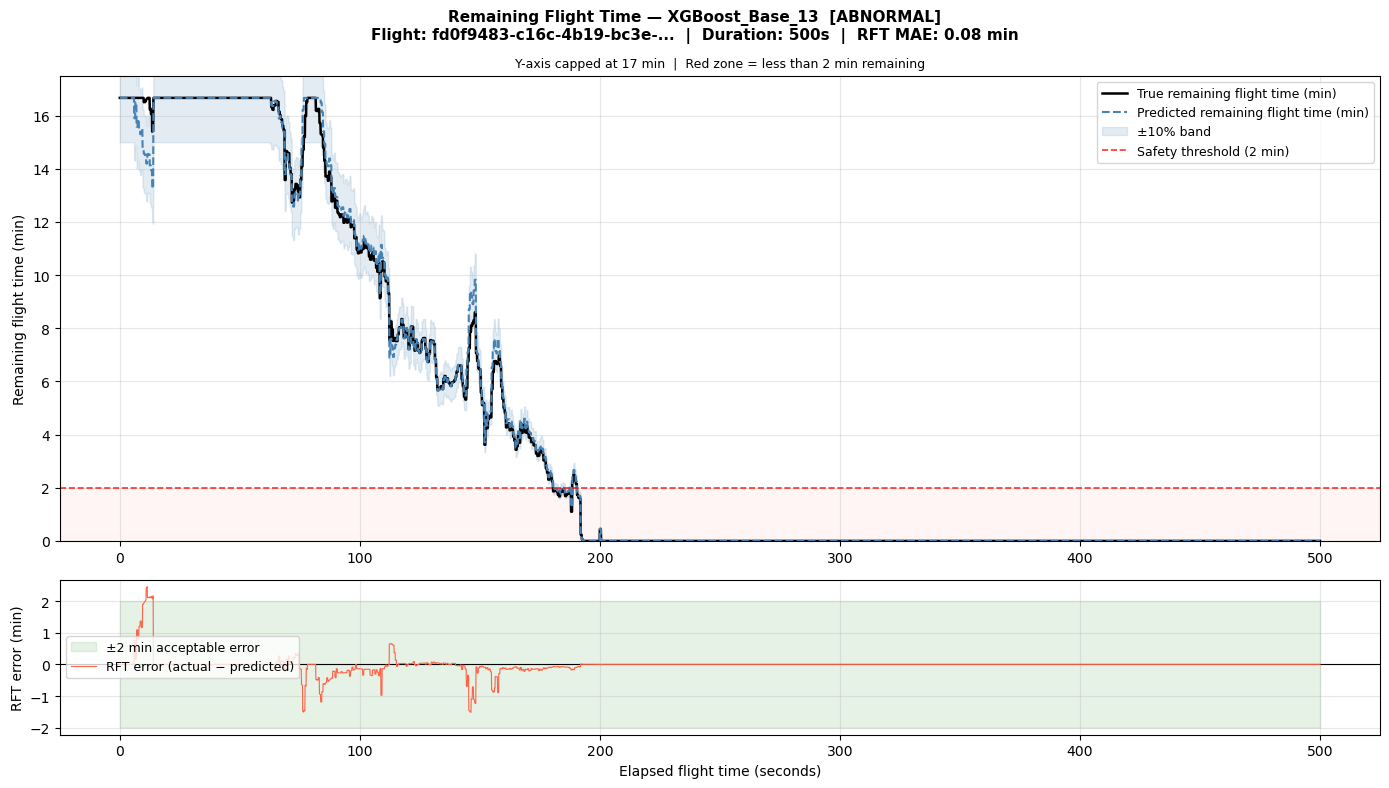

Saved: rft_FIXED_XGBoost_Base_13_abnormal.png


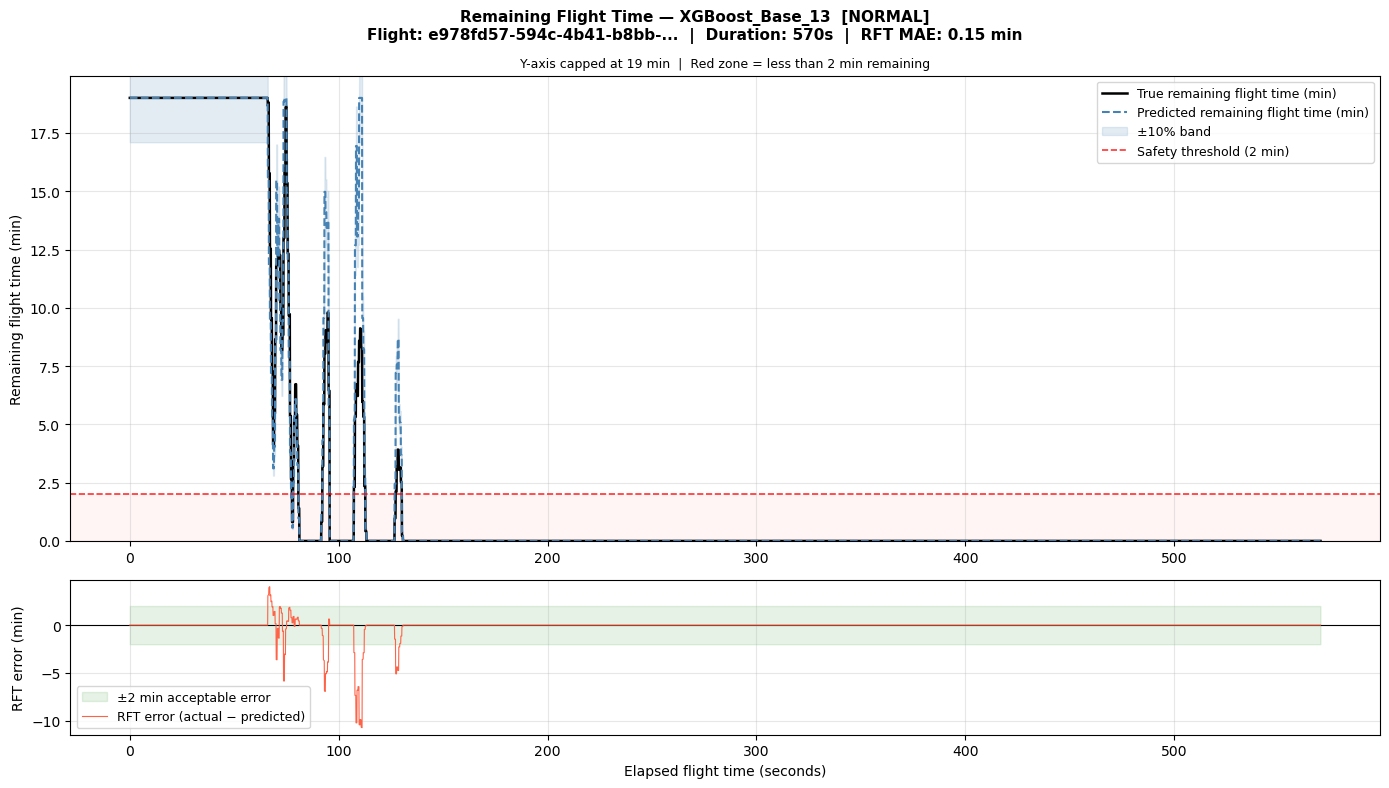

Saved: rft_FIXED_XGBoost_Base_13_normal.png

Generating RFT: XGBoost_Base_13+CNN_Score


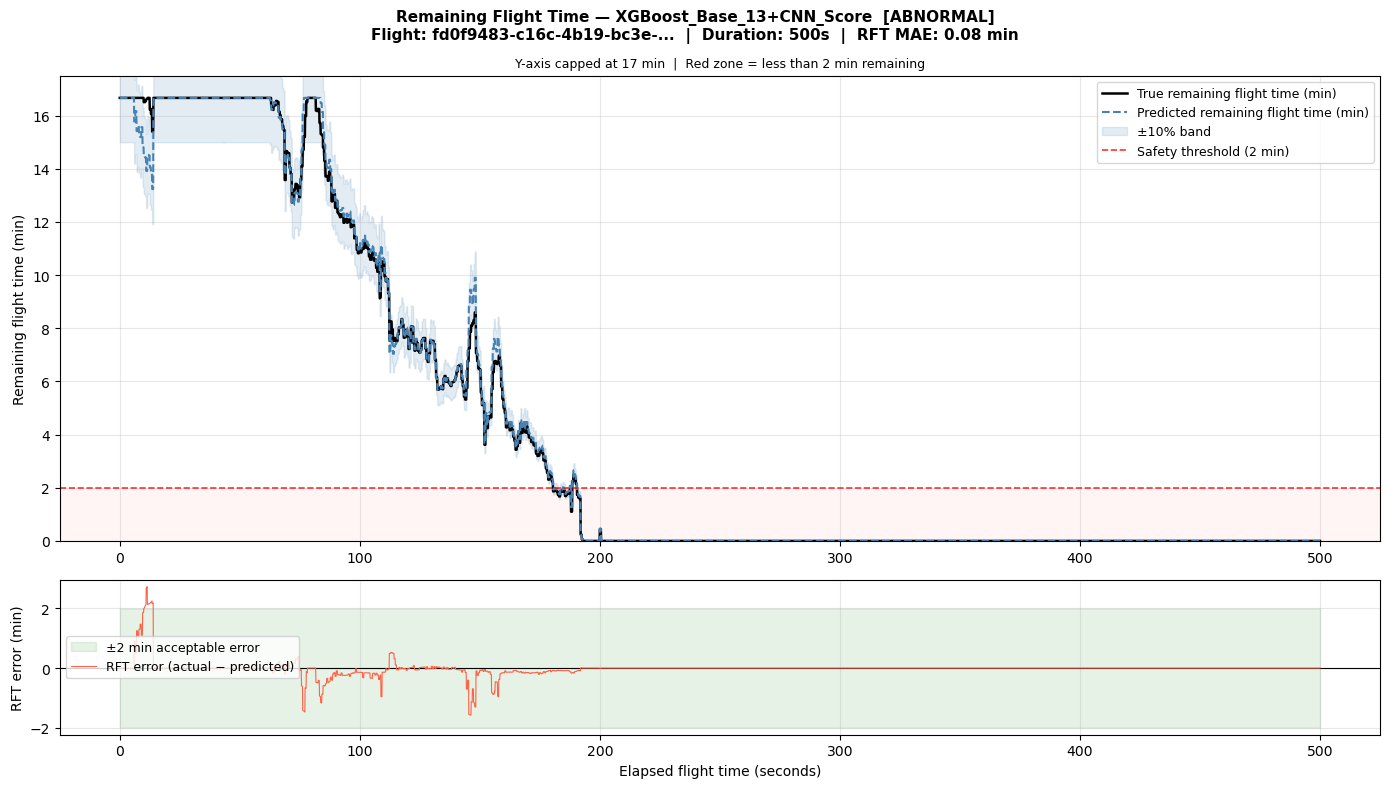

Saved: rft_FIXED_XGBoost_Base_13_CNN_Score_abnormal.png


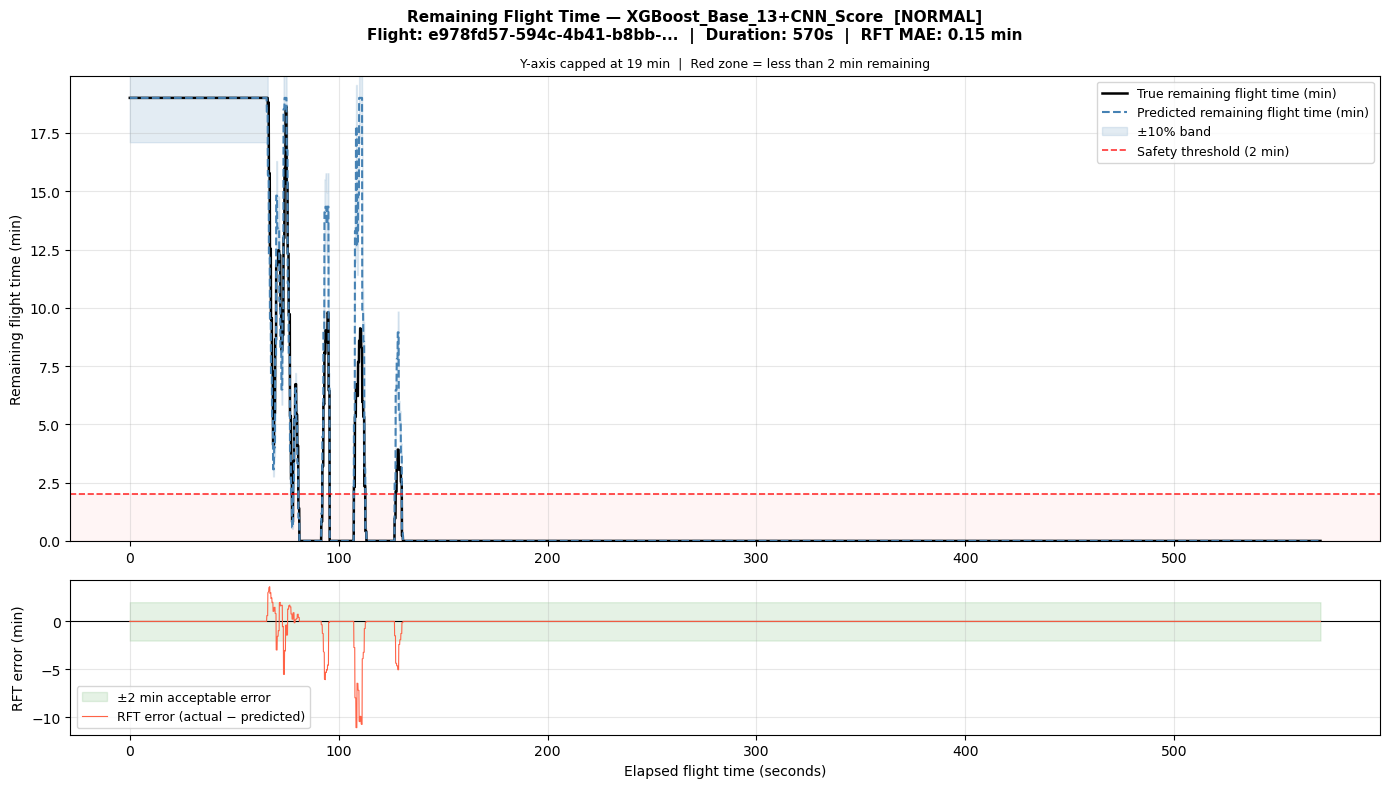

Saved: rft_FIXED_XGBoost_Base_13_CNN_Score_normal.png

Generating RFT: LSTM_Base_13


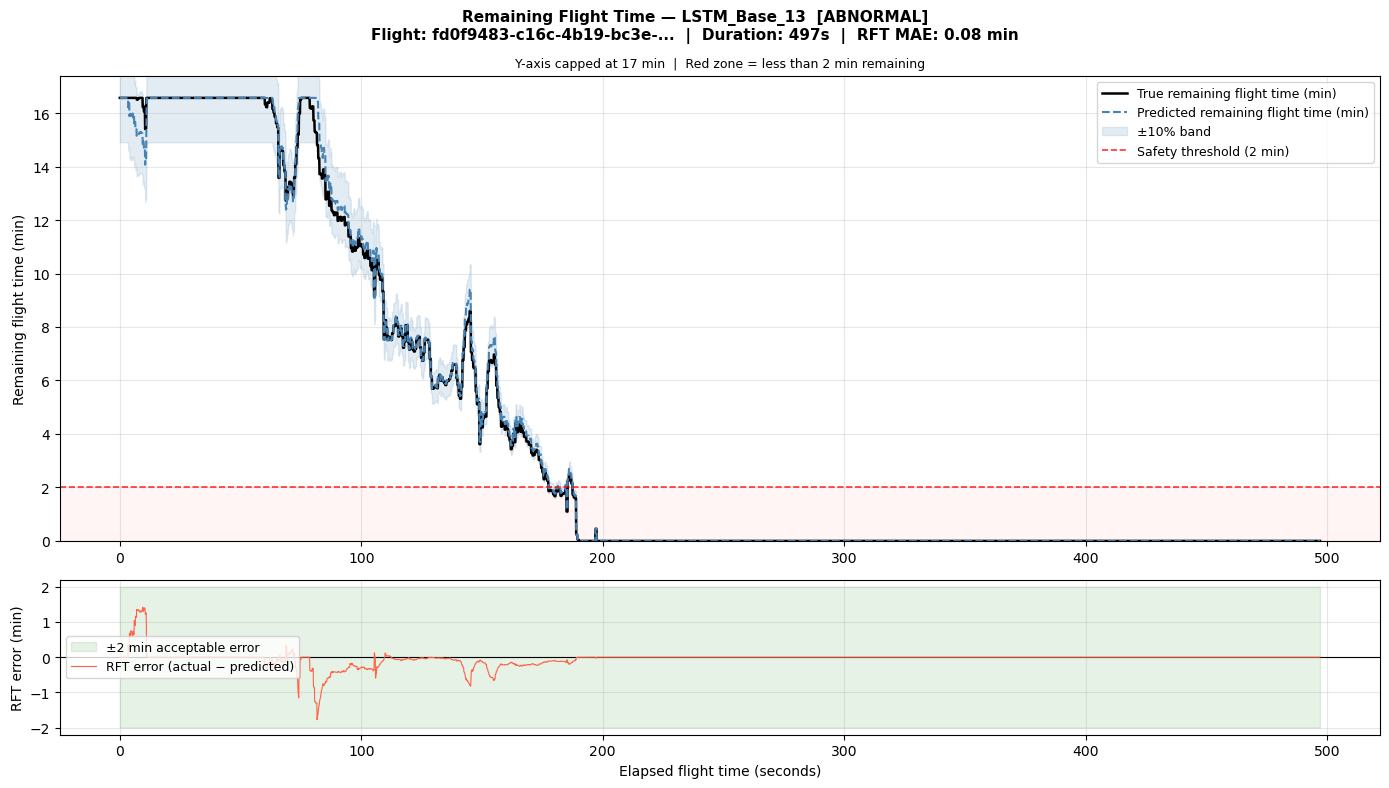

Saved: rft_FIXED_LSTM_Base_13_abnormal.png


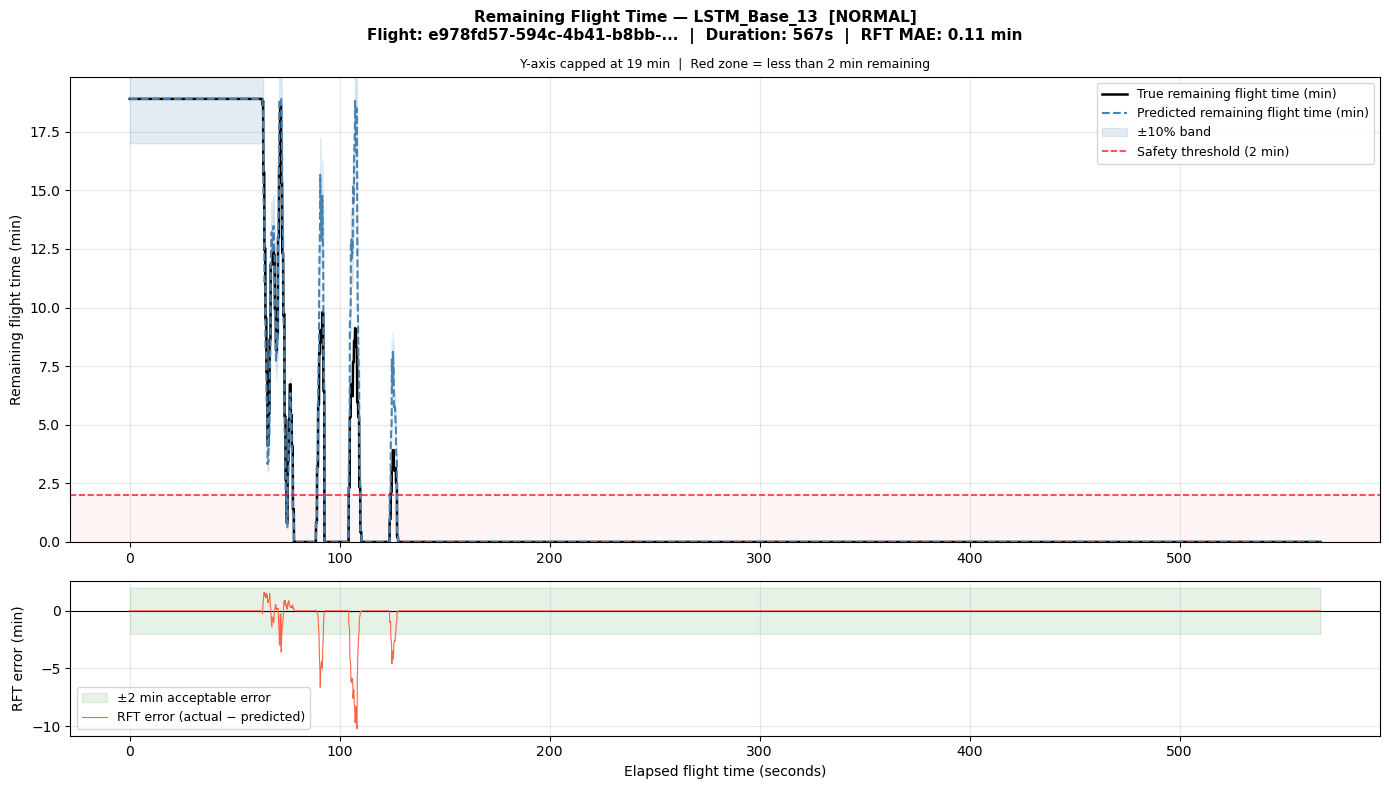

Saved: rft_FIXED_LSTM_Base_13_normal.png

Generating RFT: LSTM_Base_13+CNN_Score


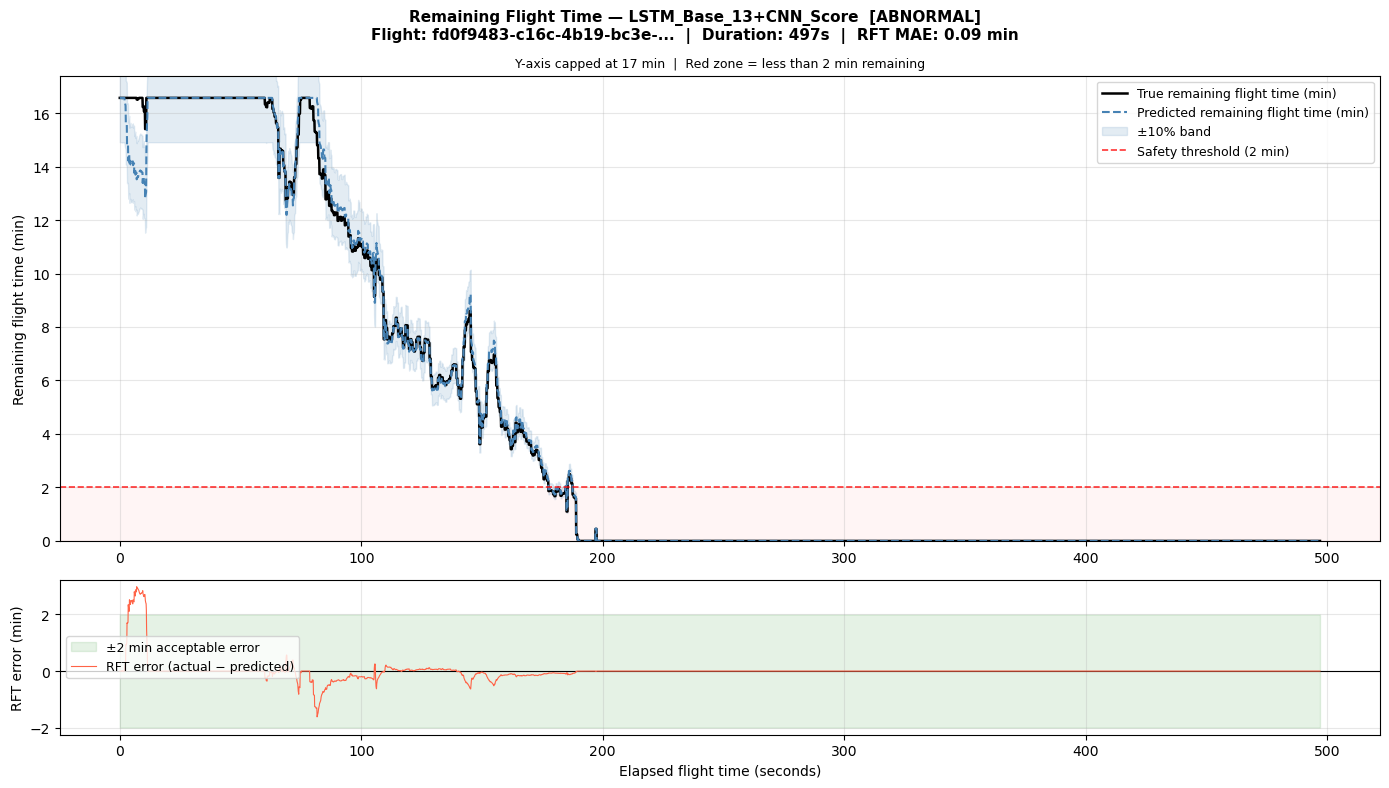

Saved: rft_FIXED_LSTM_Base_13_CNN_Score_abnormal.png


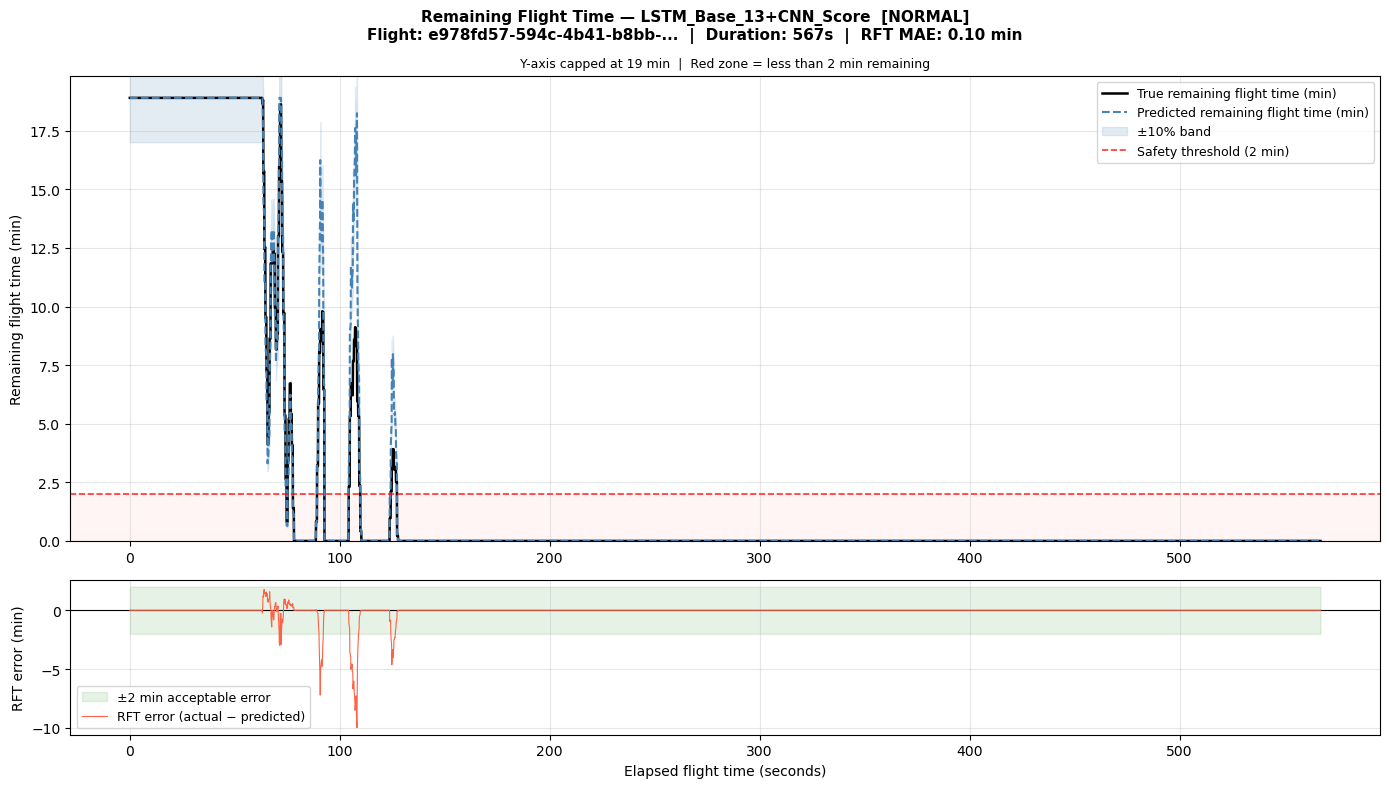

Saved: rft_FIXED_LSTM_Base_13_CNN_Score_normal.png

✓ All fixed RFT plots saved.


In [207]:
# ============================================================
# ACTION 4: Fixed RFT plots — real time axis
# Replaces the 4 broken XGBoost RFT plots
# Also generates RFT plots for LSTM
# ============================================================

def plot_rft_fixed(pred_df, run_name,
                   flight_label="abnormal",
                   save_dir=PLOT_DIR):
    """
    RFT plot with:
    - Real elapsed seconds on x-axis (not scaled)
    - Realistic y-axis cap (2x longest flight in minutes)
    - Safety threshold line at 2 minutes
    - Residual error panel below
    """
    # Attach real time
    pred_real = attach_real_time(pred_df.copy(), raw_test)

    # Merge battery_remaining from test_df
    pred_real = pred_real.merge(
        test_df[["log_id","time_s",
                 "battery_status__remaining"]],
        on=["log_id","time_s"],
        how="left"
    )

    label_df = pred_real[
        pred_real["dataset_label"] == flight_label
    ]
    if len(label_df) == 0:
        print(f"No {flight_label} flights found")
        return

    # Cap at 2x longest flight duration in minutes
    max_dur_min = float(
        label_df.groupby("log_id")["time_s_real"].max().max()
    ) / 60
    cap = min(max_dur_min * 2, 60)

    eps = 1e-6
    label_df = label_df.copy()
    label_df["rft_pred_min"] = (
        label_df["battery_status__remaining"] /
        (label_df["y_pred"] / 60 + eps)
    ).clip(0, cap)
    label_df["rft_true_min"] = (
        label_df["battery_status__remaining"] /
        (label_df["y_true"] / 60 + eps)
    ).clip(0, cap)

    # Pick longest flight
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[
        label_df["log_id"] == fid
    ].sort_values("time_s_real")

    t        = flight["time_s_real"].values
    rft_pred = flight["rft_pred_min"].values
    rft_true = flight["rft_true_min"].values
    rft_error= rft_true - rft_pred
    rft_mae  = mean_absolute_error(rft_true, rft_pred)

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        gridspec_kw={"height_ratios": [3, 1]}
    )
    fig.suptitle(
        f"Remaining Flight Time — {run_name}  "
        f"[{flight_label.upper()}]\n"
        f"Flight: {fid[:24]}...  |  "
        f"Duration: {t[-1]:.0f}s  |  "
        f"RFT MAE: {rft_mae:.2f} min",
        fontsize=11, fontweight="bold"
    )

    # Panel 1: RFT curves
    ax = axes[0]
    ax.plot(t, rft_true, color="black",
            linewidth=1.8, label="True remaining flight time (min)")
    ax.plot(t, rft_pred, color="steelblue",
            linewidth=1.5, linestyle="--",
            label="Predicted remaining flight time (min)")
    ax.fill_between(t,
                    np.maximum(rft_pred * 0.9, 0),
                    rft_pred * 1.1,
                    alpha=0.15, color="steelblue",
                    label="±10% band")
    ax.axhline(2, color="red", linestyle="--",
               linewidth=1.2, alpha=0.8,
               label="Safety threshold (2 min)")
    ax.axhspan(0, 2, alpha=0.04, color="red")
    ax.set_ylabel("Remaining flight time (min)", fontsize=10)
    ax.set_ylim(0, cap * 1.05)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_title(
        f"Y-axis capped at {cap:.0f} min  |  "
        f"Red zone = less than 2 min remaining",
        fontsize=9
    )

    # Panel 2: RFT error over time
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(t, -2, 2, alpha=0.1, color="green",
                     label="±2 min acceptable error")
    ax2.plot(t, rft_error, color="tomato",
             linewidth=0.8,
             label="RFT error (actual − predicted)")
    ax2.set_xlabel("Elapsed flight time (seconds)", fontsize=10)
    ax2.set_ylabel("RFT error (min)", fontsize=10)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    fname = (save_dir /
             f"rft_FIXED_{run_name.replace('+','_')}"
             f"_{flight_label}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")
    plt.close()


# Generate fixed RFT plots for XGBoost and LSTM
RUNS_RFT = [
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
]

for run in RUNS_RFT:
    print(f"\nGenerating RFT: {run}")

    # Build pred_df
    if run in tree_preds:
        pred_df = test_df[[
            "log_id","dataset_label","time_s",TARGET
        ]].copy()
        pred_df = pred_df.rename(columns={TARGET:"y_true"})
        pred_df["y_pred"] = np.clip(tree_preds[run], 0, None)
    elif run in seq_preds:
        pred_df = seq_preds[run].copy()
        pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)
    else:
        print(f"  SKIP — {run} not found")
        continue

    for label in ["abnormal", "normal"]:
        plot_rft_fixed(pred_df, run, label)

print("\n✓ All fixed RFT plots saved.")


Generating energy plots: BiLSTM_Base_13


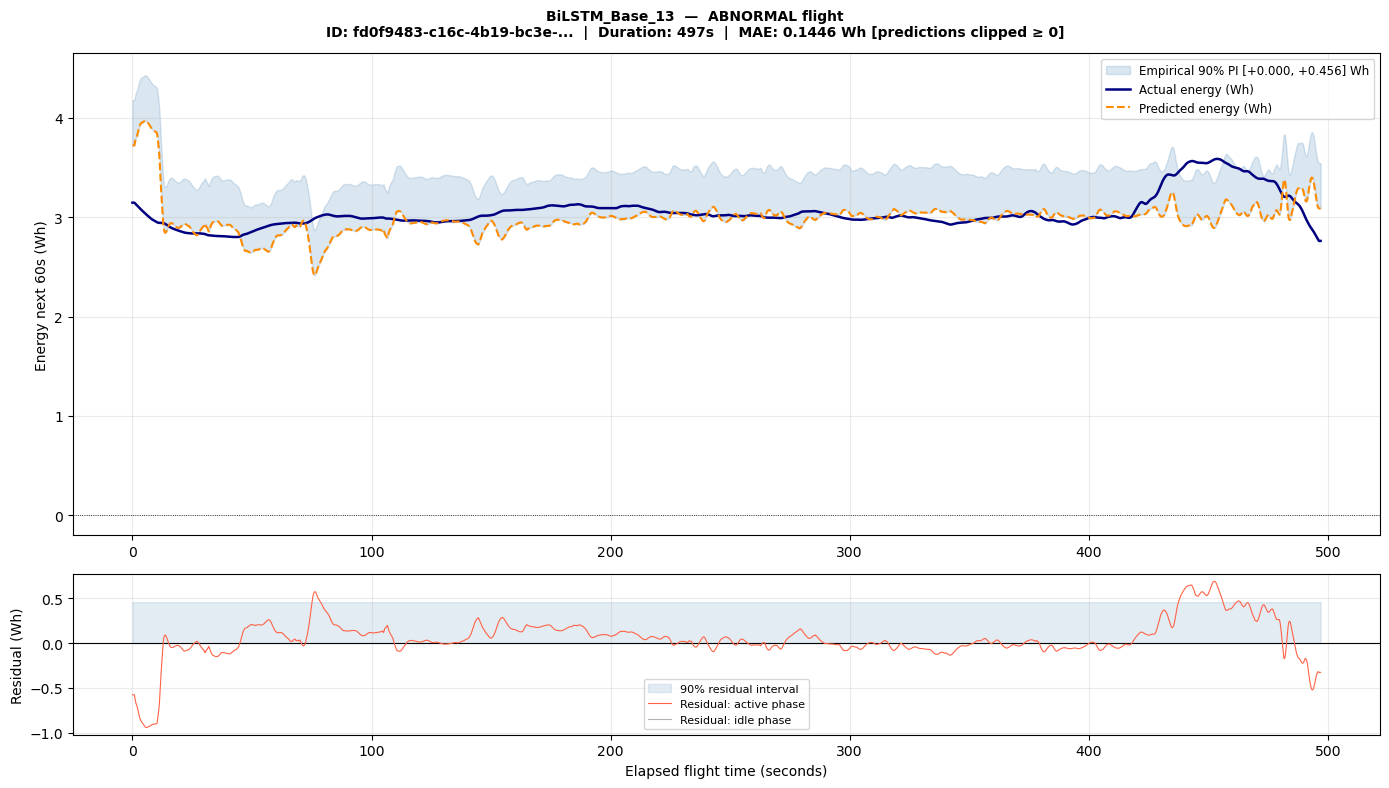

Saved: energy_v2_BiLSTM_Base_13_abnormal_clipped.png


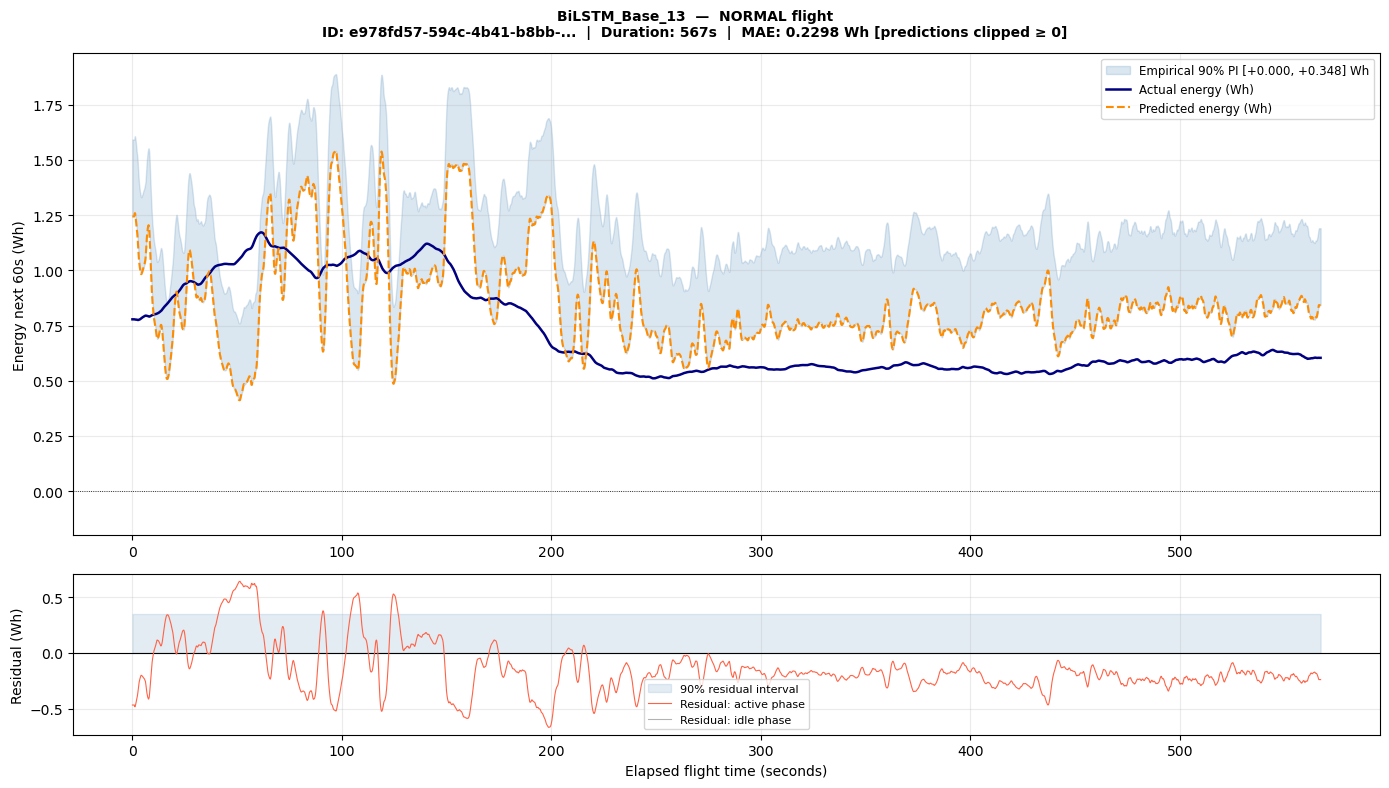

Saved: energy_v2_BiLSTM_Base_13_normal_clipped.png

Generating energy plots: BiLSTM_Base_13+CNN_Score


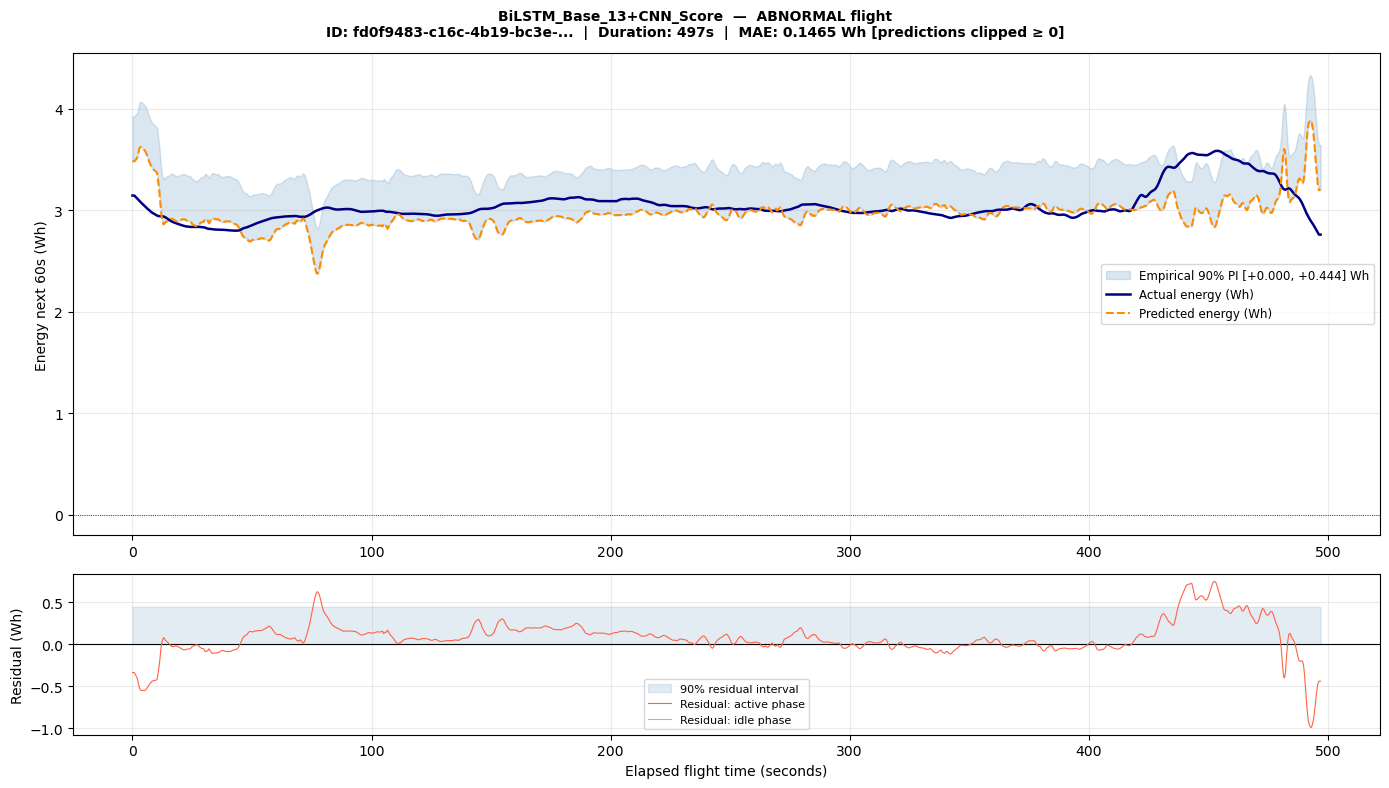

Saved: energy_v2_BiLSTM_Base_13_CNN_Score_abnormal_clipped.png


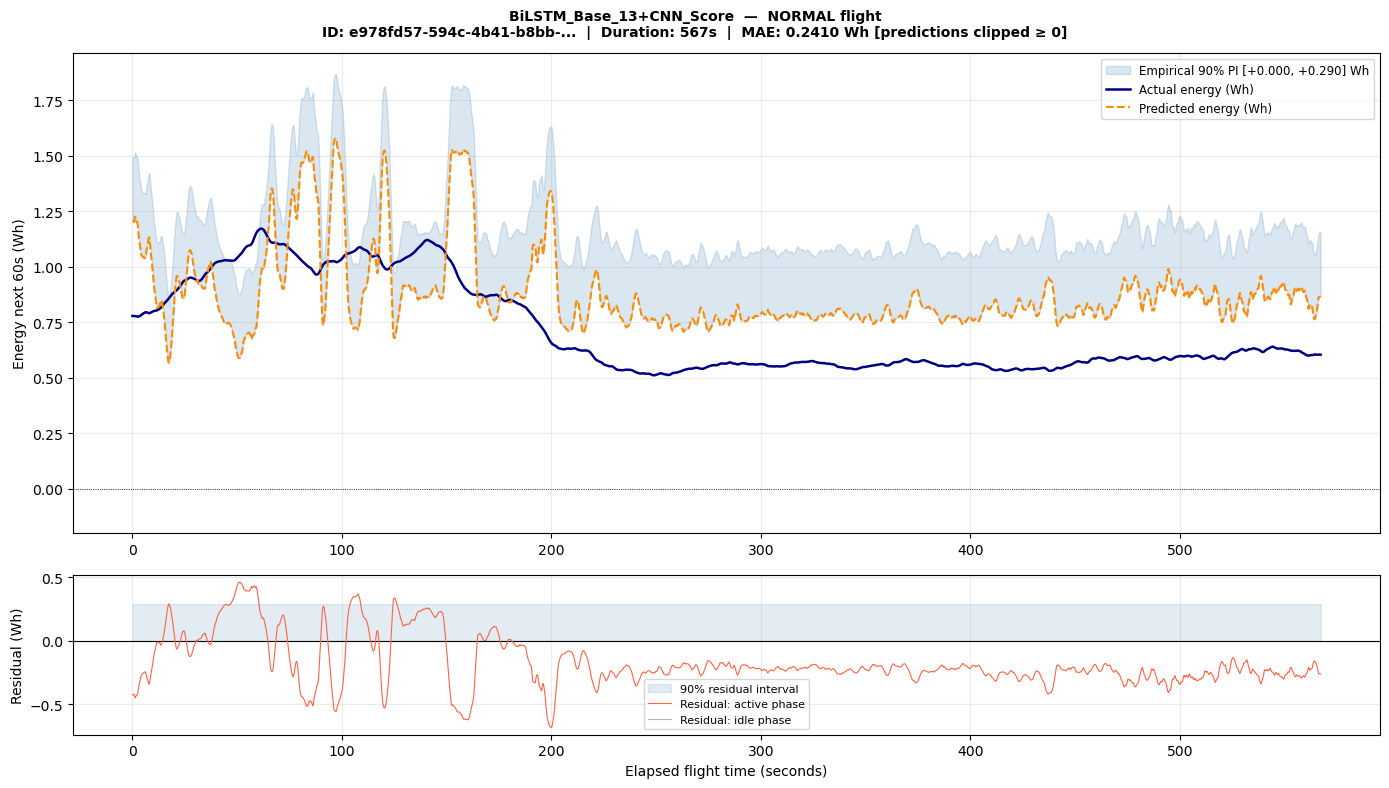

Saved: energy_v2_BiLSTM_Base_13_CNN_Score_normal_clipped.png

✓ BiLSTM energy plots saved.


In [208]:
# ============================================================
# ACTION 5: BiLSTM energy prediction plots
# Uses the same plot_energy_v2 function already defined
# ============================================================

BILSTM_RUNS = [
    "BiLSTM_Base_13",
    "BiLSTM_Base_13+CNN_Score",
]

for run in BILSTM_RUNS:
    if run not in seq_preds:
        print(f"SKIP — {run} not in seq_preds")
        print(f"Available: {list(seq_preds.keys())}")
        continue

    pred_df = seq_preds[run].copy()
    pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)

    print(f"\nGenerating energy plots: {run}")
    for label in ["abnormal", "normal"]:
        plot_energy_v2(pred_df, raw_test, run,
                       label, clip_preds=True)

print("\n✓ BiLSTM energy plots saved.")

In [209]:
# ============================================================
# ACTION 6: Full RFT summary table — all models
# RFT MAE and RMSE in minutes for normal and abnormal flights
# ============================================================

rft_rows = []

ALL_PRED_DFS = {}

# Build pred_df for all tree models
for run, y_pred_arr in tree_preds.items():
    pred_df = test_df[[
        "log_id","dataset_label","time_s",TARGET
    ]].copy()
    pred_df = pred_df.rename(columns={TARGET:"y_true"})
    pred_df["y_pred"] = np.clip(y_pred_arr, 0, None)
    ALL_PRED_DFS[run] = pred_df

# Add sequence models
for run, pred_df in seq_preds.items():
    df = pred_df.copy()
    df["y_pred"] = df["y_pred"].clip(lower=0)
    ALL_PRED_DFS[run] = df

# Compute RFT metrics for all
for run, pred_df in ALL_PRED_DFS.items():

    # Attach real time and battery remaining
    pred_real = attach_real_time(pred_df.copy(), raw_test)
    pred_real = pred_real.merge(
        test_df[["log_id","time_s",
                 "battery_status__remaining"]],
        on=["log_id","time_s"],
        how="left"
    )

    eps = 1e-6
    pred_real["rft_pred_min"] = (
        pred_real["battery_status__remaining"] /
        (pred_real["y_pred"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_true_min"] = (
        pred_real["battery_status__remaining"] /
        (pred_real["y_true"] / 60 + eps)
    ).clip(0, 60)

    for lbl in ["normal", "abnormal"]:
        mask = pred_real["dataset_label"] == lbl
        if mask.sum() == 0:
            continue
        sub = pred_real[mask]
        mae  = mean_absolute_error(
            sub["rft_true_min"], sub["rft_pred_min"])
        rmse = np.sqrt(mean_squared_error(
            sub["rft_true_min"], sub["rft_pred_min"]))
        rft_rows.append({
            "Model":        run,
            "Flight_type":  lbl,
            "RFT_MAE_min":  round(mae,  3),
            "RFT_RMSE_min": round(rmse, 3),
            "n_rows":       int(mask.sum()),
        })

rft_table = pd.DataFrame(rft_rows)

print("=" * 65)
print("RFT SUMMARY TABLE — ALL MODELS")
print("(Lower = better RFT prediction accuracy)")
print("=" * 65)

for lbl in ["normal", "abnormal"]:
    sub = rft_table[
        rft_table["Flight_type"] == lbl
    ].sort_values("RFT_MAE_min").reset_index(drop=True)
    sub.index += 1
    print(f"\n--- {lbl.upper()} FLIGHTS ---")
    print(sub[["Model","RFT_MAE_min",
               "RFT_RMSE_min","n_rows"]].to_string())

rft_table.to_csv(
    OUTPUT_DIR / "rft_full_summary.csv", index=False
)
print(f"\n✓ Saved: rft_full_summary.csv")

RFT SUMMARY TABLE — ALL MODELS
(Lower = better RFT prediction accuracy)

--- NORMAL FLIGHTS ---
                                 Model  RFT_MAE_min  RFT_RMSE_min  n_rows
1               LSTM_Base_13+CNN_Score        0.728         2.895   18239
2             BiLSTM_Base_13+CNN_Score        0.734         2.840   18239
3                       BiLSTM_Base_13        0.744         2.897   18239
4                         LSTM_Base_13        0.778         2.965   18239
5                      XGBoost_Base_13        0.827         3.186   18389
6            XGBoost_Base_13+CNN_Score        0.841         3.201   18389
7                 RandomForest_Base_13        1.020         3.791   18389
8       RandomForest_Base_13+CNN_Score        1.020         3.789   18389
9             LinearRegression_Base_13        1.137         4.708   18389
10  LinearRegression_Base_13+CNN_Score        1.137         4.709   18389

--- ABNORMAL FLIGHTS ---
                                 Model  RFT_MAE_min  RFT_RMSE_mi

In [210]:
# ============================================================
# REMAINING FLIGHT TIME — COMPREHENSIVE ANALYSIS
# Proves whether anomaly score helps or hurts RFT estimation
# Includes: statistical comparison, flight-level plots,
# error distribution plots, scatter plots, and summary
# ============================================================

import matplotlib.gridspec as gridspec
from scipy import stats

RFT_PLOT_DIR = PLOT_DIR / "rft_analysis"
RFT_PLOT_DIR.mkdir(parents=True, exist_ok=True)

# ── Build full pred_df for all models with RFT columns ────────
def build_rft_df(run_name):
    """
    Builds a dataframe with RFT true and predicted for every row.
    Uses raw_test for unscaled battery_remaining and real time_s.
    """
    if run_name in tree_preds:
        pred_df = test_df[["log_id","dataset_label",
                            "time_s", TARGET]].copy()
        pred_df = pred_df.rename(columns={TARGET:"y_true"})
        pred_df["y_pred"] = np.clip(tree_preds[run_name], 0, None)
    elif run_name in seq_preds:
        pred_df = seq_preds[run_name].copy()
        pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)
    else:
        return None

    # Attach real time from raw_test
    result = attach_real_time(pred_df, raw_test)

    # Merge unscaled battery_remaining from raw_test
    result = result.merge(
        raw_test[["log_id","time_s","battery_status__remaining"]]
        .rename(columns={"battery_status__remaining":"battery_real",
                         "time_s":"time_s_raw"}),
        left_on=["log_id","time_s_real"],
        right_on=["log_id","time_s_raw"],
        how="left"
    )

    # Fill missing battery values within each flight
    result["battery_real"] = (
        result.groupby("log_id")["battery_real"]
        .transform(lambda x: x.ffill().bfill())
    )
    result["battery_real"] = result["battery_real"].fillna(0.5)

    # Compute RFT — clip to realistic max 60 minutes
    eps = 1e-6
    result["rft_true_min"]  = (result["battery_real"] /
                                (result["y_true"] / 60 + eps)
                               ).clip(0, 60)
    result["rft_pred_min"]  = (result["battery_real"] /
                                (result["y_pred"] / 60 + eps)
                               ).clip(0, 60)
    result["rft_error_min"] = (result["rft_true_min"] -
                                result["rft_pred_min"])
    result["rft_abs_error"] = result["rft_error_min"].abs()

    return result


# Build for the 4 most important runs
RUNS_TO_ANALYSE = [
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
]

rft_dfs = {}
for run in RUNS_TO_ANALYSE:
    df = build_rft_df(run)
    if df is not None:
        rft_dfs[run] = df
        print(f"Built RFT df: {run}  rows={len(df):,}")

print(f"\n✓ RFT dataframes built for {len(rft_dfs)} models")

Built RFT df: LSTM_Base_13  rows=23,210
Built RFT df: LSTM_Base_13+CNN_Score  rows=23,210
Built RFT df: XGBoost_Base_13  rows=23,390
Built RFT df: XGBoost_Base_13+CNN_Score  rows=23,390

✓ RFT dataframes built for 4 models


In [ ]:
# ============================================================
# PLOT 1: RFT Error Distribution — Base vs CNN Score
# Shows the full distribution of errors for each model
# with and without the anomaly score
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Remaining Flight Time Error Distribution\n"
    "Base Features vs CNN Anomaly Score Added\n"
    "Negative = underestimated RFT  |  Positive = overestimated",
    fontsize=13, fontweight="bold"
)

pairs = [
    ("LSTM_Base_13",           "LSTM_Base_13+CNN_Score",
     "LSTM",   "NORMAL",   axes[0,0]),
    ("LSTM_Base_13",           "LSTM_Base_13+CNN_Score",
     "LSTM",   "ABNORMAL", axes[0,1]),
    ("XGBoost_Base_13",        "XGBoost_Base_13+CNN_Score",
     "XGBoost","NORMAL",   axes[1,0]),
    ("XGBoost_Base_13",        "XGBoost_Base_13+CNN_Score",
     "XGBoost","ABNORMAL", axes[1,1]),
]

for base_run, cnn_run, model_name, flight_type, ax in pairs:
    if base_run not in rft_dfs or cnn_run not in rft_dfs:
        continue

    lbl = flight_type.lower()
    base_err = rft_dfs[base_run][
        rft_dfs[base_run]["dataset_label"]==lbl
    ]["rft_error_min"].values
    cnn_err  = rft_dfs[cnn_run][
        rft_dfs[cnn_run]["dataset_label"]==lbl
    ]["rft_error_min"].values

    base_mae = np.abs(base_err).mean()
    cnn_mae  = np.abs(cnn_err).mean()
    diff     = base_mae - cnn_mae
    color    = "#1976D2"  # blue=base  red=cnn
    color2   = "#E53935"

    # Clip for display clarity
    clip = 30
    base_clipped = np.clip(base_err, -clip, clip)
    cnn_clipped  = np.clip(cnn_err,  -clip, clip)

    ax.hist(base_clipped, bins=80, alpha=0.55,
            color=color, label=f"Base  (MAE={base_mae:.2f} min)",
            density=True)
    ax.hist(cnn_clipped, bins=80, alpha=0.55,
            color=color2, label=f"+CNN  (MAE={cnn_mae:.2f} min)",
            density=True)

    ax.axvline(0, color="black", linewidth=1.2, linestyle="--",
               label="Perfect prediction")
    ax.axvline(base_err.mean(), color=color,
               linewidth=1.5, linestyle="-.",
               label=f"Base mean={base_err.mean():.2f}")
    ax.axvline(cnn_err.mean(),  color=color2,
               linewidth=1.5, linestyle="-.",
               label=f"+CNN mean={cnn_err.mean():.2f}")

    sign = "▼ CNN helps" if diff > 0.05 else \
           ("▲ CNN hurts" if diff < -0.05 else "≈ no change")
    ax.set_title(
        f"{model_name} — {flight_type} flights\n"
        f"Δ MAE = {diff:+.3f} min  {sign}",
        fontsize=10, fontweight="bold"
    )
    ax.set_xlabel("RFT error (actual − predicted) minutes",
                  fontsize=9)
    ax.set_ylabel("Density", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-clip, clip)

plt.tight_layout()
fname = RFT_PLOT_DIR / "rft_error_distribution.png"
plt.savefig(fname, dpi=250, bbox_inches="tight")
plt.show()
print(f"Saved: {fname.name}")
plt.close()

In [ ]:
# ============================================================
# PLOT 2: RFT Time Series — Best flight per model
# Shows predicted vs actual RFT over elapsed flight time
# Two-panel: normal and abnormal side by side
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    "Remaining Flight Time — Predicted vs Actual\n"
    "LSTM Base vs LSTM+CNN  |  Best flight per category",
    fontsize=13, fontweight="bold"
)

configs = [
    ("LSTM_Base_13",         "normal",   axes[0,0], "#1976D2"),
    ("LSTM_Base_13+CNN_Score","normal",  axes[0,1], "#E53935"),
    ("LSTM_Base_13",         "abnormal", axes[1,0], "#1976D2"),
    ("LSTM_Base_13+CNN_Score","abnormal",axes[1,1], "#E53935"),
]

for run_name, flight_label, ax, color in configs:
    if run_name not in rft_dfs:
        continue

    df = rft_dfs[run_name]
    label_df = df[df["dataset_label"]==flight_label]
    if len(label_df) == 0:
        continue

    # Pick longest flight
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[
        label_df["log_id"]==fid
    ].sort_values("time_s_real")

    t        = flight["time_s_real"].values
    rft_true = flight["rft_true_min"].values
    rft_pred = flight["rft_pred_min"].values
    mae      = float(np.abs(rft_true - rft_pred).mean())

    # Compute PI from all flights of this label
    all_err = label_df["rft_error_min"].values
    pi_low  = float(np.percentile(all_err,  5))
    pi_high = float(np.percentile(all_err, 95))

    ax.fill_between(
        t,
        np.clip(rft_pred + pi_low,  0, None),
        np.clip(rft_pred + pi_high, 0, None),
        alpha=0.15, color=color,
        label=f"90% prediction interval"
    )
    ax.plot(t, rft_true, color="black", linewidth=2,
            label="True RFT (min)")
    ax.plot(t, rft_pred, color=color, linewidth=1.8,
            linestyle="--", label="Predicted RFT (min)")
    ax.axhline(2, color="red", linestyle=":",
               linewidth=1.2, label="Safety threshold (2 min)")
    ax.axhspan(0, 2, alpha=0.05, color="red")

    feat_label = "Base 13 features" \
                 if "CNN" not in run_name \
                 else "Base 13 + CNN score"
    ax.set_title(
        f"{'LSTM'} — {flight_label.upper()}  |  {feat_label}\n"
        f"Flight MAE: {mae:.2f} min  |  "
        f"Duration: {t[-1]:.0f}s",
        fontsize=9, fontweight="bold"
    )
    ax.set_xlabel("Elapsed flight time (seconds)", fontsize=9)
    ax.set_ylabel("Remaining flight time (min)", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, None)

plt.tight_layout()
fname = RFT_PLOT_DIR / "rft_timeseries_lstm_comparison.png"
plt.savefig(fname, dpi=250, bbox_inches="tight")
plt.show()
print(f"Saved: {fname.name}")
plt.close()

In [ ]:
# ============================================================
# PLOT 3: Flight-level scatter — True RFT vs Predicted RFT
# Each dot = one flight
# Perfect model = all dots on diagonal
# Shows how consistent each model is across all flights
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(
    "Flight-Level RFT: True vs Predicted\n"
    "Each dot = mean RFT across one flight  |  "
    "Diagonal = perfect prediction",
    fontsize=12, fontweight="bold"
)

plot_configs = [
    ("LSTM_Base_13",            "normal",   axes[0,0], "#1976D2"),
    ("LSTM_Base_13+CNN_Score",  "normal",   axes[0,1], "#E53935"),
    ("LSTM_Base_13",            "abnormal", axes[1,0], "#1976D2"),
    ("LSTM_Base_13+CNN_Score",  "abnormal", axes[1,1], "#E53935"),
]

for run_name, flight_label, ax, color in plot_configs:
    if run_name not in rft_dfs:
        continue

    df = rft_dfs[run_name]
    label_df = df[df["dataset_label"]==flight_label]

    # Aggregate to flight level
    flight_agg = (
        label_df.groupby("log_id")
        .agg(
            rft_true_mean  = ("rft_true_min",  "mean"),
            rft_pred_mean  = ("rft_pred_min",  "mean"),
            rft_mae        = ("rft_abs_error",  "mean"),
        )
        .reset_index()
    )

    x = flight_agg["rft_true_mean"].values
    y = flight_agg["rft_pred_mean"].values
    mae_flight = float(np.abs(x - y).mean())

    # Scatter
    sc = ax.scatter(x, y, c=flight_agg["rft_mae"],
                    cmap="RdYlGn_r", s=100,
                    edgecolors="black", linewidths=0.5,
                    vmin=0, vmax=10, zorder=3)

    # Perfect prediction diagonal
    lim = max(x.max(), y.max()) * 1.05
    ax.plot([0, lim], [0, lim], "k--",
            linewidth=1, label="Perfect prediction", zorder=2)

    # Regression line
    if len(x) > 2:
        slope, intercept, r, p, _ = stats.linregress(x, y)
        x_line = np.linspace(0, lim, 100)
        ax.plot(x_line, slope*x_line + intercept,
                color=color, linewidth=1.5, alpha=0.7,
                label=f"Trend (R={r:.2f})", zorder=2)

    plt.colorbar(sc, ax=ax, label="Per-flight MAE (min)")

    feat_label = "Base 13" if "CNN" not in run_name \
                 else "Base 13 + CNN"
    ax.set_title(
        f"LSTM — {flight_label.upper()}  |  {feat_label}\n"
        f"Flight-level MAE: {mae_flight:.2f} min  |  "
        f"n={len(flight_agg)} flights",
        fontsize=9, fontweight="bold"
    )
    ax.set_xlabel("True mean RFT (min)", fontsize=9)
    ax.set_ylabel("Predicted mean RFT (min)", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
fname = RFT_PLOT_DIR / "rft_scatter_flight_level.png"
plt.savefig(fname, dpi=250, bbox_inches="tight")
plt.show()
print(f"Saved: {fname.name}")
plt.close()

In [ ]:
# ============================================================
# PLOT 4: Summary bar chart — all models RFT MAE
# Normal and abnormal side by side
# With and without CNN score shown as solid vs hatched
# ============================================================

RUNS_SUMMARY = [
    ("LSTM_Base_13",             "LSTM",          "Base"),
    ("LSTM_Base_13+CNN_Score",   "LSTM",          "+CNN"),
    ("XGBoost_Base_13",          "XGBoost",       "Base"),
    ("XGBoost_Base_13+CNN_Score","XGBoost",       "+CNN"),
    ("BiLSTM_Base_13",           "BiLSTM",        "Base"),
    ("BiLSTM_Base_13+CNN_Score", "BiLSTM",        "+CNN"),
]

# Build summary stats
summary_rows = []
for run_name, model, feat in RUNS_SUMMARY:
    if run_name not in rft_dfs:
        continue
    df = rft_dfs[run_name]
    for lbl in ["normal","abnormal"]:
        sub = df[df["dataset_label"]==lbl]
        if len(sub) == 0: continue
        summary_rows.append({
            "run":        run_name,
            "model":      model,
            "feat":       feat,
            "flight":     lbl,
            "RFT_MAE":    round(sub["rft_abs_error"].mean(), 3),
            "RFT_P95":    round(sub["rft_abs_error"].quantile(0.95), 3),
            "n_flights":  sub["log_id"].nunique(),
        })

summary = pd.DataFrame(summary_rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    "RFT MAE Summary — All Models\n"
    "Solid = Base features  |  Hatched = + CNN anomaly score",
    fontsize=12, fontweight="bold"
)

colors_m = {
    "LSTM":   "#8E24AA",
    "BiLSTM": "#E53935",
    "XGBoost":"#1976D2",
}

for ax, flight_label in zip(axes, ["normal","abnormal"]):
    sub = summary[summary["flight"]==flight_label]

    models   = ["LSTM","BiLSTM","XGBoost"]
    x        = np.arange(len(models))
    w        = 0.35

    for fi, feat in enumerate(["Base","+CNN"]):
        maes   = []
        p95s   = []
        for m in models:
            row = sub[(sub["model"]==m) & (sub["feat"]==feat)]
            maes.append(float(row["RFT_MAE"]) if len(row) else np.nan)
            p95s.append(float(row["RFT_P95"]) if len(row) else np.nan)

        offset = (fi - 0.5) * w
        hatch  = "" if feat == "Base" else "///"

        bars = ax.bar(
            x + offset, maes, w,
            color=[colors_m[m] for m in models],
            hatch=hatch, alpha=0.85,
            edgecolor="white",
            label=feat
        )
        # Error bars showing P95
        ax.errorbar(
            x + offset, maes,
            yerr=[np.zeros(len(maes)),
                  [max(0, p-m) if not np.isnan(p) and not np.isnan(m)
                   else 0
                   for p,m in zip(p95s,maes)]],
            fmt="none", color="black",
            capsize=4, linewidth=1.2,
            label="_nolegend_"
        )
        for bar, val in zip(bars, maes):
            if not np.isnan(val):
                ax.text(
                    bar.get_x()+bar.get_width()/2,
                    val + 0.05,
                    f"{val:.2f}",
                    ha="center", va="bottom",
                    fontsize=8, fontweight="bold"
                )

    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=10)
    ax.set_ylabel("RFT MAE (minutes)", fontsize=10)
    ax.set_title(
        f"{flight_label.upper()} Flights\n"
        f"Error bars show 95th percentile",
        fontsize=10, fontweight="bold"
    )
    ax.legend(fontsize=9, title="Feature set")
    ax.grid(True, alpha=0.3, axis="y")

    # Add safety annotation
    ax.axhline(2, color="red", linestyle="--",
               linewidth=1, alpha=0.7,
               label="2-min safety margin")

plt.tight_layout()
fname = RFT_PLOT_DIR / "rft_mae_summary_bar.png"
plt.savefig(fname, dpi=250, bbox_inches="tight")
plt.show()
print(f"Saved: {fname.name}")
plt.close()

In [ ]:
# ============================================================
# FINAL PROOF TABLE — Statistical significance test
# Wilcoxon signed-rank test: does CNN score significantly
# change RFT error compared to base features?
# ============================================================

from scipy.stats import wilcoxon

print("=" * 75)
print("STATISTICAL PROOF: Does CNN score significantly change RFT accuracy?")
print("Wilcoxon signed-rank test (non-parametric paired test)")
print("p < 0.05 = statistically significant change")
print("=" * 75)

test_pairs = [
    ("LSTM_Base_13",    "LSTM_Base_13+CNN_Score",    "LSTM",    "normal"),
    ("LSTM_Base_13",    "LSTM_Base_13+CNN_Score",    "LSTM",    "abnormal"),
    ("XGBoost_Base_13", "XGBoost_Base_13+CNN_Score", "XGBoost", "normal"),
    ("XGBoost_Base_13", "XGBoost_Base_13+CNN_Score", "XGBoost", "abnormal"),
]

for base_run, cnn_run, model, lbl in test_pairs:
    if base_run not in rft_dfs or cnn_run not in rft_dfs:
        continue

    base_df = rft_dfs[base_run][
        rft_dfs[base_run]["dataset_label"]==lbl
    ]
    cnn_df  = rft_dfs[cnn_run][
        rft_dfs[cnn_run]["dataset_label"]==lbl
    ]

    # Align on index
    n       = min(len(base_df), len(cnn_df))
    base_e  = base_df["rft_abs_error"].values[:n]
    cnn_e   = cnn_df["rft_abs_error"].values[:n]

    base_mae = base_e.mean()
    cnn_mae  = cnn_e.mean()
    diff     = base_mae - cnn_mae

    try:
        stat, p = wilcoxon(base_e, cnn_e)
        sig = "YES ✓" if p < 0.05 else "NO ✗"
    except:
        p, sig = np.nan, "N/A"

    direction = "CNN HELPS" if diff > 0.05 else \
                ("CNN HURTS" if diff < -0.05 else "NO CHANGE")

    print(f"\n{model} — {lbl.upper()}:")
    print(f"  Base MAE : {base_mae:.3f} min")
    print(f"  CNN MAE  : {cnn_mae:.3f} min")
    print(f"  Δ        : {diff:+.3f} min  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")

In [ ]:
# ============================================================
# SAVE COMPLETE RFT PROOF TABLE AS CSV
# ============================================================

proof_rows = []
for run_name in RUNS_TO_ANALYSE + [
    "BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score",
    "RandomForest_Base_13", "RandomForest_Base_13+CNN_Score",
    "LinearRegression_Base_13"
]:
    if run_name not in rft_dfs:
        continue
    df = rft_dfs[run_name]
    for lbl in ["normal","abnormal"]:
        sub = df[df["dataset_label"]==lbl]
        if len(sub) == 0: continue
        proof_rows.append({
            "model":         run_name,
            "flight_type":   lbl,
            "n_rows":        len(sub),
            "n_flights":     sub["log_id"].nunique(),
            "RFT_MAE_min":   round(sub["rft_abs_error"].mean(), 4),
            "RFT_RMSE_min":  round(np.sqrt((sub["rft_error_min"]**2)
                                           .mean()), 4),
            "RFT_P95_min":   round(sub["rft_abs_error"]
                                   .quantile(0.95), 4),
            "mean_error_dir":round(sub["rft_error_min"].mean(), 4),
            "overpredict_%": round((sub["rft_pred_min"] >
                                    sub["rft_true_min"]).mean()*100, 2),
        })

proof_df = pd.DataFrame(proof_rows)
proof_df.to_csv(OUTPUT_DIR / "rft_proof_table.csv", index=False)

print("\n" + "="*75)
print("FINAL RFT PROOF TABLE")
print("="*75)
for lbl in ["normal","abnormal"]:
    sub = proof_df[proof_df["flight_type"]==lbl]\
          .sort_values("RFT_MAE_min").reset_index(drop=True)
    sub.index += 1
    print(f"\n--- {lbl.upper()} FLIGHTS ---")
    print(sub[["model","RFT_MAE_min","RFT_P95_min",
               "mean_error_dir","overpredict_%",
               "n_flights"]].to_string())

print("\n✓ Saved: rft_proof_table.csv")
print(f"✓ Plots saved to: {RFT_PLOT_DIR}")

In [214]:
from sklearn.metrics import mean_absolute_error
import numpy as np

def permutation_importance_seq(model, pred_df_cnn,
                                test_df_ref, feat_cols, target,
                                seq_len=SEQ_LEN, n_repeats=5):
    results = {}
    abn_mask = pred_df_cnn["dataset_label"] == "abnormal"
    baseline_mae = mean_absolute_error(
        pred_df_cnn.loc[abn_mask, "y_true"],
        pred_df_cnn.loc[abn_mask, "y_pred"]
    )
    print(f"Baseline abnormal MAE: {baseline_mae:.4f} Wh")

    for feat in feat_cols:
        importances = []
        for _ in range(n_repeats):
            df_shuffled = test_df_ref.copy()
            df_shuffled[feat] = np.random.permutation(
                df_shuffled[feat].values
            )
            pred_shuf = predict_seq(
                model, df_shuffled, feat_cols, target, seq_len
            )
            pred_shuf["y_pred"] = pred_shuf["y_pred"].clip(lower=0)
            abn_s = pred_shuf["dataset_label"] == "abnormal"
            mae_s = mean_absolute_error(
                pred_shuf.loc[abn_s, "y_true"],
                pred_shuf.loc[abn_s, "y_pred"]
            )
            importances.append(mae_s - baseline_mae)
        results[feat] = float(np.mean(importances))
        print(f"  {feat:<42} Δ={results[feat]:+.4f}")

    return dict(sorted(results.items(),
                        key=lambda x: x[1], reverse=True))


# Load LSTM+CNN checkpoint
lstm_cnn_feat  = "Base_13+CNN_Score"
lstm_cnn_avail = [f for f in FEATURE_SETS[lstm_cnn_feat]
                  if f in test_df.columns]

lstm_model_cnn = LSTMRegressor(
    input_size=len(lstm_cnn_avail)
).to(device)
lstm_model_cnn.load_state_dict(
    torch.load(
        OUTPUT_DIR / "ckpt_LSTM_Base_13+CNN_Score.pt",
        map_location=device, weights_only=True
    )
)
lstm_model_cnn.eval()
print(f"LSTM+CNN loaded — {len(lstm_cnn_avail)} features")
print("Running permutation importance (abnormal flights)...")

perm_imp = permutation_importance_seq(
    model       = lstm_model_cnn,
    pred_df_cnn = seq_preds["LSTM_Base_13+CNN_Score"],
    test_df_ref = test_df,
    feat_cols   = lstm_cnn_avail,
    target      = TARGET,
    n_repeats   = 5
)

print("\nFinal ranking:")
for rank, (feat, delta) in enumerate(perm_imp.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")

LSTM+CNN loaded — 14 features
Running permutation importance (abnormal flights)...
Baseline abnormal MAE: 0.7621 Wh
  battery_status__cell_count                 Δ=+0.4077
  battery_status__current_a                  Δ=+0.1156
  battery_status__current_filtered_a         Δ=+0.7226
  battery_status__discharged_mah             Δ=-0.0039
  battery_status__remaining                  Δ=+0.1016
  battery_status__scale                      Δ=+0.1418
  battery_status__voltage_filtered_v         Δ=+0.1189
  battery_status__voltage_v                  Δ=+0.4125
  cumulative_energy_wh                       Δ=+0.0590
  power_w                                    Δ=+0.6074
  time_s                                     Δ=+0.6744
  voltage_per_cell                           Δ=+0.0257
  voltage_filtered_per_cell                  Δ=+0.0394
  anomaly_score_cnn                          Δ=+0.3733

Final ranking:
   1. battery_status__current_filtered_a         Δ MAE=+0.7226
   2. time_s                       

In [216]:
# ============================================================
# Permutation importance for BiLSTM+CNN_Score
# Same method as LSTM — on abnormal flights only
# ============================================================

bilstm_cnn_feat  = "Base_13+CNN_Score"
bilstm_cnn_avail = [f for f in FEATURE_SETS[bilstm_cnn_feat]
                    if f in test_df.columns]

bilstm_model_cnn = BiLSTMRegressor(
    input_size=len(bilstm_cnn_avail)
).to(device)
bilstm_model_cnn.load_state_dict(
    torch.load(
        OUTPUT_DIR / "ckpt_BiLSTM_Base_13+CNN_Score.pt",
        map_location=device, weights_only=True
    )
)
bilstm_model_cnn.eval()
print(f"BiLSTM+CNN loaded — {len(bilstm_cnn_avail)} features")
print("Running permutation importance for BiLSTM (abnormal flights)...")

perm_imp_bilstm = permutation_importance_seq(
    model       = bilstm_model_cnn,
    pred_df_cnn = seq_preds["BiLSTM_Base_13+CNN_Score"],
    test_df_ref = test_df,
    feat_cols   = bilstm_cnn_avail,
    target      = TARGET,
    n_repeats   = 5
)

print("\nFinal ranking — BiLSTM+CNN:")
for rank, (feat, delta) in enumerate(perm_imp_bilstm.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")

BiLSTM+CNN loaded — 14 features
Running permutation importance for BiLSTM (abnormal flights)...
Baseline abnormal MAE: 0.7533 Wh
  battery_status__cell_count                 Δ=+0.3233
  battery_status__current_a                  Δ=+0.2084
  battery_status__current_filtered_a         Δ=+1.1436
  battery_status__discharged_mah             Δ=+0.0560
  battery_status__remaining                  Δ=-0.0324
  battery_status__scale                      Δ=+0.0211
  battery_status__voltage_filtered_v         Δ=+0.5181
  battery_status__voltage_v                  Δ=+0.2071
  cumulative_energy_wh                       Δ=+0.0348
  power_w                                    Δ=+0.3720
  time_s                                     Δ=+0.6984
  voltage_per_cell                           Δ=-0.0205
  voltage_filtered_per_cell                  Δ=+0.0543
  anomaly_score_cnn                          Δ=+0.1500

Final ranking — BiLSTM+CNN:
   1. battery_status__current_filtered_a         Δ MAE=+1.1436
   2. tim

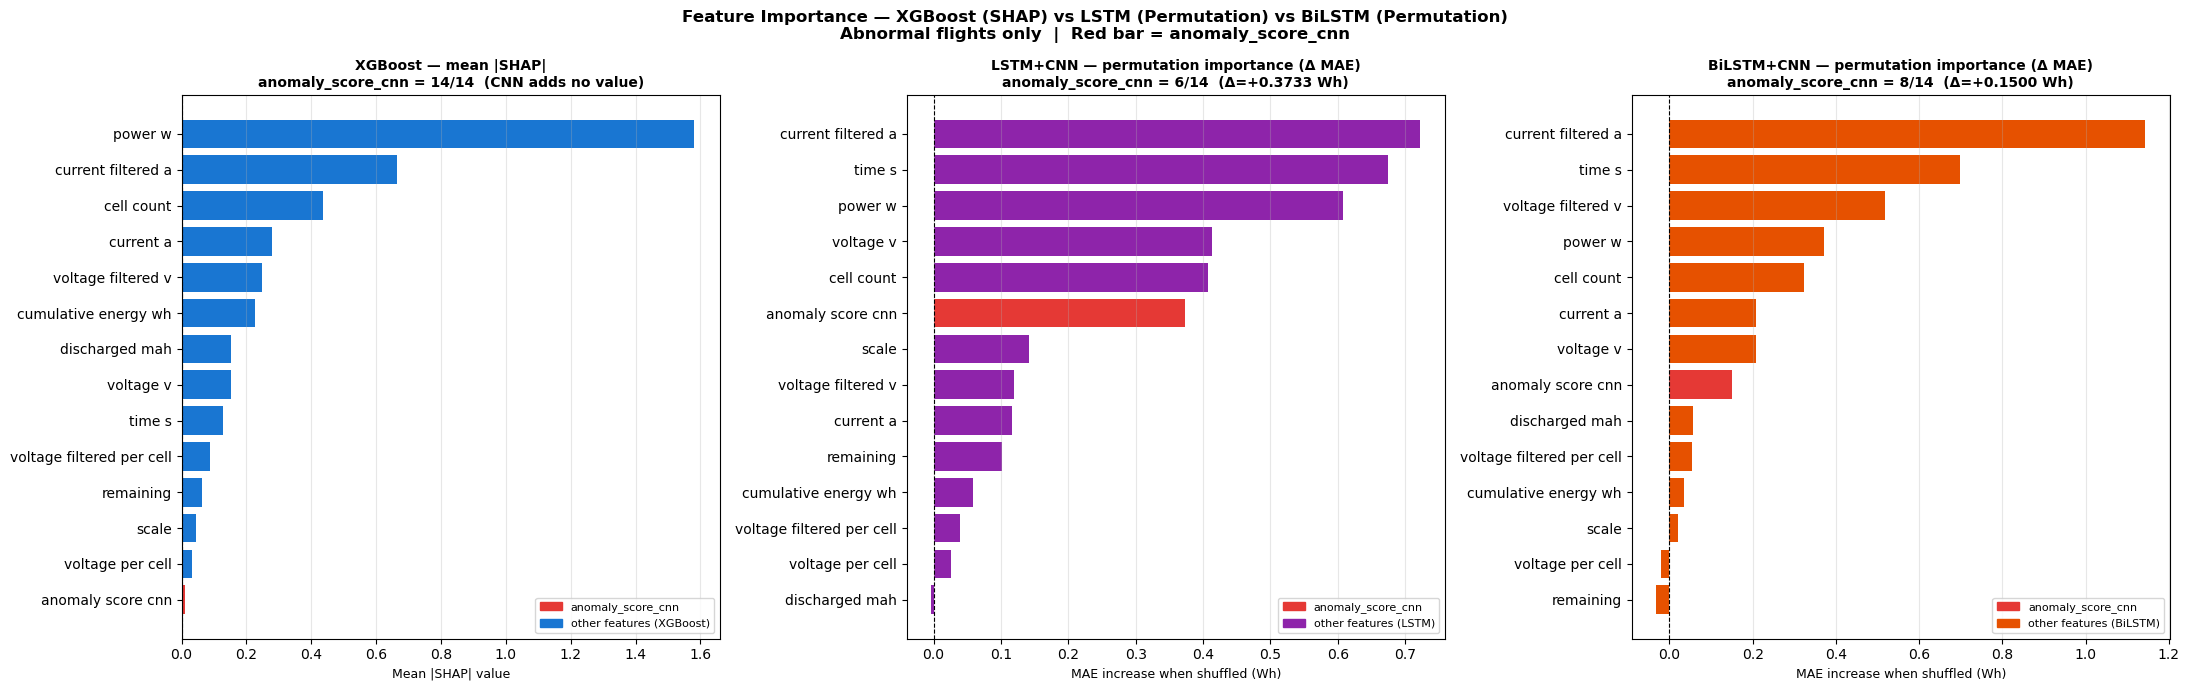

Saved: importance_xgb_shap_vs_lstm_vs_bilstm_permutation.png

KEY FINDING — Role of anomaly_score_cnn across models

  XGBoost SHAP rank : 14/14  SHAP=+0.009  (no benefit)
  LSTM   perm rank  :  6/14  ΔMAE=+0.3733 Wh  (helps)
  BiLSTM perm rank  :  8/14  ΔMAE=+0.1500 Wh  (helps)

  Conclusion: CNN score useful for sequence models only.
  XGBoost ignores it. LSTM/BiLSTM use it temporally.


In [217]:
# ============================================================
# 3-panel: XGBoost SHAP · LSTM perm · BiLSTM perm
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle(
    "Feature Importance — XGBoost (SHAP) vs LSTM (Permutation) "
    "vs BiLSTM (Permutation)\n"
    "Abnormal flights only  |  Red bar = anomaly_score_cnn",
    fontsize=12, fontweight="bold"
)

# ── Shared label cleaner ──────────────────────────────────────
def clean(f):
    return f.replace("battery_status__","").replace("_"," ")

# ── Panel 1: XGBoost SHAP ────────────────────────────────────
shap_vals = {
    "power_w": 1.581,
    "battery_status__current_filtered_a": 0.663,
    "battery_status__cell_count": 0.437,
    "battery_status__current_a": 0.278,
    "battery_status__voltage_filtered_v": 0.248,
    "cumulative_energy_wh": 0.225,
    "battery_status__discharged_mah": 0.153,
    "battery_status__voltage_v": 0.151,
    "time_s": 0.127,
    "voltage_filtered_per_cell": 0.089,
    "battery_status__remaining": 0.062,
    "battery_status__scale": 0.044,
    "voltage_per_cell": 0.031,
    "anomaly_score_cnn": 0.009,
}
shap_s = pd.Series(shap_vals).sort_values(ascending=True)
axes[0].barh(
    [clean(f) for f in shap_s.index],
    shap_s.values,
    color=["#E53935" if "anomaly" in f else "#1976D2"
           for f in shap_s.index]
)
axes[0].set_title(
    "XGBoost — mean |SHAP|\n"
    "anomaly_score_cnn = 14/14  (CNN adds no value)",
    fontsize=10, fontweight="bold"
)
axes[0].set_xlabel("Mean |SHAP| value", fontsize=9)
axes[0].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].grid(True, alpha=0.3, axis="x")

# ── Panel 2: LSTM permutation ─────────────────────────────────
perm_s = pd.Series(perm_imp).sort_values(ascending=True)
axes[1].barh(
    [clean(f) for f in perm_s.index],
    perm_s.values,
    color=["#E53935" if "anomaly" in f else "#8E24AA"
           for f in perm_s.index]
)
lstm_cnn_rank  = list(perm_imp.keys()).index("anomaly_score_cnn") + 1
lstm_cnn_delta = perm_imp["anomaly_score_cnn"]
axes[1].set_title(
    f"LSTM+CNN — permutation importance (Δ MAE)\n"
    f"anomaly_score_cnn = {lstm_cnn_rank}/14  "
    f"(Δ={lstm_cnn_delta:+.4f} Wh)",
    fontsize=10, fontweight="bold"
)
axes[1].set_xlabel("MAE increase when shuffled (Wh)", fontsize=9)
axes[1].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[1].grid(True, alpha=0.3, axis="x")

# ── Panel 3: BiLSTM permutation ───────────────────────────────
perm_bs = pd.Series(perm_imp_bilstm).sort_values(ascending=True)
axes[2].barh(
    [clean(f) for f in perm_bs.index],
    perm_bs.values,
    color=["#E53935" if "anomaly" in f else "#E65100"
           for f in perm_bs.index]
)
bilstm_cnn_rank  = list(perm_imp_bilstm.keys()).index("anomaly_score_cnn") + 1
bilstm_cnn_delta = perm_imp_bilstm["anomaly_score_cnn"]
axes[2].set_title(
    f"BiLSTM+CNN — permutation importance (Δ MAE)\n"
    f"anomaly_score_cnn = {bilstm_cnn_rank}/14  "
    f"(Δ={bilstm_cnn_delta:+.4f} Wh)",
    fontsize=10, fontweight="bold"
)
axes[2].set_xlabel("MAE increase when shuffled (Wh)", fontsize=9)
axes[2].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[2].grid(True, alpha=0.3, axis="x")

# ── Legend (shared) ───────────────────────────────────────────
from matplotlib.patches import Patch
for ax, color, label in zip(
    axes,
    ["#1976D2","#8E24AA","#E65100"],
    ["XGBoost","LSTM","BiLSTM"]
):
    ax.legend(handles=[
        Patch(color="#E53935", label="anomaly_score_cnn"),
        Patch(color=color,     label=f"other features ({label})")
    ], fontsize=8, loc="lower right")

plt.tight_layout()
fname = PLOT_DIR / "importance_xgb_shap_vs_lstm_vs_bilstm_permutation.png"
plt.savefig(fname, dpi=250, bbox_inches="tight")
plt.show()
print(f"Saved: {fname.name}")

# ── Key finding summary ───────────────────────────────────────
print("\n" + "="*65)
print("KEY FINDING — Role of anomaly_score_cnn across models")
print("="*65)
print(f"\n  XGBoost SHAP rank : 14/14  SHAP=+0.009  (no benefit)")
print(f"  LSTM   perm rank  : {lstm_cnn_rank:2d}/14  "
      f"ΔMAE={lstm_cnn_delta:+.4f} Wh  "
      f"({'helps' if lstm_cnn_delta>0 else 'no effect'})")
print(f"  BiLSTM perm rank  : {bilstm_cnn_rank:2d}/14  "
      f"ΔMAE={bilstm_cnn_delta:+.4f} Wh  "
      f"({'helps' if bilstm_cnn_delta>0 else 'no effect'})")
print(f"\n  Conclusion: CNN score useful for sequence models only.")
print(f"  XGBoost ignores it. LSTM/BiLSTM use it temporally.")